## 💾 The data

The data comes from a survey hosted by an HR consultancy, available in `'salaries.csv'`.

#### Each row represents a single employee's salary record for a given year:
- **`work_year`** - The year the salary was paid.  
- **`experience_level`** - Employee experience level:  
  - **`EN`**: Entry-level / Junior  
  - **`MI`**: Mid-level / Intermediate  
  - **`SE`**: Senior / Expert  
  - **`EX`**: Executive / Director  
- **`employment_type`** - Employment type:  
  - **`PT`**: Part-time  
  - **`FT`**: Full-time  
  - **`CT`**: Contract  
  - **`FL`**: Freelance  
- **`job_title`** - The job title during the year.  
- **`salary`** - Gross salary paid (in local currency).  
- **`salary_currency`** - Salary currency (ISO 4217 code).  
- **`salary_in_usd`** - Salary converted to USD using average yearly FX rate.  
- **`employee_residence`** - Employee's primary country of residence (ISO 3166 code).  
- **`remote_ratio`** - Percentage of remote work:  
  - **`0`**: No remote work (<20%)  
  - **`50`**: Hybrid (50%)  
  - **`100`**: Fully remote (>80%)  
- **`company_location`** - Employer's main office location (ISO 3166 code).  
- **`company_size`** - Company size:  
  - **`S`**: Small (<50 employees)  
  - **`M`**: Medium (50–250 employees)  
  - **`L`**: Large (>250 employees)  

Our dataset contains 57,194 rows and 11 columns, with no missing values.

1. work_year - category
2. experience_level - category
3. employment_type - category
4. job_title - category
5. salary - float
6. salary_currency - category
7. salary_in_usd - float
8. employee_residence - category
9. remote_ratio - category
10. company_location - category
11. company_size - category

Three additional variables were created:
                     
1. role_category - category
2. employee_residence_category - category
3. company_location_category - category

- Analyse how factors such as country, experience level, and remote ratio impact salaries for Data Analysts, Data Scientists, and Machine Learning Engineers. In which conditions do professionals achieve the highest salaries?

For all three roles the highest salaries go to Executive/Director level, in North America, with no remote work. North Africa also appears near the top of these charts, but it has 39 rows in the whole dataset, so I do not count it. The group sizes are shown next to every bar further down.

- Develop a predictive model to estimate an employee’s salary (in USD) using experience level, company location, and remote ratio. Which features are the strongest predictors of salary?
- Expand your model by incorporating additional features, such as company size and employment type. Evaluate its performance, what improves, and what doesn’t? Finally, propose new features to make future salary predictions even more accurate future salary predictions even more accurate.

In this project I use five models — Lasso, Bagging with Decision Trees, Random Forest, XGBoost and CatBoost — on three feature sets, with 3, 5 and 9 features. For each set I take the model with the best MAE.

## The best models

**3 features** — experience_level, company_location_category, remote_ratio
Random Forest. MAE 50,112.70 on validation, 50,387.31 on the test set. Of the three, experience level matters most, then company location, then remote ratio.

**5 features** — the same three plus company_size and employment_type
Random Forest. MAE 50,074.86 on validation, 50,310.14 on the test set. The two extra features change the validation MAE by 38 USD, so they add nothing.

**9 features** — work_year, experience_level, employment_type, salary_currency, remote_ratio, company_size, role_category, employee_residence_category, company_location_category
XGBoost. MAE 45,569.99 on validation, 45,597.32 on the test set. The gain comes from role_category and currency.


The three feature sets are closer than they look: 50,113, 50,075 and 45,570 on validation. All of the improvement comes from the third set, and inside each set the five models sit within a few hundred of each other.

The main result of this notebook is not in those numbers. A pivot table of median salaries, grouped by experience level, role and country, reaches 45,554 on the same validation rows, which is indistinguishable from the tuned model. The last part of the notebook goes back over every choice I made along the way and measures what each one was worth. The conclusion is at the end.

# Data Validation

In [651]:
# Import necessary libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
import xgboost as xgb
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.decomposition import PCA

In [652]:
# Load the dataset from a CSV file into a DataFrame
df = pd.read_csv('salaries.csv')

In [653]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57194 entries, 0 to 57193
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           57194 non-null  int64 
 1   experience_level    57194 non-null  object
 2   employment_type     57194 non-null  object
 3   job_title           57194 non-null  object
 4   salary              57194 non-null  int64 
 5   salary_currency     57194 non-null  object
 6   salary_in_usd       57194 non-null  int64 
 7   employee_residence  57194 non-null  object
 8   remote_ratio        57194 non-null  int64 
 9   company_location    57194 non-null  object
 10  company_size        57194 non-null  object
dtypes: int64(4), object(7)
memory usage: 4.8+ MB


In [654]:
# Display the first few rows of the DataFrame to get an overview of the data
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,MI,FT,Developer,168276,USD,168276,US,0,US,M
1,2024,MI,FT,Developer,112184,USD,112184,US,0,US,M
2,2024,EN,FT,Developer,180000,USD,180000,US,0,US,M
3,2024,EN,FT,Developer,133500,USD,133500,US,0,US,M
4,2024,EN,FT,Developer,122000,USD,122000,US,0,US,M


In [655]:
# Check the data types
df.dtypes

work_year              int64
experience_level      object
employment_type       object
job_title             object
salary                 int64
salary_currency       object
salary_in_usd          int64
employee_residence    object
remote_ratio           int64
company_location      object
company_size          object
dtype: object

In [656]:
# Display the column names of the DataFrame
df.columns

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size'],
      dtype='object')

In [657]:
# List of categorical columns to analyze
list_check = ['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary_currency', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size']

# Loop through each categorical column and print the value counts
for lc in list_check:
    print(df[lc].value_counts())

work_year
2024    46720
2023     8522
2022     1659
2021      218
2020       75
Name: count, dtype: int64
experience_level
SE    33865
MI    16900
EN     5233
EX     1196
Name: count, dtype: int64
employment_type
FT    56975
PT      113
CT       90
FL       16
Name: count, dtype: int64
job_title
Data Scientist                      9706
Data Engineer                       7970
Data Analyst                        5980
Software Engineer                   5817
Machine Learning Engineer           5067
                                    ... 
Analytics Engineering Manager          1
Quantitative Research Analyst          1
AI Software Development Engineer       1
AI Machine Learning Engineer           1
People Data Analyst                    1
Name: count, Length: 253, dtype: int64
salary_currency
USD    54467
GBP     1527
EUR      860
CAD      151
INR       64
CHF       27
PLN       19
BRL       15
AUD       14
SGD        8
PHP        7
JPY        6
TRY        4
DKK        4
ILS        3
MX

In [658]:
# Validate job_title column
df['job_title'].value_counts()

job_title
Data Scientist                      9706
Data Engineer                       7970
Data Analyst                        5980
Software Engineer                   5817
Machine Learning Engineer           5067
                                    ... 
Analytics Engineering Manager          1
Quantitative Research Analyst          1
AI Software Development Engineer       1
AI Machine Learning Engineer           1
People Data Analyst                    1
Name: count, Length: 253, dtype: int64

In [659]:
# Grouping job roles by tasks based on the provided categories

list_general_data_analysis_and_reporting = [
    "Analyst",
    "Data Reporting Analyst",
    "Data Analyst",
    "Data Operations Analyst",
    "Insight Analyst",
    "People Data Analyst",
    "Admin & Data Analyst",
    "Staff Data Analyst",
    "Research Analyst",
    "Data Strategist",
    "Statistician",
    "Research Assistant"
]
list_specialized_data_and_data_quality_management = [
    "Data Management Analyst",
    "Data Governance Analyst",
    "Data Quality Analyst",
    "Data Integrity Analyst",
    "Data Integration Analyst"
    ]

list_business_analysis_and_business_intelligence = [
    "Business Analyst",
    "BI Analyst",
    "Business Intelligence Analyst",
    "BI Data Analyst",
    "Business Intelligence Data Analyst"
    ]
list_marketing_product_and_industry_specific_analysis = [
    "Product Analyst",
    "Marketing Analyst",
    "CRM Data Analyst",
    "Sales Data Analyst",
    "Pricing Analyst",
    "Marketing Data Analyst",
    "Product Data Analyst",
    "Data Product Analyst"
    ]
list_financial_analysis_and_specialized_roles = [
    "Quantitative Analyst",
    "Quantitative Research Analyst",
    "Actuarial Analyst",
    "Financial Data Analyst",
    "Finance Data Analyst",
    "Compliance Data Analyst",
    "Pricing Analyst"
    ]
list_general_data_scientists_and_applied_roles = [
    "Data Scientist",
    "Applied Scientist",
    "Applied Data Scientist",
    "Decision Scientist",
    "Marketing Data Scientist",
    "Applied Research Scientist",
    "Applied Machine Learning Scientist"
]
list_machine_learning_and_ai_specialists = [
    "Machine Learning Scientist",
    "AI Scientist",
    "AI Data Scientist",
    "AI Research Scientist"
]

list_research_oriented_roles = [
    "Research Scientist",
    "Machine Learning Researcher",
    "AI Researcher",
    "Deep Learning Researcher",
    "Quantitative Researcher"
]
list_leadership_and_senior_data_science_roles = [
    "Data Scientist Lead",
    "Lead Data Scientist",
    "Principal Data Scientist",
    "Staff Data Scientist"
]
# List for General Software and Backend Engineering
list_general_software_backend = [
    'Software Engineer',
    'Software Development Engineer',
    'Backend Engineer',
    'Backend Software Engineer',
    'Full Stack Engineer',
    'Fullstack Engineer',
    'Frontend Engineer',
    'Machine Learning Software Engineer',
    'Computer Vision Software Engineer',
    'Lead Data Engineer'
]
# List for Machine Learning and AI Engineering
list_ml_ai_engineering = [
    'Machine Learning Engineer',
    'Applied Machine Learning Engineer',
    'Lead Machine Learning Engineer',
    'Deep Learning Engineer',
    'Principal Machine Learning Engineer',
    'Staff Machine Learning Engineer',
    'Machine Learning Research Engineer',
    'AI Engineer',
    'AI Software Engineer',
    'Lead AI Engineer',
    'AI Software Development Engineer',
    'NLP Engineer',
    'Machine Learning Platform Engineer',
    'Machine Learning Quality Engineer',
    'Machine Learning Performance Engineer',
    'Machine Learning Infrastructure Engineer',
    'Machine Learning Model Engineer',
    'AI Research Engineer',
    'AI Engineering Manager',
   'AI Machine Learning Engineer'
]
# List for Data Engineering and Related Fields
list_data_engineering = [
    'Data Engineer',
    'Principal Data Engineer',
    'Data DevOps Engineer',
    'Data Platform Engineer',
    'Data Infrastructure Engineer',
    'Data Integration Engineer',
    'Data Pipeline Engineer',
    'Data Quality Engineer',
    'BI Data Engineer',
    'Cloud Data Engineer',
    'Azure Data Engineer',
    'Marketing Data Engineer',
    'Software Data Engineer',
    'Data Analytics Engineer',
    'Lead Engineer',
    'Data Operations Engineer'
]
# List for Business Intelligence and Analytics
list_bi_analytics = [
    'Business Intelligence Engineer',
    'BI Engineer',
    'Analytics Engineering Manager',
    'Data Analytics Engineer',
    'Head of Business Intelligence',
    'Business Intelligence',
    'Director of Business Intelligence',
    'Business Data Analyst'
]
# List for Infrastructure and Platform Engineering
list_infrastructure_platform = [
    'Cloud Engineer',
    'Cloud Database Engineer',
    'Platform Engineer',
    'Infrastructure Engineer',
    'Systems Engineer'
]
# List for DevOps and Site Reliability
list_devops_sre = [
    'DevOps Engineer',
    'Site Reliability Engineer',
    'DataOps Engineer'
]
# List for Specialized Engineering Roles
list_specialized_engineering = [
    'Research Engineer',
    'Robotics Engineer',
    'Machine Vision Engineer',
    'Security Engineer',
    'Computer Vision Engineer',
    'ML Infrastructure Engineer',
    'ETL Engineer',
    'Robotics Software Engineer',
    'Data Governance Engineer',
    'Prompt Engineer',
    'MLOps Engineer',
    'Databricks Engineer',
    'Data Visualization Engineer',
    'Artificial Intelligence Engineer',
    'Big Data Engineer',
    'Engineer',
    'Analytics Engineer',
    'Autonomous Vehicle Technician',
    'QA Engineer'
]

# List for Engineering Leadership and Management
list_engineering_leadership = [
    'Engineering Manager',
    'AI Engineering Manager',
    'Analytics Engineering Manager'
]
# List for Solutions and Integration
list_solutions_integration = [
    'Solutions Engineer',
    'Solution Engineer'
]
# List of General Managers
list_general_managers = [
    'Manager',
    'Engineering Manager'
]
# List of Data and Analytics Managers
list_data_analytics_managers = [
    'Data Operations Manager',
    'Data Product Manager',
    'Data Analytics Manager',
    'Data Governance Manager',
    'Data Manager',
    'Data Management Manager',
    'Analytics Engineering Manager',
    'Marketing Analytics Manager',
    'Data Strategy Manager',
    'Data Quality Manager',
    'Manager Data Management',
    'Encounter Data Management Professional',
    'Master Data Management'
]
# List of AI and Machine Learning Managers
list_ai_ml_managers = [
    'AI Product Manager',
    'AI Engineering Manager',
    'Machine Learning Manager'
]
# List of Business and Product Managers
list_business_product_managers = [
    'Product Manager',
    'Business Intelligence Manager'
]
# List of General Architects
list_general_architects = [
    'Solution Architect',
    'Solutions Architect',
    'AI Solution Architect'
]
# List of Data and Cloud Architects
list_data_cloud_architects = [
    'Data Architect',
    'AWS Data Architect',
    'Big Data Architect',
    'Cloud Data Architect',
    'Principal Data Architect'
]
# List of Specialized Architects
list_specialized_architects = [
    'AI Architect',
    'Data Governance Architect',
    'Machine Learning Architect',
    'Power BI Architect'
]
# List of Data Specialists
list_data_specialists = [
    'Data Specialist',
    'Data Quality Specialist',
    'Data Governance Specialist',
    'Data Integration Specialist',
    'Data Operations Specialist',
    'Data Management Specialist',
    'Data Analytics Specialist',
    'Business Intelligence Specialist',
    'Master Data Specialist'
]
# List of AI and Machine Learning Specialists
list_ai_ml_specialists = [
    'AI Specialist',
    'Machine Learning Specialist'
]
# List of Visualization and Technical Specialists
list_visualization_technical_specialists = [
    'Data Visualization Specialist',
    'Technical Specialist'
]
# List of Data and Analytics Consultants
list_data_analytics_consultants = [
    'Consultant',
    'Data Analytics Consultant',
    'Data Management Consultant',
    'Business Intelligence Consultant'
]
# List of Specialized Consultants
list_specialized_consultants = [
    'Power BI Consultant',
    'Principal Application Delivery Consultant',
    'Consultant Data Engineer'
]
# List for General and Software Development roles
list_general_software_dev = [
    'Developer',
    'Software Developer',
    'Full Stack Developer'
]
# List for Business Intelligence and Data Development roles
list_bi_data_dev = [
    'Business Intelligence Developer',
    'BI Developer',
    'Data Developer',
    'Data Analytics Developer',
    'Data Visualization Developer',
    'Data Integration Developer',
    'ETL Developer',
    'Power BI Developer',
    'SAS Developer'
]
# List for Machine Learning and AI Development roles
list_ml_ai_dev = [
    'Machine Learning Developer',
    'AI Developer',
    'Chatbot Developer'
]
# List for Specialized Technology Development roles
list_specialized_tech_dev = [
    'Python Developer',
    'Big Data Developer',
    'Cloud Developer'
]
# List for Data and Machine Learning Modeling roles
list_data_ml_modelers = [
    'Data Modeler',
    'Machine Learning Modeler'
]
# Data and Analytics Leadership
leadership_data_analytics = [
    "Data Lead",
    "Data Team Lead",
    "Data Governance Lead",
    "Data Strategy Lead",
    "Data Operations Lead",
    "Data Management Lead",
    "Head of Data",
    "Data Quality Lead",
    "Business Intelligence Lead",
    "Data Analytics Lead",
    "Analytics Lead",
    "Data Analytics Team Lead",
    "Data Analyst Lead",
    "Lead Data Analyst",
    "Principal Data Analyst"
]
# Data Science and Tecnical Leadership
leadership_analytics_data_science = [
    "Data Scientist Lead",
    "Data Analyst Lead",
    "Data Science Tech Lead",
    "Technical Lead"
]

# AI and Machine Learning Leadership
leadership_ai_ml = [
    "AI Lead",
    "Machine Learning Lead",
    "Applied AI ML Lead",
    "Head of AI",
    "Head of Machine Learning",
    "Director of Machine Learning",
    "AI and Machine Learning Leadership"
]
# Product Ownership
product_ownership = [
    "Data Product Owner",
    "AI Product Owner"
]
# Statistical and AI Programming
statistical_ai_programming = [
    "Principal Statistical Programmer",
    "Statistical Programmer",
    "AI Programmer"
]
# General and Research Roles
associates_general_research = [
    "Associate",
    "Research Associate"
]
# Data Operations and Management
associates_data_operations_management = [
    "Data Operations Associate",
    "Data Analytics Associate",
    "Data Management Associate"
]
# Database and Systems Administration
database_and_systems_administration = [
    "Cloud Database Administrator", 
    "Elasticsearch Administrator"
]
# Technical Writing and Design, Technical Stuff
technical_writing_and_design_technical_stuff = [
    "Technical Writer", 
    "Product Designer", 
    "Member of Technical Staff"
]

In [660]:
def categorize_roles(job_title):
    if job_title in list_general_data_analysis_and_reporting:
        return "General Data Analysis and Reporting"
    elif job_title in list_specialized_data_and_data_quality_management:
        return "Specialized Data and Data Quality Management"
    elif job_title in list_business_analysis_and_business_intelligence:
        return "Business Analysis and Business Intelligence"
    elif job_title in list_marketing_product_and_industry_specific_analysis:
        return "Marketing, Product, and Industry-Specific Analysis"
    elif job_title in list_financial_analysis_and_specialized_roles:
        return "Financial Analysis and Specialized Roles"
    elif job_title == "Data Visualization Analyst":
        return "Data Visualization"
    elif job_title in list_general_data_scientists_and_applied_roles:
        return "General Data Scientists and Applied Roles"
    elif job_title in list_machine_learning_and_ai_specialists:
        return "Machine Learning and AI Specialists"
    elif job_title in list_research_oriented_roles:
        return "Research-Oriented Roles"
    elif job_title in ["Bioinformatics Scientist", "Computational Biologist"]:
        return "Bioinformatics and Biology"
    elif job_title in list_leadership_and_senior_data_science_roles:
        return "Leadership and Senior Data Science Roles"
    elif job_title in list_general_software_backend:
        return "General Software and Backend Engineering"
    elif job_title in list_ml_ai_engineering:
        return "Machine Learning and AI Engineering"
    elif job_title in list_data_engineering:
        return "Data Engineering and Related Fields"
    elif job_title in list_bi_analytics:
        return "Business Intelligence and Analytics"
    elif job_title in list_infrastructure_platform:
        return "Infrastructure and Platform Engineering"
    elif job_title in list_devops_sre:
        return "DevOps and Site Reliability"
    elif job_title in list_specialized_engineering:
        return "Specialized Engineering Roles"
    elif job_title in list_engineering_leadership:
        return "Engineering Leadership and Management"
    elif job_title in list_solutions_integration:
        return "Solutions and Integration"
    elif job_title in list_general_managers:
        return "General Managers"
    elif job_title in list_data_analytics_managers:
        return "Data and Analytics Managers"
    elif job_title in list_ai_ml_managers:
        return "AI and Machine Learning Managers"
    elif job_title in list_business_product_managers:
        return "Business and Product Managers"
    elif job_title in list_general_architects:
        return "General Architects"
    elif job_title in list_data_cloud_architects:
        return "Data and Cloud Architects"
    elif job_title in list_specialized_architects:
        return "Specialized Architects"
    elif job_title in list_data_specialists:
        return "Data Specialists"
    elif job_title in list_ai_ml_specialists:
        return "AI and Machine Learning Specialists"
    elif job_title in list_visualization_technical_specialists:
        return "Visualization and Technical Specialists"
    elif job_title in list_data_analytics_consultants:
        return "Data and Analytics Consultants"
    elif job_title in list_specialized_consultants:
        return "Specialized Consultants"
    elif job_title in list_general_software_dev:
        return "General and Software Development roles"
    elif job_title in list_bi_data_dev:
        return "Business Intelligence and Data Development roles"
    elif job_title in list_ml_ai_dev:
        return "Machine Learning and AI Development roles"
    elif job_title in list_specialized_tech_dev:
        return "Specialized Technology Development roles"
    elif job_title in list_data_ml_modelers:
        return "Data and Machine Learning Modeling roles"
    elif job_title in leadership_data_analytics:
        return "Data and Analytics Leadership"
    elif job_title in leadership_analytics_data_science:
        return "Data Science and Tecnical Leadership"
    elif job_title in leadership_ai_ml:
        return "AI and Machine Learning Leadership"
    elif job_title in product_ownership:
        return "Product Ownership"
    elif job_title in statistical_ai_programming:
        return "Statistical and AI Programming"
    elif job_title in associates_general_research:
        return "General and Research Roles"
    elif job_title in associates_data_operations_management:
        return "Data Operations and Management"
    elif job_title in database_and_systems_administration:
        return "Database and Systems Administration"
    elif job_title in technical_writing_and_design_technical_stuff:
        return "Technical Writing and Design, Technical Stuff"
    else:
        return "Other"

# Apply the categorization to the DataFrame
df['role_category'] = df['job_title'].apply(categorize_roles)

# Display the DataFrame with the new role categories
df[['job_title', 'role_category']].drop_duplicates().sort_values(by='role_category')

,job_title,role_category
35952,Head of Machine Learning,AI and Machine Learning Leadership
22178,Applied AI ML Lead,AI and Machine Learning Leadership
230,Director of Machine Learning,AI and Machine Learning Leadership
6039,Machine Learning Lead,AI and Machine Learning Leadership
2978,Head of AI,AI and Machine Learning Leadership
...,...,...
2021,Member of Technical Staff,"Technical Writing and Design, Technical Stuff"
212,Technical Writer,"Technical Writing and Design, Technical Stuff"
756,Product Designer,"Technical Writing and Design, Technical Stuff"
18246,Technical Specialist,Visualization and Technical Specialists


In [661]:
df['role_category'].value_counts()

role_category
General Data Scientists and Applied Roles             11239
Data Engineering and Related Fields                    8191
General Data Analysis and Reporting                    7267
General Software and Backend Engineering               6294
Machine Learning and AI Engineering                    5722
Specialized Engineering Roles                          4736
Research-Oriented Roles                                2331
General Managers                                       1556
Data and Cloud Architects                              1078
Business Intelligence and Analytics                     844
Data and Analytics Managers                             828
Business and Product Managers                           718
Business Analysis and Business Intelligence             653
General and Research Roles                              645
Business Intelligence and Data Development roles        550
Data Specialists                                        520
Data and Analytics Leaders

In [662]:
# Validate salary_currency column
df['salary_currency'].value_counts()

salary_currency
USD    54467
GBP     1527
EUR      860
CAD      151
INR       64
CHF       27
PLN       19
BRL       15
AUD       14
SGD        8
PHP        7
JPY        6
TRY        4
DKK        4
ILS        3
MXN        3
ZAR        3
HUF        3
NOK        2
THB        2
CZK        1
SEK        1
NZD        1
HKD        1
CLP        1
Name: count, dtype: int64

In [663]:
# Replace salary_currency with counts less than 20 with "Other"
salary_currency_counts = df['salary_currency'].value_counts()
df['salary_currency'] = df['salary_currency'].apply(lambda x: 'Other' if salary_currency_counts[x] < 5 else x)

# Check the result
df['salary_currency'].value_counts()

salary_currency
USD      54467
GBP       1527
EUR        860
CAD        151
INR         64
Other       29
CHF         27
PLN         19
BRL         15
AUD         14
SGD          8
PHP          7
JPY          6
Name: count, dtype: int64

Replacing categories in the 'salary_currency' column that have counts less than 20 with the category 'Other' will decrease the number of categories from 25 to 13.

In [664]:
# Validate employee_residence column
df['employee_residence'].value_counts()

employee_residence
US    51857
CA     1825
GB     1617
DE      180
ES      169
      ...  
QA        1
MU        1
BM        1
UG        1
JE        1
Name: count, Length: 91, dtype: int64

In [665]:
# Define lists of country codes for different regions

# North America
north_america = ['US', 'CA', 'MX', 'BM', 'PR']

# Central America & Caribbean
central_america_caribbean = ['CR', 'HN', 'DO']

# South America
south_america = ['AR', 'BR', 'CO', 'CL', 'VE', 'EC', 'PE', 'BO']

# Western Europe
western_europe = ['GB', 'IE', 'FR', 'NL', 'BE', 'LU', 'CH']

# Northern Europe
northern_europe = ['DK', 'FI', 'SE', 'NO', 'EE', 'LV', 'LT']

# Southern Europe
southern_europe = ['ES', 'IT', 'PT', 'GR', 'MT', 'CY', 'AD']

# Central and Eastern Europe
central_eastern_europe = ['HR', 'AT', 'DE', 'PL', 'CZ', 'SK', 'HU', 'BG', 'RO', 'UA', 'RU', 'SI', 'BA', 'RS', 'AM', 'MD', 'GE']

# Middle East
middle_east = ['IL', 'TR', 'AE', 'SA', 'QA', 'OM', 'KW', 'LB', 'IQ', 'IR']

# North Africa
north_africa = ['DZ', 'EG', 'TN']

# Sub-Saharan Africa
sub_saharan_africa = ['ZA', 'KE', 'NG', 'UG', 'GH']

# Asia
asia = ['JP', 'CN', 'KR', 'VN', 'TH', 'PH', 'MY', 'ID', 'SG', 'IN', 'PK', 'UZ']

# Australia and Oceania
australia_oceania = ['AU', 'NZ', 'AS', 'FJ', 'MU']

# Special Territories
special_territories = ['JE', 'CF', 'HK']

In [666]:
def categorize_geographical(countries):
    if countries in north_america:
        return "North America"
    elif countries in central_america_caribbean:
        return "Central America & Caribbean"
    elif countries in south_america:
        return "South America"
    elif countries in western_europe:
        return "Western Europe"
    elif countries in northern_europe:
        return "Northern Europe"
    elif countries in southern_europe:
        return "Southern Europe"
    elif countries in central_eastern_europe:
        return "Central and Eastern Europe"
    elif countries in middle_east:
        return "Middle East"
    elif countries in north_africa:
        return "North Africa"
    elif countries in sub_saharan_africa:
        return "Sub-Saharan Africa"
    elif countries in asia:
        return "Asia"
    elif countries in australia_oceania:
        return "Australia and Oceania"
    else:
        return "Other"

In [667]:
# Apply the categorization to the DataFrame
df['employee_residence_category'] = df['employee_residence'].apply(categorize_geographical)

# Display the DataFrame with the new role categories
df[['employee_residence', 'employee_residence_category']].drop_duplicates().sort_values(by='employee_residence_category')

,employee_residence,employee_residence_category
55971,CN,Asia
5255,SG,Asia
7955,PK,Asia
53196,UZ,Asia
8283,JP,Asia
...,...,...
15590,BE,Western Europe
642,FR,Western Europe
540,NL,Western Europe
314,CH,Western Europe


In [668]:
df['employee_residence_category'].value_counts()

employee_residence_category
North America                  53730
Western Europe                  1971
Central and Eastern Europe       366
Southern Europe                  280
Asia                             198
Australia and Oceania            190
Northern Europe                  161
South America                    134
Sub-Saharan Africa                62
Middle East                       53
North Africa                      39
Central America & Caribbean        5
Other                              5
Name: count, dtype: int64

In [669]:
df['company_location'].value_counts()

company_location
US    51909
CA     1827
GB     1625
DE      188
AU      170
      ...  
QA        1
MU        1
GI        1
BG        1
MD        1
Name: count, Length: 82, dtype: int64

In [670]:
# Apply the categorization to the DataFrame
df['company_location_category'] = df['company_location'].apply(categorize_geographical)

# Display the DataFrame with the new role categories
df[['company_location', 'company_location_category']].drop_duplicates().sort_values(by='company_location_category')

,company_location,company_location_category
7955,PK,Asia
5953,IN,Asia
30048,KR,Asia
57069,CN,Asia
54484,TH,Asia
...,...,...
314,CH,Western Europe
642,FR,Western Europe
142,GB,Western Europe
716,IE,Western Europe


In [671]:
df['company_location_category'].value_counts()

company_location_category
North America                  53783
Western Europe                  1975
Central and Eastern Europe       363
Southern Europe                  264
Australia and Oceania            197
Asia                             168
Northern Europe                  166
South America                    124
Sub-Saharan Africa                57
Middle East                       52
North Africa                      37
Other                              5
Central America & Caribbean        3
Name: count, dtype: int64

In [672]:
# Replace company_location_category with counts less than 5 with "Other"
company_location_category = df['company_location_category'].value_counts()
df['company_location_category'] = df['company_location_category'].apply(lambda x: 'Other' if company_location_category[x] < 5 else x)

# Check the result
df['company_location_category'].value_counts()

company_location_category
North America                 53783
Western Europe                 1975
Central and Eastern Europe      363
Southern Europe                 264
Australia and Oceania           197
Asia                            168
Northern Europe                 166
South America                   124
Sub-Saharan Africa               57
Middle East                      52
North Africa                     37
Other                             8
Name: count, dtype: int64

In [673]:
# Check the missing values
df.isna().sum()

work_year                      0
experience_level               0
employment_type                0
job_title                      0
salary                         0
salary_currency                0
salary_in_usd                  0
employee_residence             0
remote_ratio                   0
company_location               0
company_size                   0
role_category                  0
employee_residence_category    0
company_location_category      0
dtype: int64

In [674]:
# Check the unique values of work_year column
df['work_year'].unique()

array([2024, 2022, 2023, 2020, 2021])

In [675]:
# Count the occurrences of each unique value in the 'remote_ratio' column
df['remote_ratio'].value_counts()

remote_ratio
0      44355
100    12568
50       271
Name: count, dtype: int64

The 'salary' column is uninformative because it contains salaries in different currencies, making it difficult to compare. Additionally, we have the 'salary_in_usd' column, which provides the same information in a comparable format.

In [676]:
df.drop(columns='salary', axis=1, inplace=True)
df.head()

,work_year,experience_level,employment_type,job_title,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,role_category,employee_residence_category,company_location_category
0,2024,MI,FT,Developer,USD,168276,US,0,US,M,General and Software Development roles,North America,North America
1,2024,MI,FT,Developer,USD,112184,US,0,US,M,General and Software Development roles,North America,North America
2,2024,EN,FT,Developer,USD,180000,US,0,US,M,General and Software Development roles,North America,North America
3,2024,EN,FT,Developer,USD,133500,US,0,US,M,General and Software Development roles,North America,North America
4,2024,EN,FT,Developer,USD,122000,US,0,US,M,General and Software Development roles,North America,North America


In [677]:
list_cat = ['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary_currency', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size', 'role_category', 'employee_residence_category', 'company_location_category']

In [678]:
# Loop through each categorical column and change data type to categorical
for col in list_cat:
    df[col] = df[col].astype('category')

In [679]:
# Display the data types of each column in the dataframe
df.dtypes

work_year                      category
experience_level               category
employment_type                category
job_title                      category
salary_currency                category
salary_in_usd                     int64
employee_residence             category
remote_ratio                   category
company_location               category
company_size                   category
role_category                  category
employee_residence_category    category
company_location_category      category
dtype: object

# Exploratory Data Analysis

In [680]:
# Filter the dataframe for rows where the job title is 'Data Analyst'
# and select specific columns for the new dataframe df_da
df_da = df[df['job_title'] == 'Data Analyst'][['employee_residence_category', 'company_location_category', 'experience_level', 'remote_ratio', 'salary_in_usd']]

# Filter the dataframe for rows where the job title is 'Data Scientist'
# and select specific columns for the new dataframe df_ds
df_ds = df[df['job_title'] == 'Data Scientist'][['employee_residence_category', 'company_location_category', 'experience_level', 'remote_ratio', 'salary_in_usd']]

# Filter the dataframe for rows where the job title is 'Machine Learning Engineers'
# and select specific columns for the new dataframe df_mle
df_mle = df[df['job_title'] == 'Machine Learning Engineer'][['employee_residence_category', 'company_location_category', 'experience_level', 'remote_ratio', 'salary_in_usd']]

In [681]:
# Convert df_da, df_ds, df_mle to data frames
df_da = pd.DataFrame(df_da)
df_ds = pd.DataFrame(df_ds)
df_mle = pd.DataFrame(df_mle)

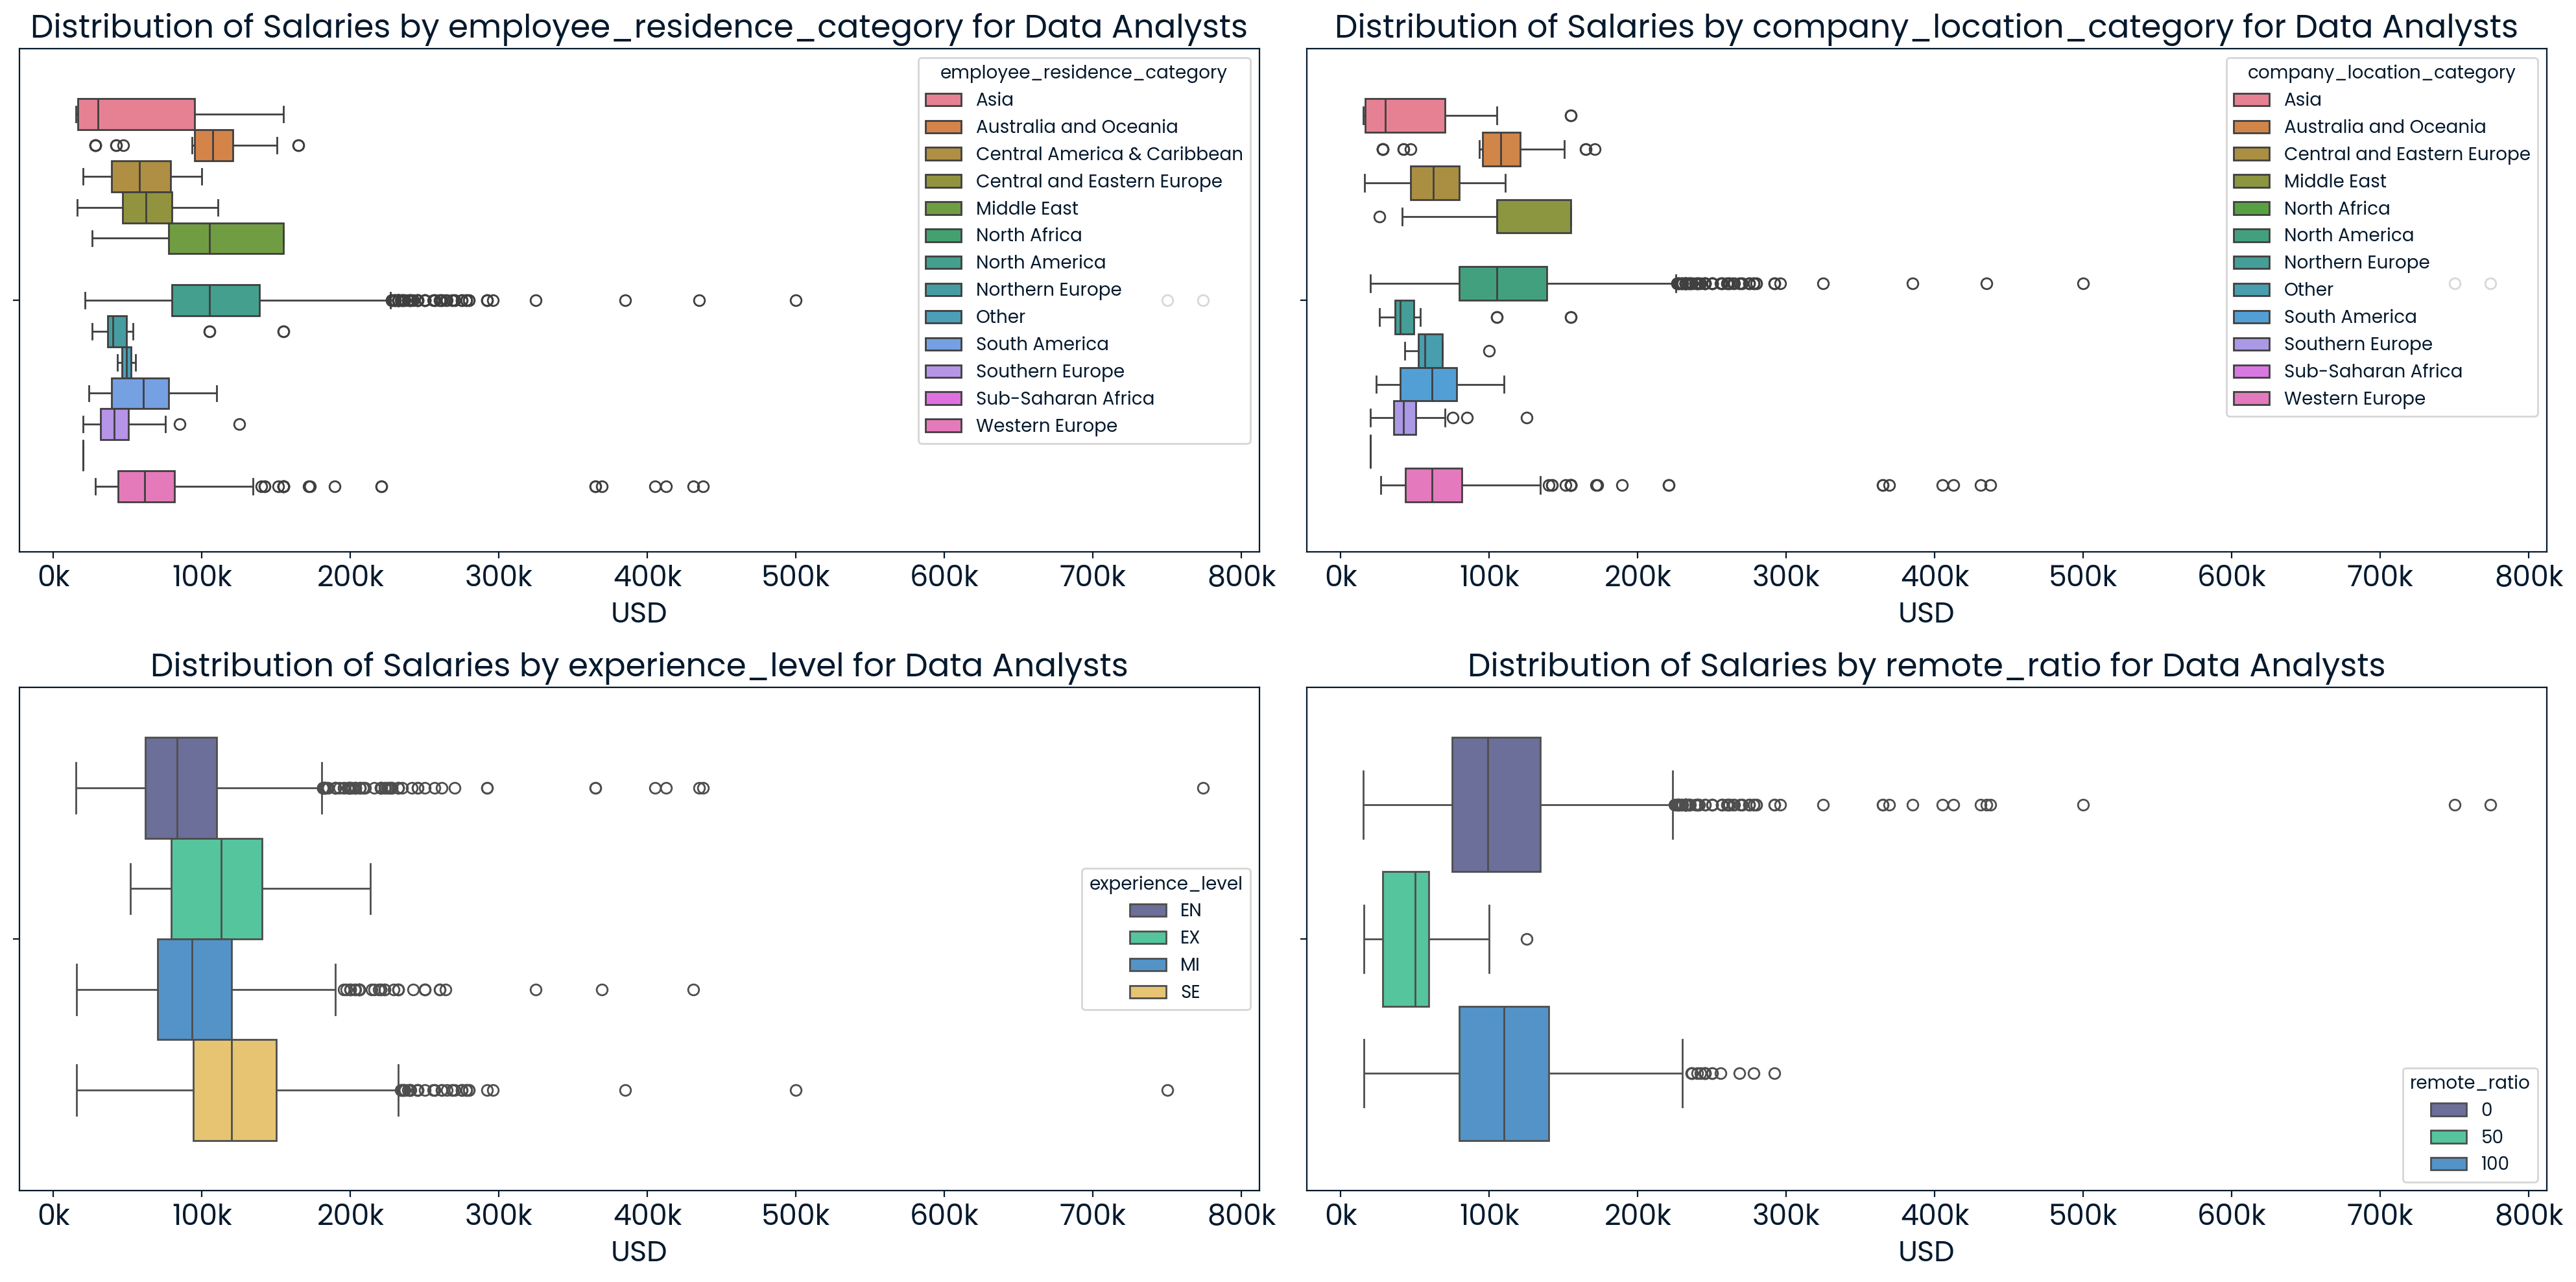

In [682]:
# List of categorical features to plot
list_f = ['employee_residence_category', 'company_location_category', 'experience_level', 'remote_ratio']

# Create a 2x2 subplot figure
fig, axes1 = plt.subplots(2, 2, figsize=(20, 10))
axes1 = axes1.flatten()  # Flatten the 2D array to 1D for easier indexing

# Loop through each feature in list_f and create a boxplot
for a, aa in enumerate(list_f):
    sns.boxplot(x='salary_in_usd', data=df_da, hue=aa, ax=axes1[a])  # Create boxplot for each feature
    axes1[a].set_title(f'Distribution of Salaries by {aa} for Data Analysts', size=18)  # Set title for each subplot
    axes1[a].set_xlabel('USD', fontsize=16)  # Set x-axis label
    axes1[a].tick_params(axis='x', labelsize=16)  # Set x-axis tick label size
    # Format x-axis labels to show values in thousands (e.g., 1000 as 1k)
    axes1[a].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))

# Adjust layout to prevent overlap
plt.tight_layout()
# Display the plot
plt.show()

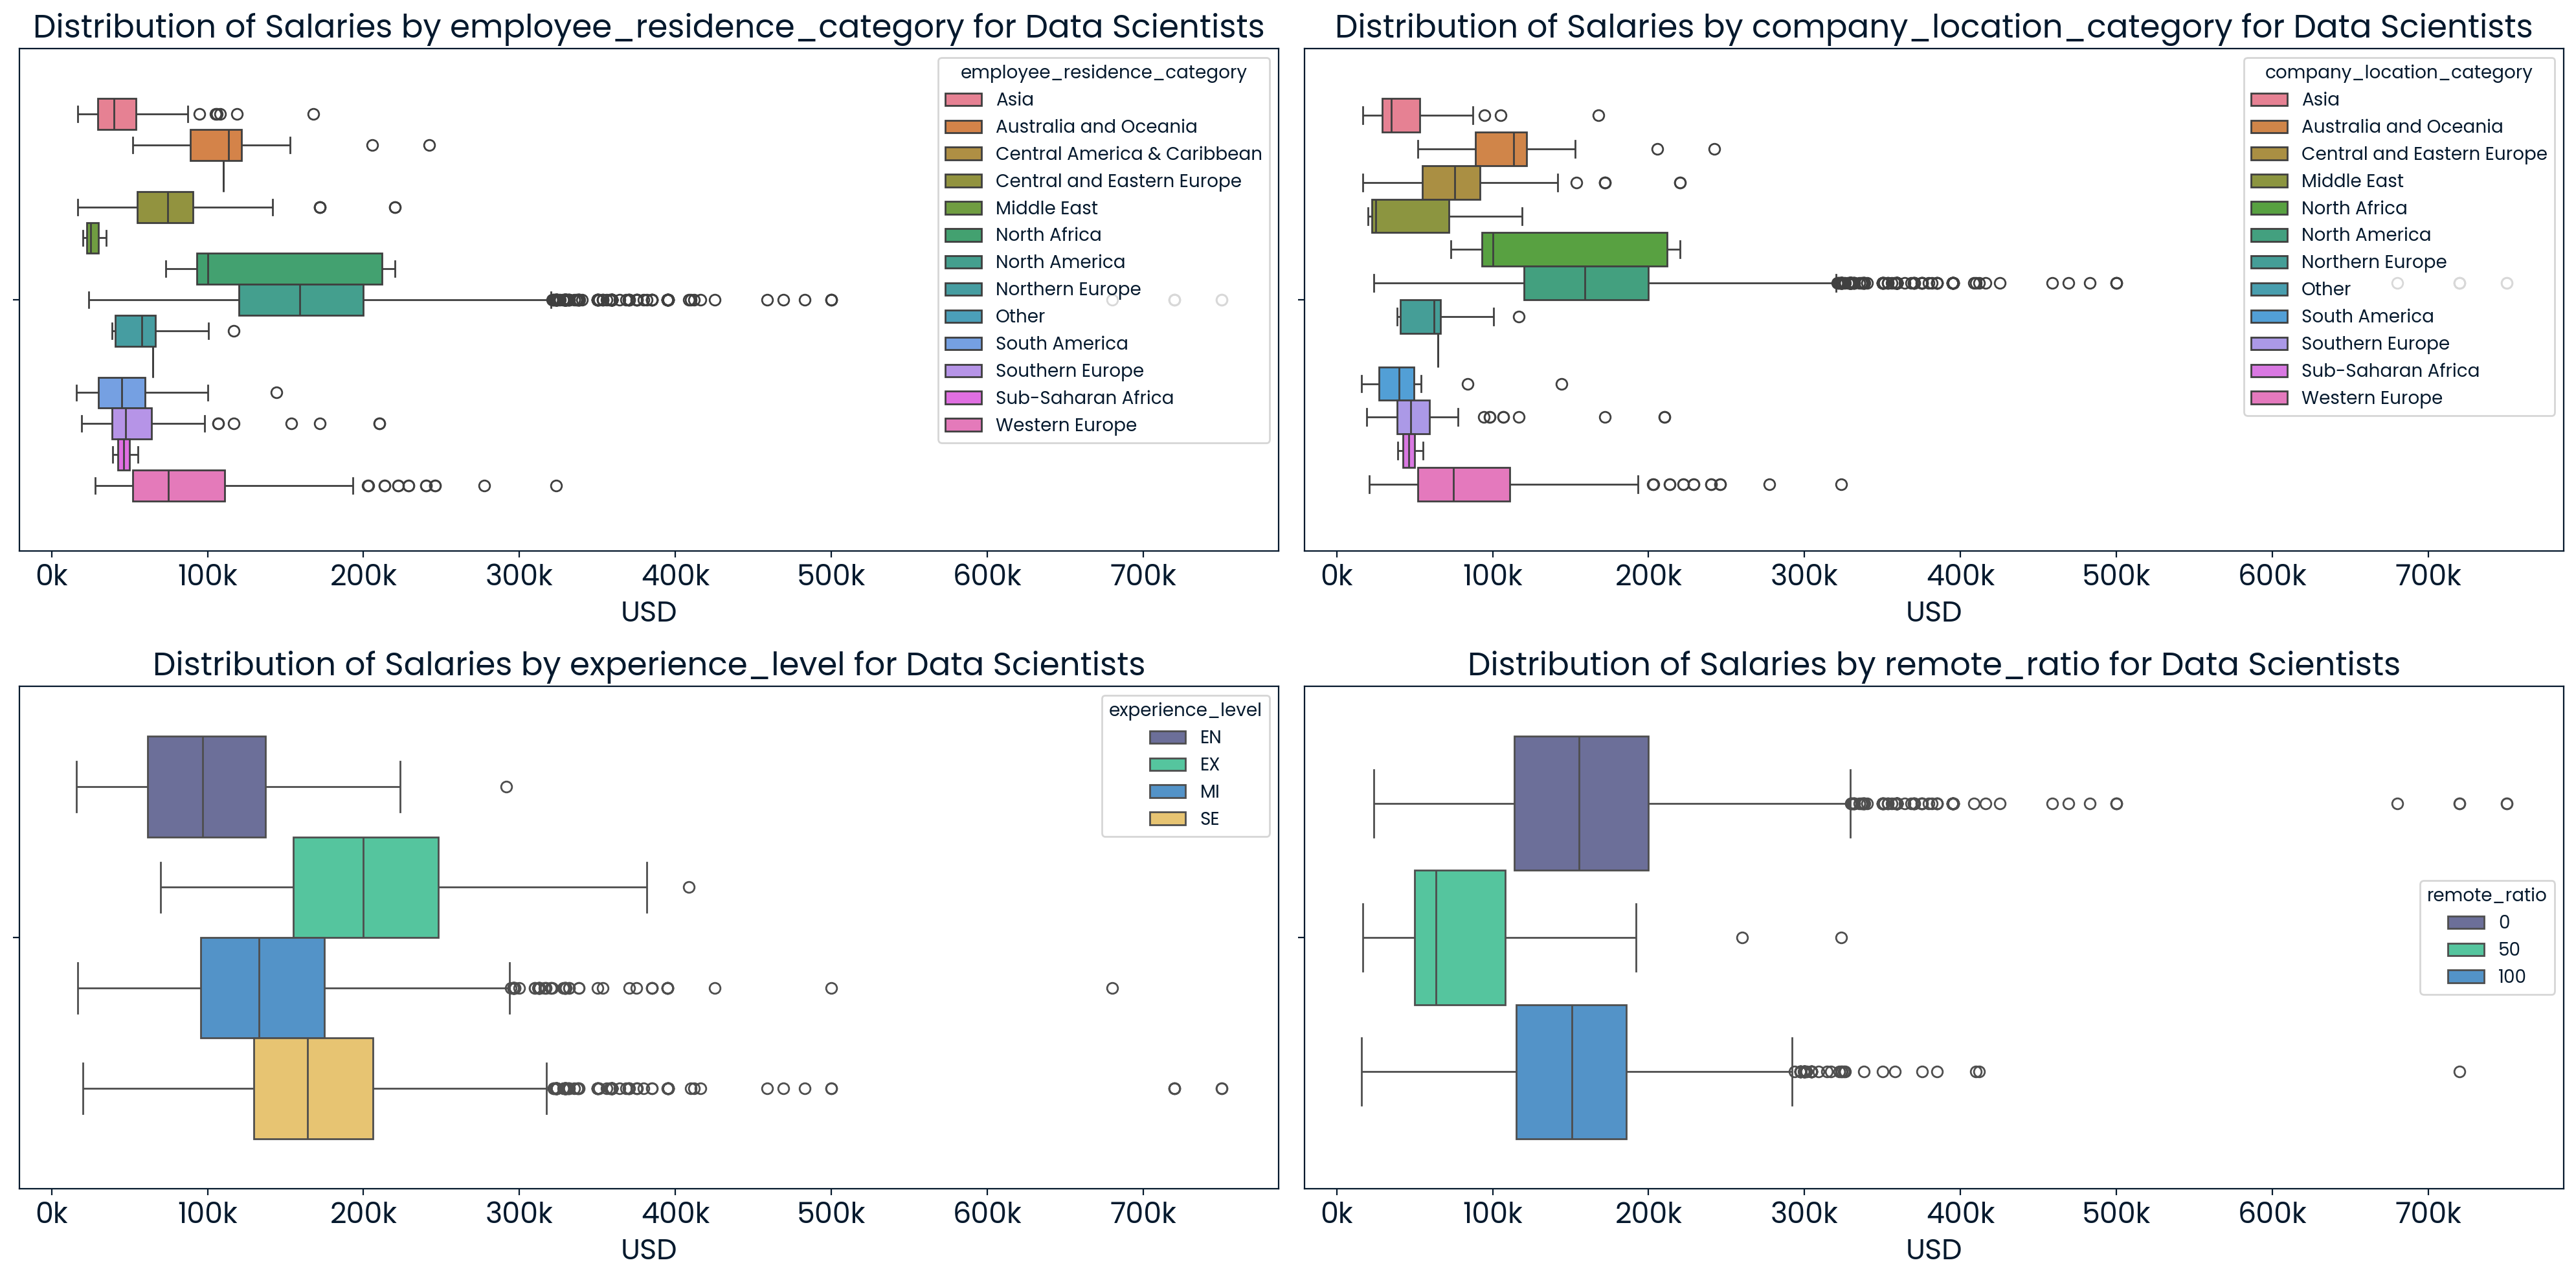

In [683]:
# Create a 2x2 subplot figure for Data Scientists
fig, axes2 = plt.subplots(2, 2, figsize=(20, 10))
axes2 = axes2.flatten()  # Flatten the 2D array to 1D for easier indexing

# Loop through each feature in list_f and create a boxplot
for b, bb in enumerate(list_f):
    sns.boxplot(x='salary_in_usd', data=df_ds, hue=bb, ax=axes2[b])  # Create boxplot for each feature
    axes2[b].set_title(f'Distribution of Salaries by {bb} for Data Scientists', size=18)  # Set title for each subplot
    axes2[b].set_xlabel('USD', fontsize=16)  # Set x-axis label
    axes2[b].tick_params(axis='x', labelsize=16)  # Set x-axis tick label size
    # Format x-axis labels to show values in thousands (e.g., 1000 as 1k)
    axes2[b].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))

# Adjust layout to prevent overlap
plt.tight_layout()
# Display the plot
plt.show()

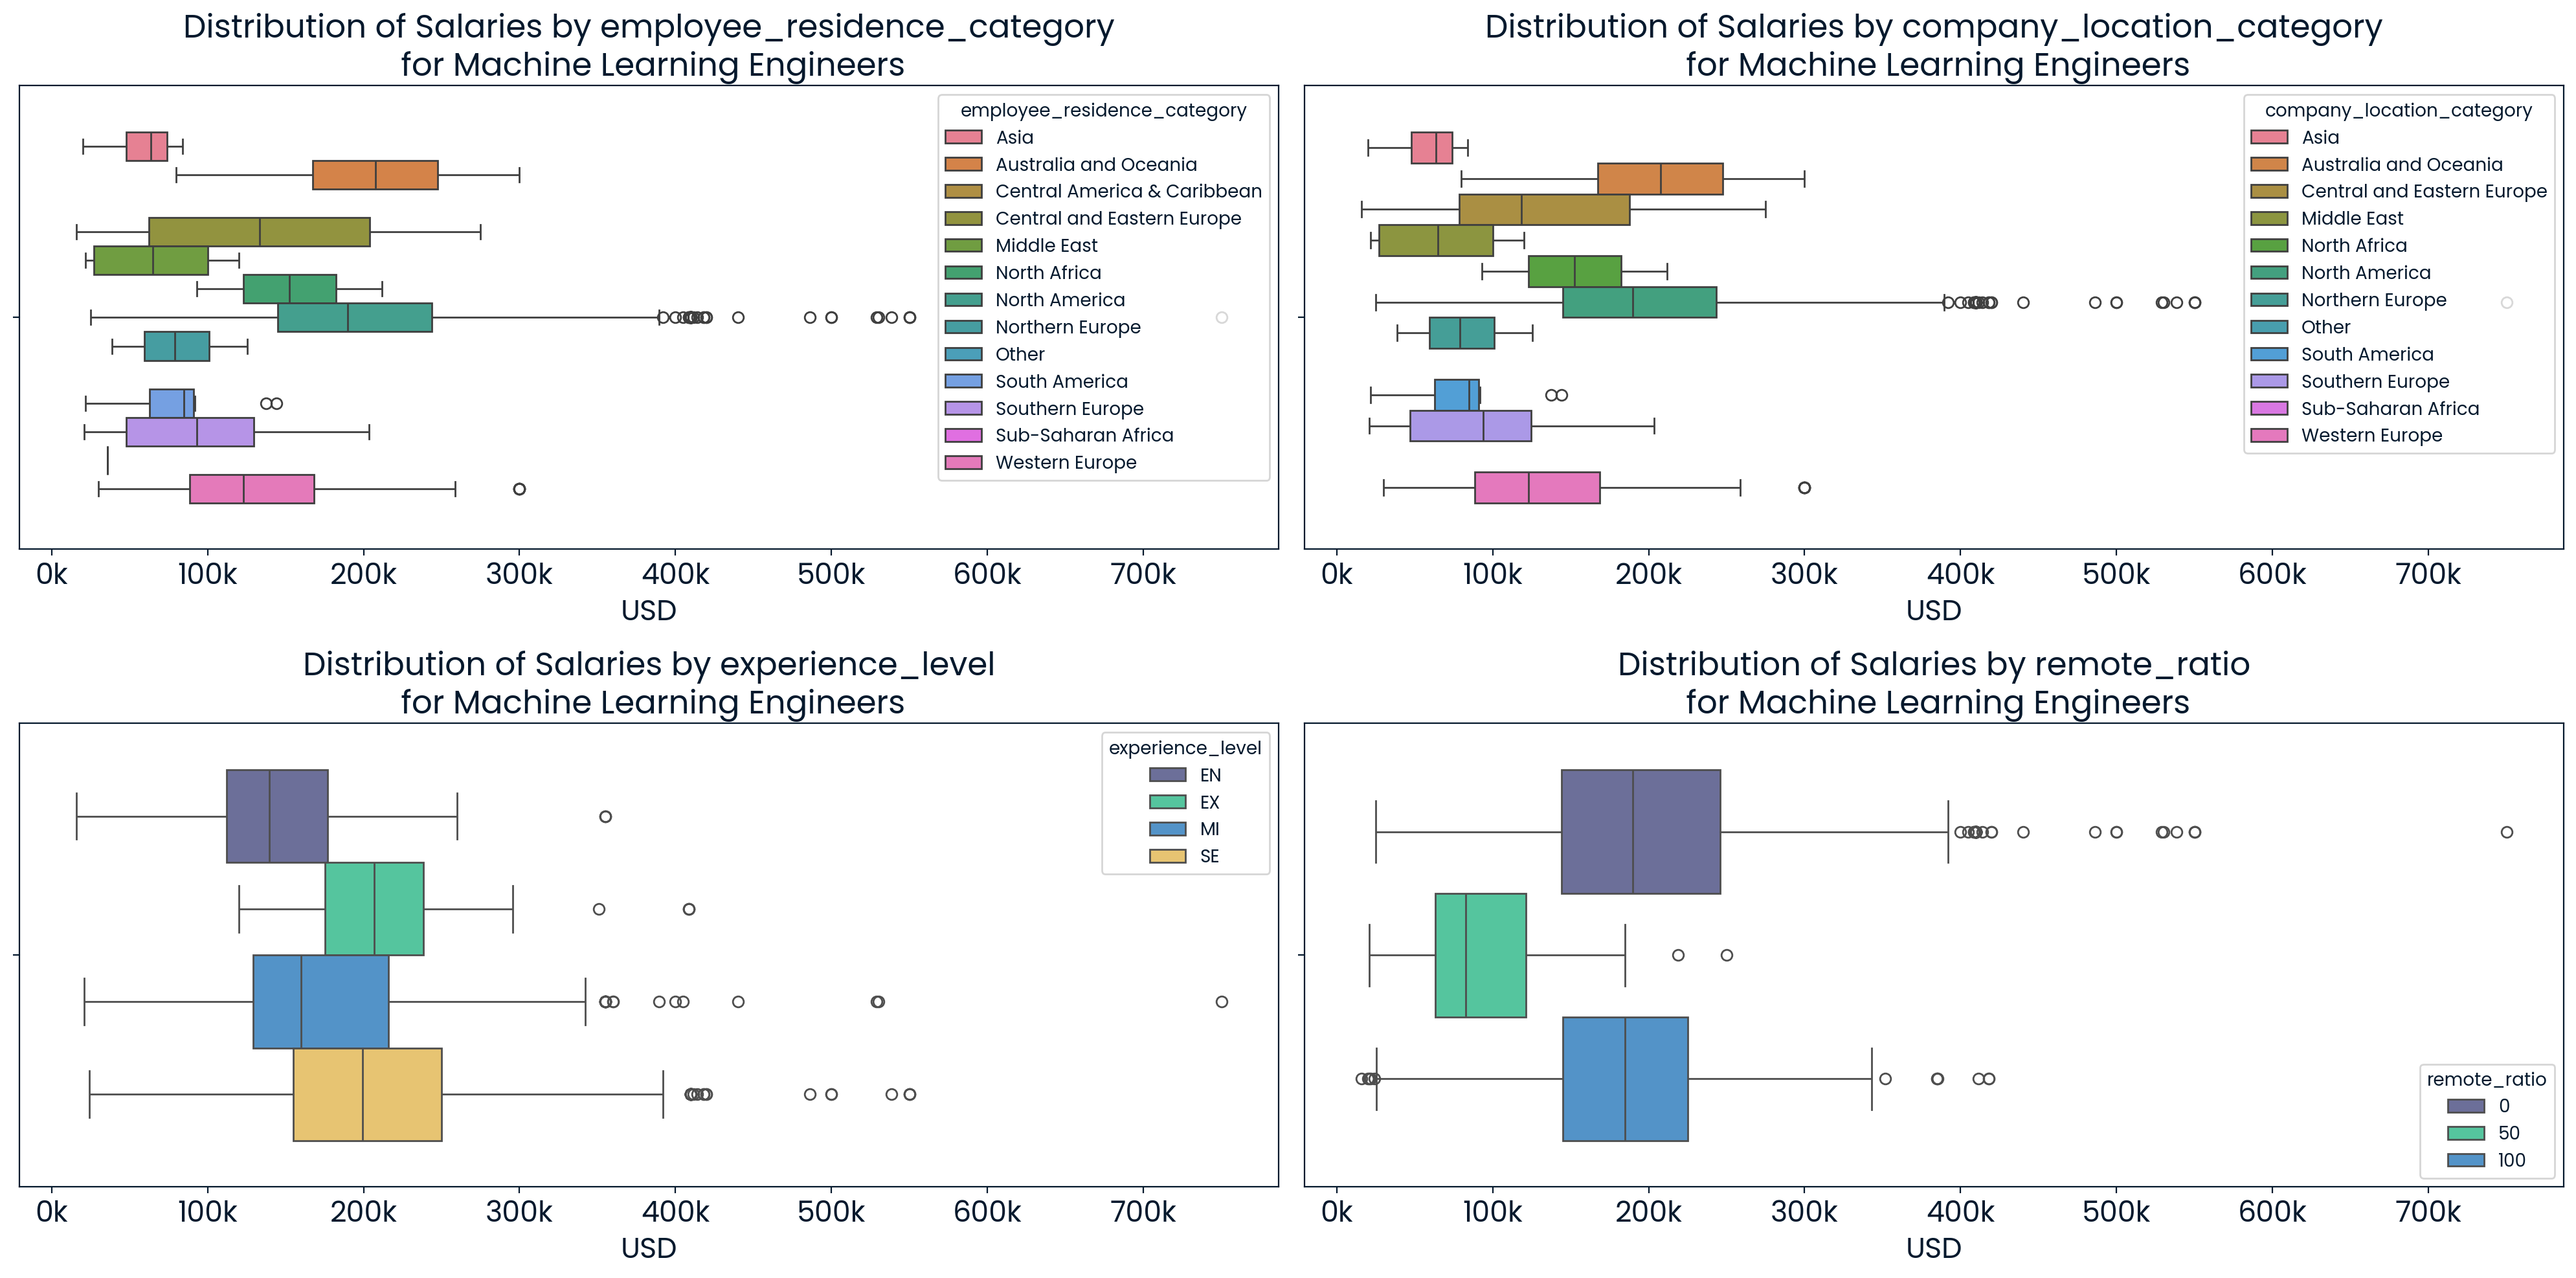

In [684]:
# Create a 2x2 subplot figure for Machine Learning Engineers
fig, axes3 = plt.subplots(2, 2, figsize=(20, 10))
axes3 = axes3.flatten()  # Flatten the 2D array to 1D for easier indexing

# Loop through each feature in list_f and create a boxplot
for c, cc in enumerate(list_f):
    sns.boxplot(x='salary_in_usd', data=df_mle, hue=cc, ax=axes3[c])  # Create boxplot for each feature
    axes3[c].set_title(f'Distribution of Salaries by {cc}\n for Machine Learning Engineers', size=18)  # Set title for each subplot
    axes3[c].set_xlabel('USD', fontsize=16)  # Set x-axis label
    axes3[c].tick_params(axis='x', labelsize=16)  # Set x-axis tick label size
    # Format x-axis labels to show values in thousands (e.g., 1000 as 1k)
    axes3[c].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))

# Adjust layout to prevent overlap
plt.tight_layout()
# Display the plot
plt.show()

In all three cases the highest salary is for employees located in North America, with Executive/Director level and 0 remote ratio. North Africa also looks high on these plots, but that group has only 39 rows in the whole dataset, so I would not read anything into it. I look at the group sizes properly below.

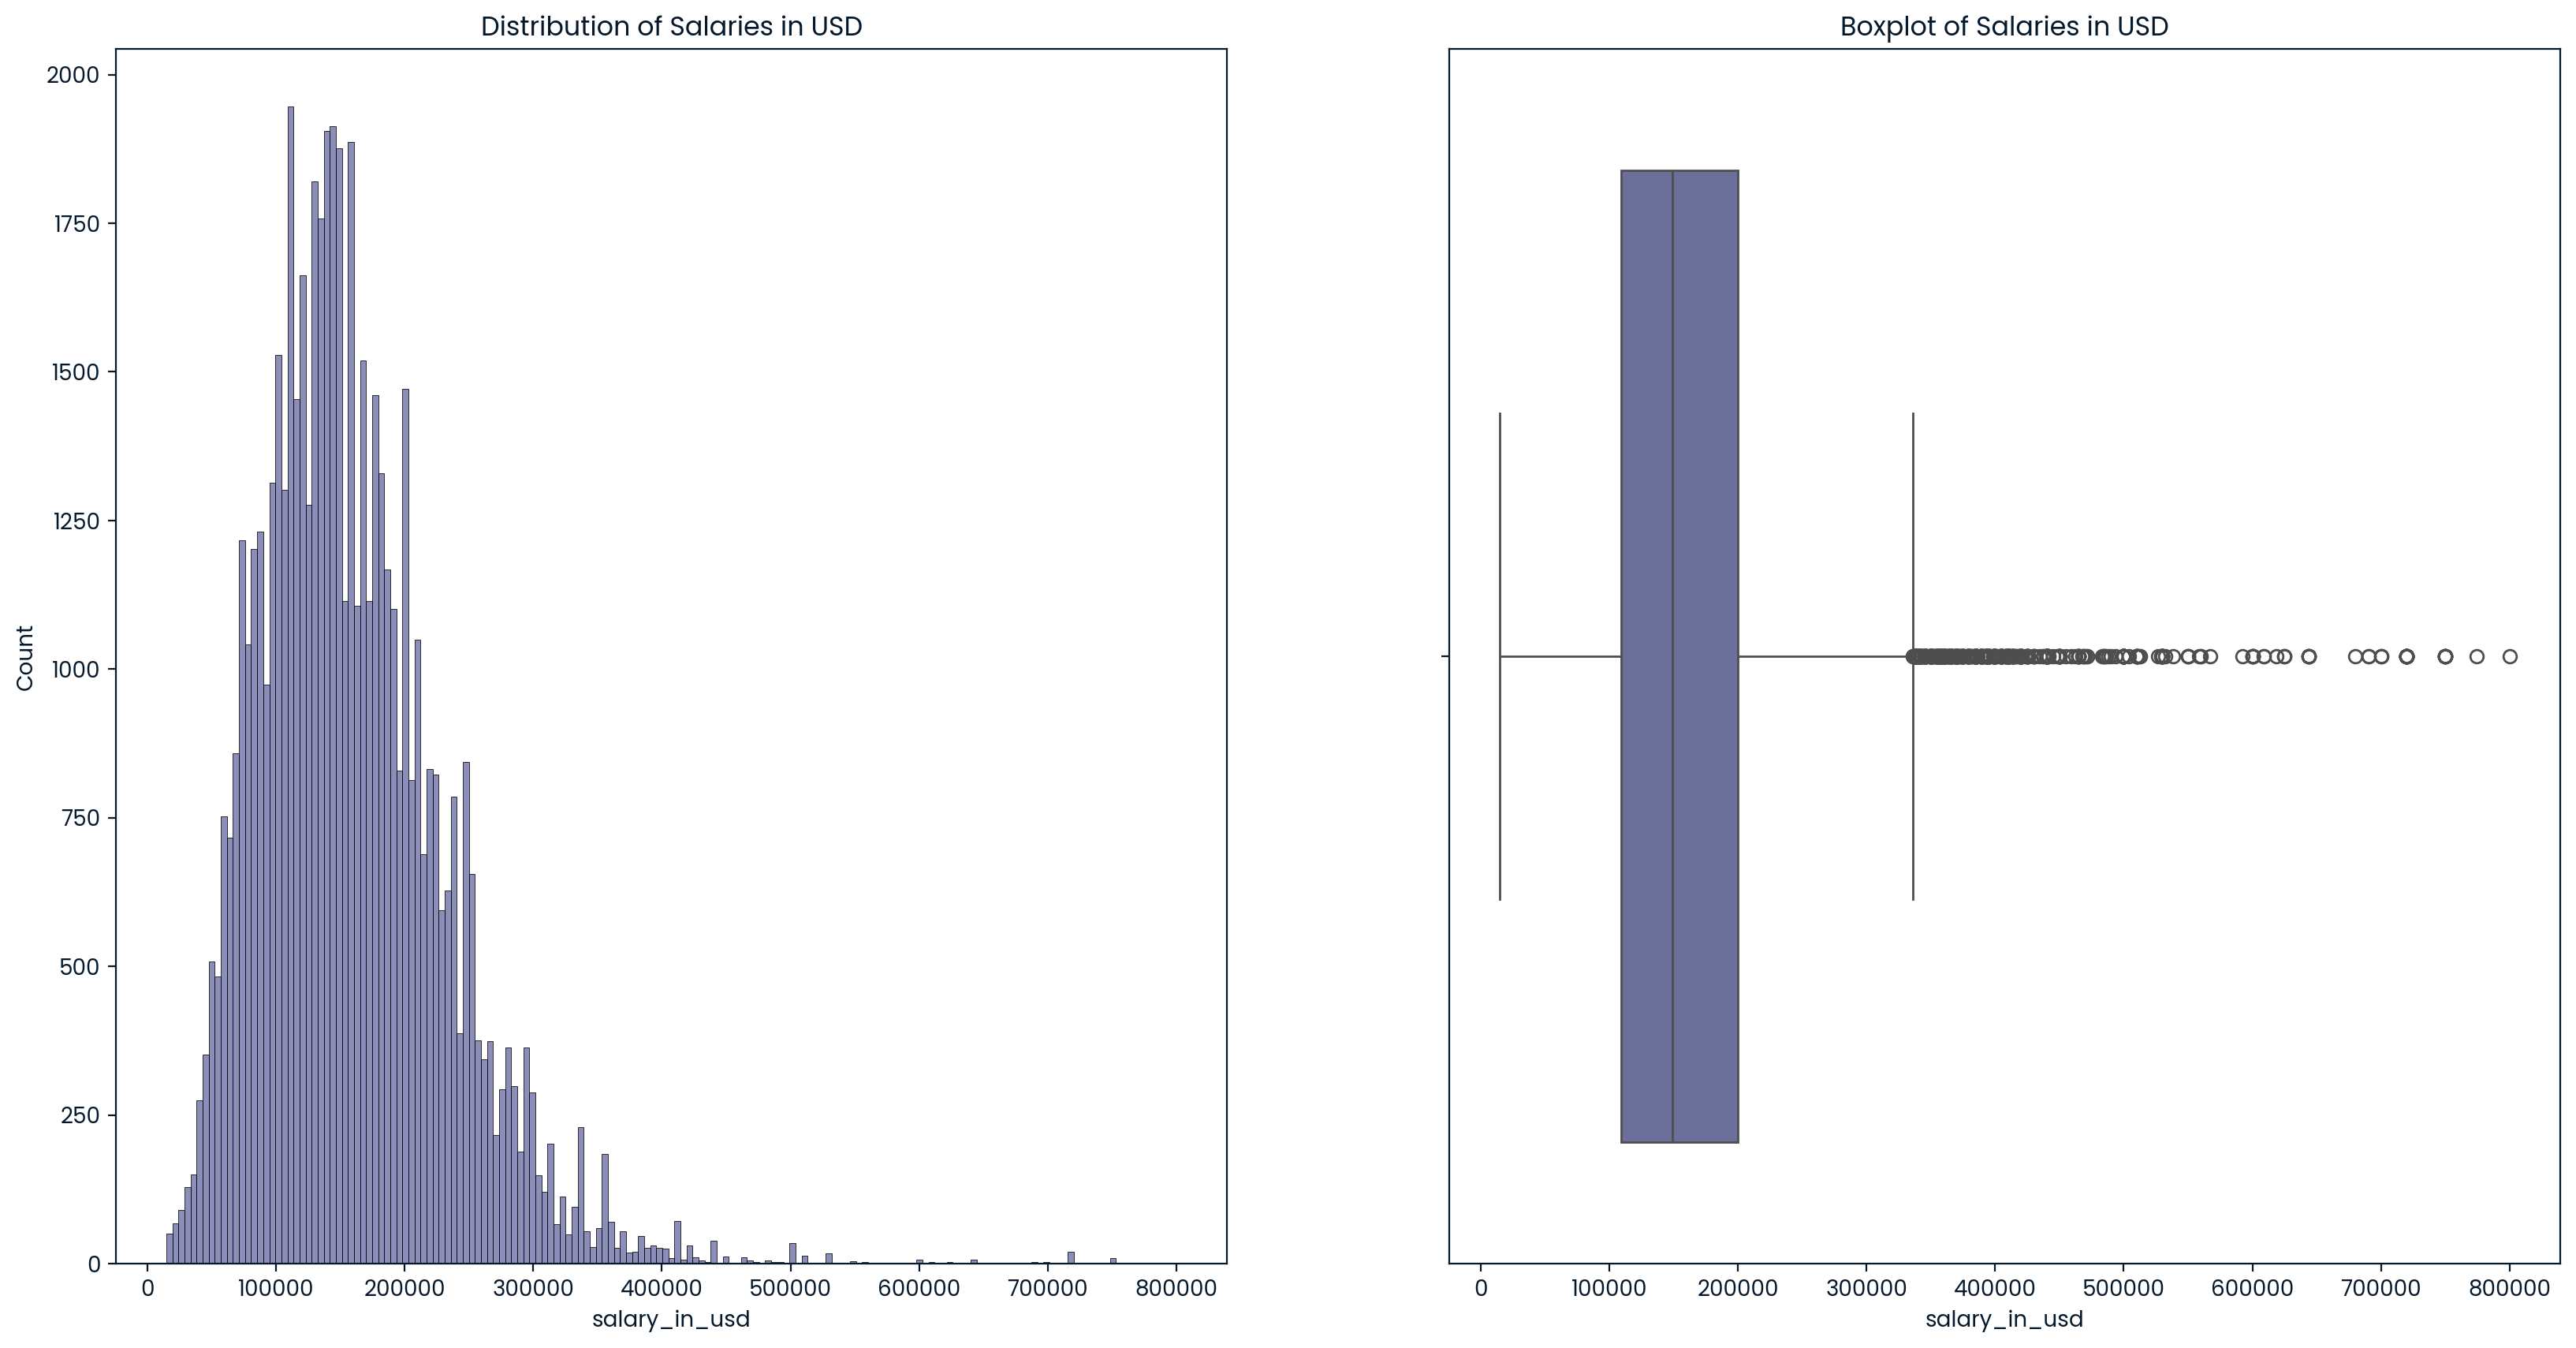

In [685]:
# Check the distribution of target variable Salaries in USD
# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Plot histogram of salary in USD
sns.histplot(x='salary_in_usd', data=df, ax=axes[0])
axes[0].set_title('Distribution of Salaries in USD')

# Plot boxplot of salary in USD
sns.boxplot(x='salary_in_usd', data=df, ax=axes[1])
axes[1].set_title('Boxplot of Salaries in USD')

# Display the plots
plt.show()

In [686]:
df['salary_in_usd'].describe().round(2)

count     57194.00
mean     159223.57
std       72155.16
min       15000.00
25%      109300.00
50%      149040.00
75%      200000.00
max      800000.00
Name: salary_in_usd, dtype: float64

From the histogram, boxplot, and description above, we can see that 'salary_in_usd' has a right-skewed distribution, with a mean value of 159223.57, a median of 149040, a minimum value of 15000, and a maximum value of 800000. It's our target variable. The 'salary' column is not used in our analysis because it's uninformative (the salary is in different currencies, which makes it impossible to compare).

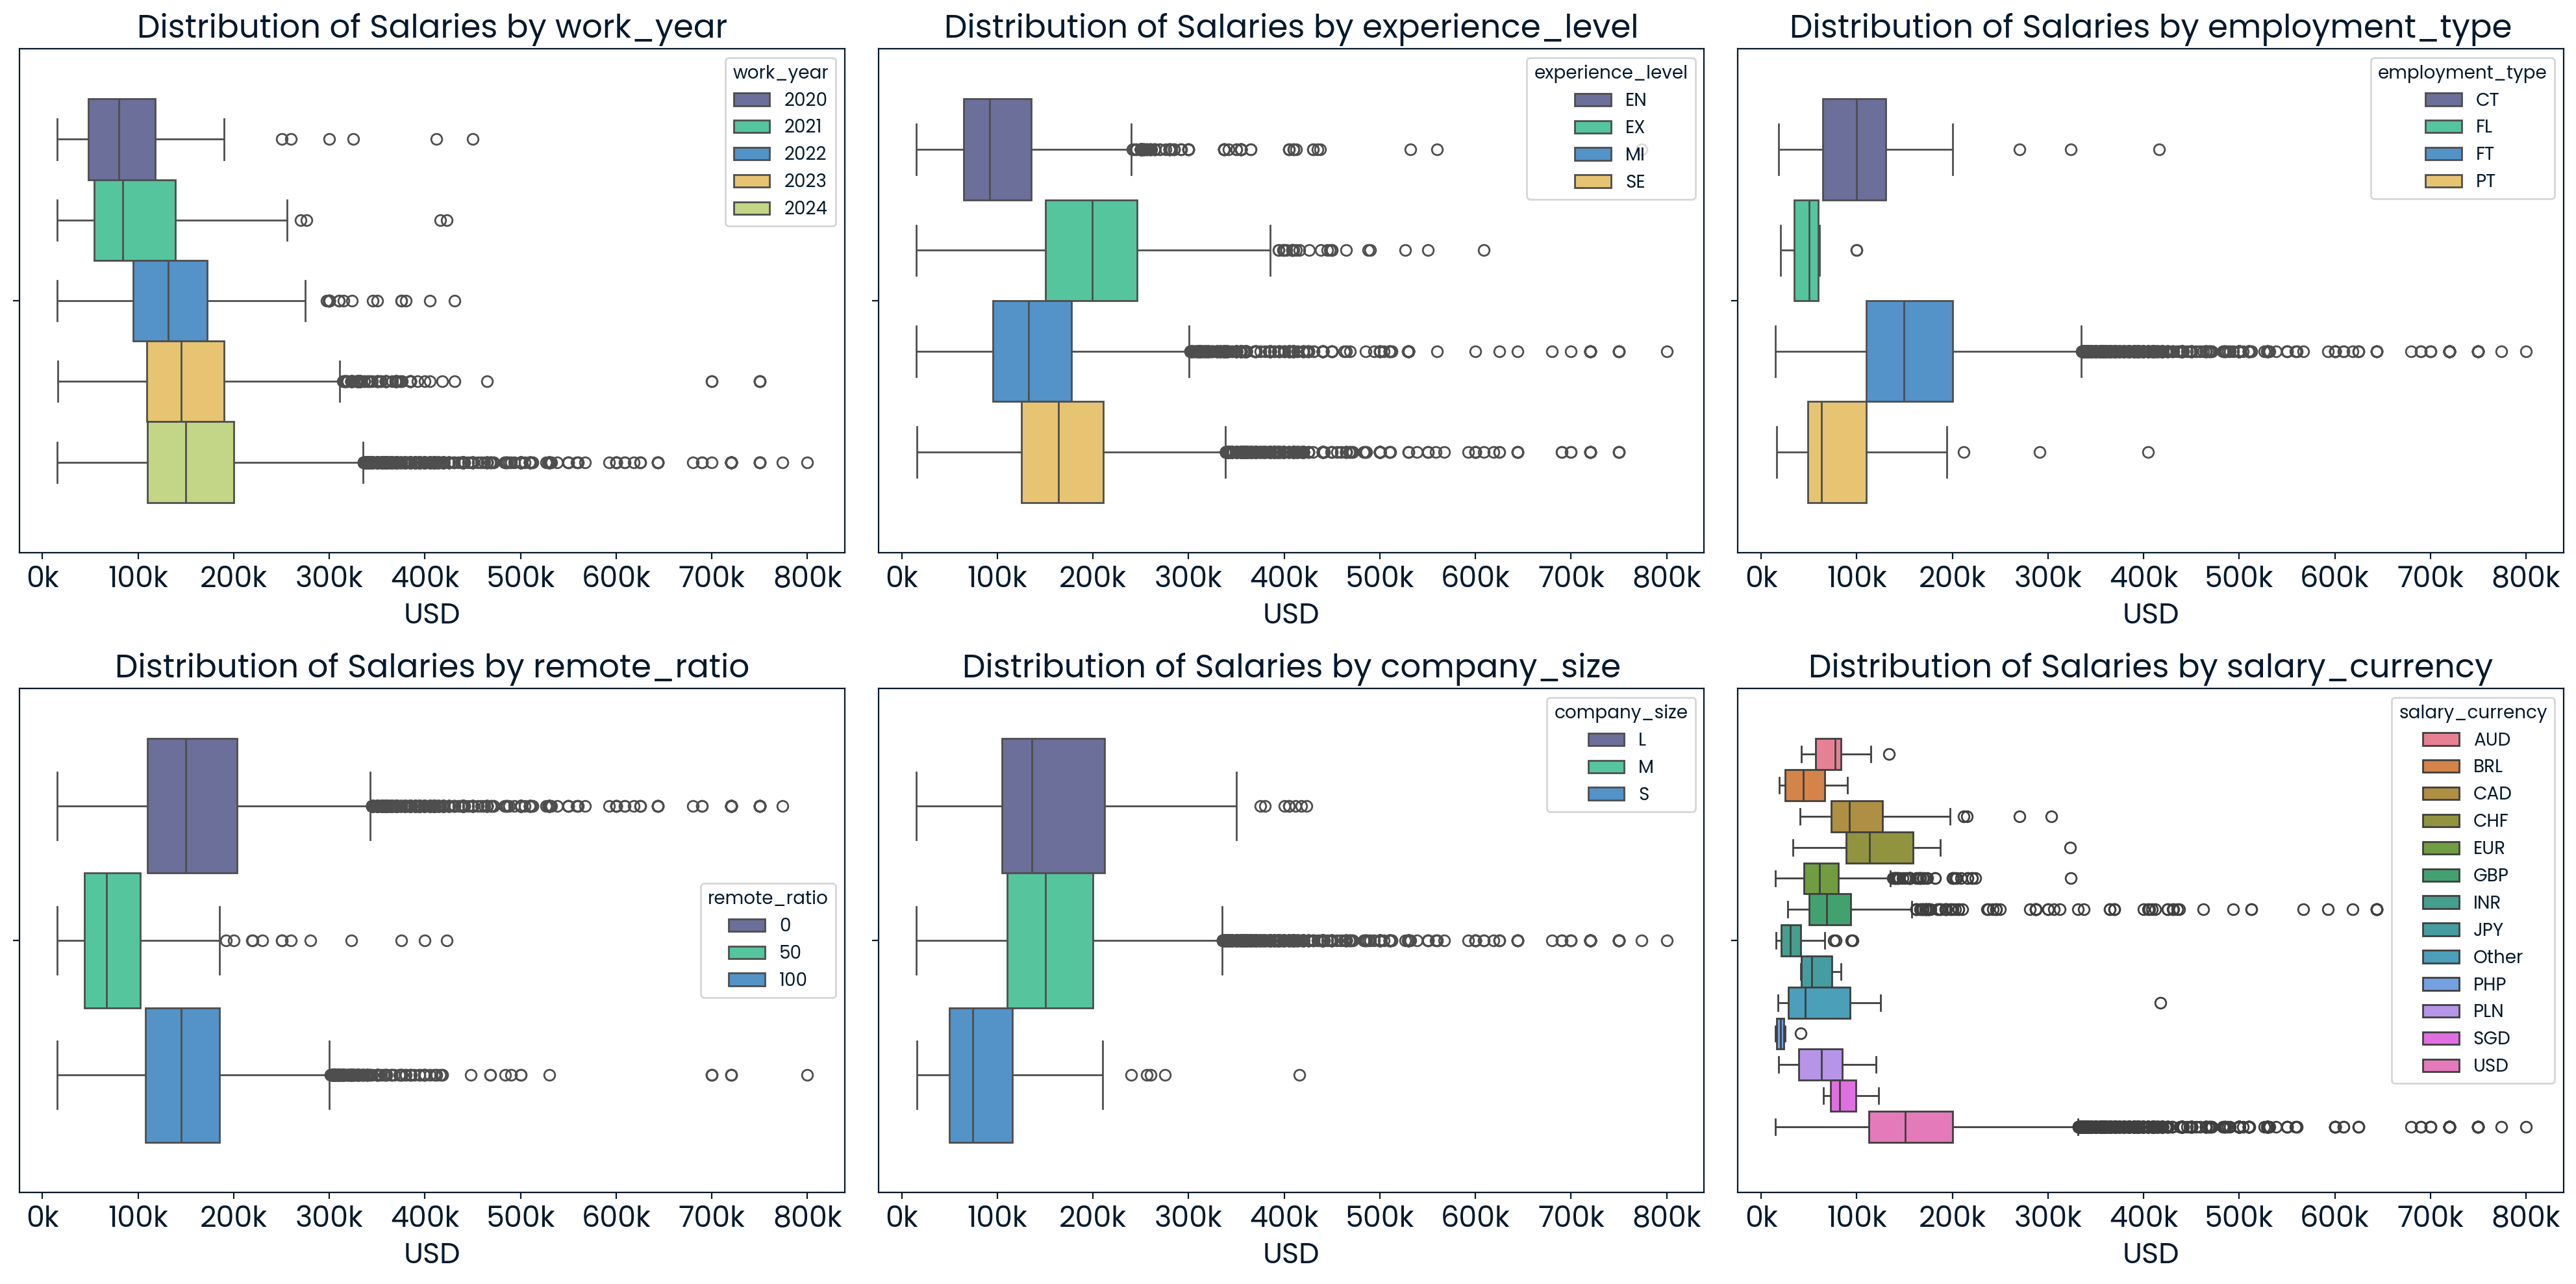

In [687]:
list_col = ['work_year', 'experience_level', 'employment_type', 'remote_ratio', 'company_size', 'salary_currency']

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()  # Flatten the 2D array to 1D for easier indexing

for i, ii in enumerate(list_col):
    sns.boxplot(x='salary_in_usd', data=df, hue=ii, ax=axes[i])
    axes[i].set_title(f'Distribution of Salaries by {ii}', size=18)
    axes[i].set_xlabel('USD', fontsize=16)  
    axes[i].tick_params(axis='x', labelsize=16)  
    # Format x-axis labels
    axes[i].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))

plt.tight_layout()
plt.show()

From the boxplots above, we can see that the median salary increased each year, with the maximum value of outliers in 2024. The first two years are very small, 75 rows in 2020 and 218 in 2021, so the early part of this trend rests on very little data. The growth itself is also not as simple as it looks here, and I come back to it at the end of the notebook.

When analyzing the distribution of salaries by experience level, we observe that the minimum median value is at the EN level, and the maximum is at the EX level. All distributions are right-skewed.

By employment type, the smallest median salary is in FL, and the highest is in FT.

By remote ratio, the smallest median salary is at 50%, with almost equal values at 0% and 100%.

We can see that the highest salary is in medium-sized companies, and the smallest is in small companies. And the highest salary is the one that is paid in USD currency.


In [688]:
df['salary_in_usd'] = df['salary_in_usd'].astype('float')

In [689]:
df['salary_in_usd'].dtype

dtype('float64')

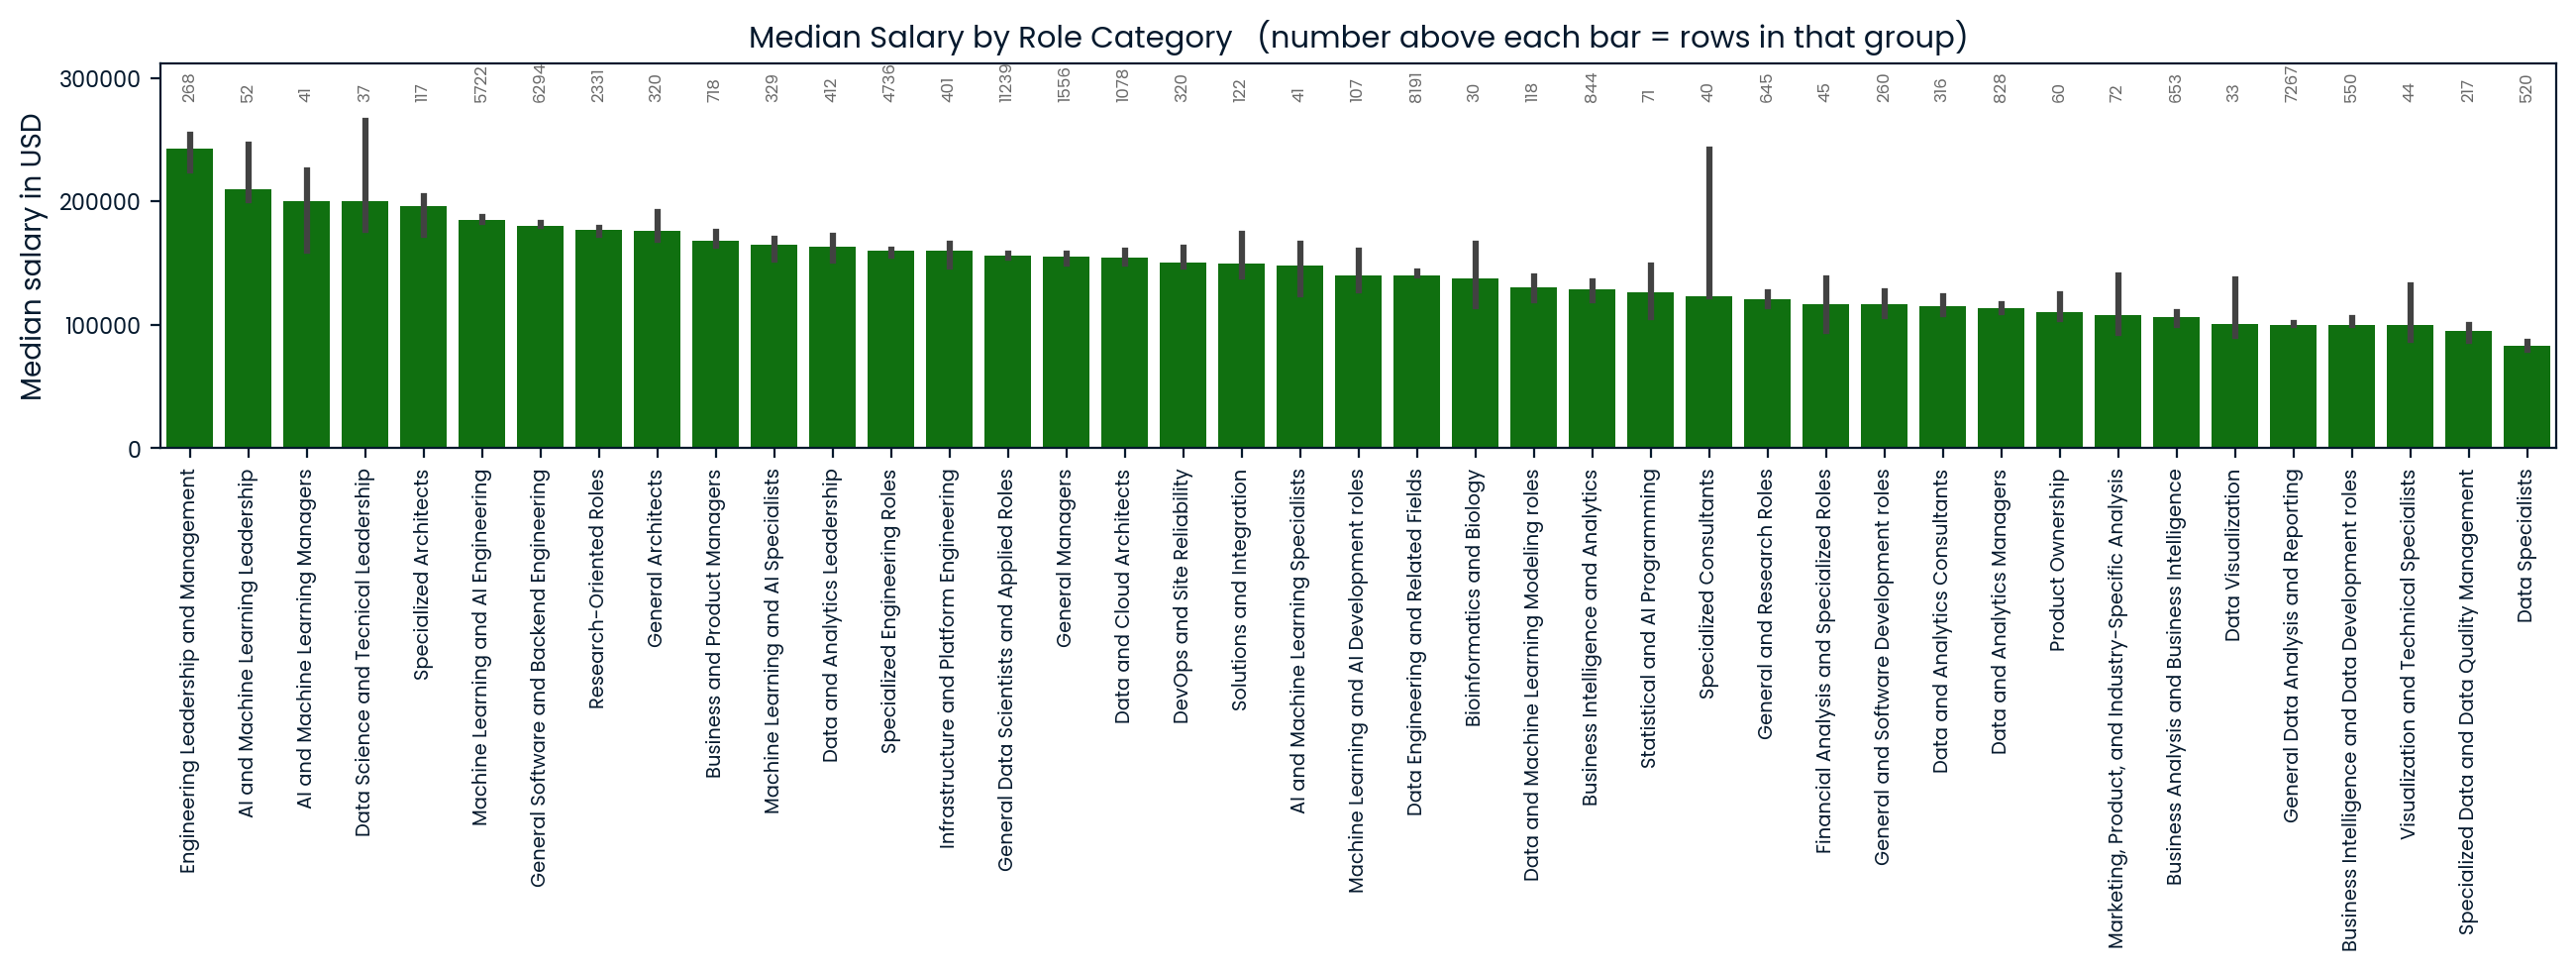

Groups with fewer than 30 rows, too small to rank:
                                                n    median
role_category                                              
Leadership and Senior Data Science Roles       26  153249.5
Database and Systems Administration            18  123488.0
Technical Writing and Design, Technical Stuff  27  122000.0
Specialized Technology Development roles       29  110000.0
Data Operations and Management                 29   80000.0
Other                                          20   67000.0


In [690]:
def salary_bar(col, title, min_n=30):
    g = (df.groupby(col, observed=True)['salary_in_usd']
         .agg(n='size', median='median')).sort_values('median', ascending=False)
    keep, dropped = g[g['n'] >= min_n], g[g['n'] < min_n]
    order = list(keep.index)

    plt.figure(figsize=(max(8, len(order) * 0.32), 5))
    ax = sns.barplot(x=col, y='salary_in_usd', data=df[df[col].isin(order)],
                     order=order, estimator=np.median, errorbar=('ci', 95),
                     color='green')
    top = ax.get_ylim()[1]
    ax.set_ylim(0, top * 1.12)
    for i, c in enumerate(order):
        ax.text(i, top * 1.01, str(keep.loc[c, 'n']), ha='center', va='bottom',
                fontsize=6, rotation=90, color='dimgray')

    plt.xticks(range(len(order)), order, rotation=90, fontsize=7)
    plt.yticks(fontsize=8)
    plt.xlabel('')
    plt.ylabel('Median salary in USD', fontsize=10)
    plt.title(f"{title}   (number above each bar = rows in that group)", fontsize=11)
    plt.tight_layout()
    plt.show()

    if len(dropped):
        print(f"Groups with fewer than {min_n} rows, too small to rank:")
        print(dropped.to_string())

salary_bar('role_category', 'Median Salary by Role Category')

The plot shows medians, not means, because `salary_in_usd` is right-skewed and the mean is pulled up by outliers. The bars are ordered by median and the number of rows is printed next to each category.

The highest paid categories are Engineering Leadership and Management (n=268), AI and Machine Learning Leadership (n=52), AI and Machine Learning Managers (n=41), Data Science and Tecnical Leadership (n=37) and Specialized Architects (n=117). They are all leadership or architect roles.

The lowest paid are Data Specialists (n=520), Specialized Data and Data Quality Management (n=217), Visualization and Technical Specialists (n=44), Business Intelligence and Data Development roles (n=550) and General Data Analysis and Reporting (n=7267).

The confidence intervals matter here. Engineering Leadership and Management is clearly separated from the rest, but inside the top five the order is not meaningful: positions three and four differ by about 500 USD while their intervals are about 50,000 wide. Categories with fewer than 30 rows are left out of the plot and printed below it, because with that few observations the position in the ranking is not determined.

'Tecnical' is a typo in the data itself, in the category name.


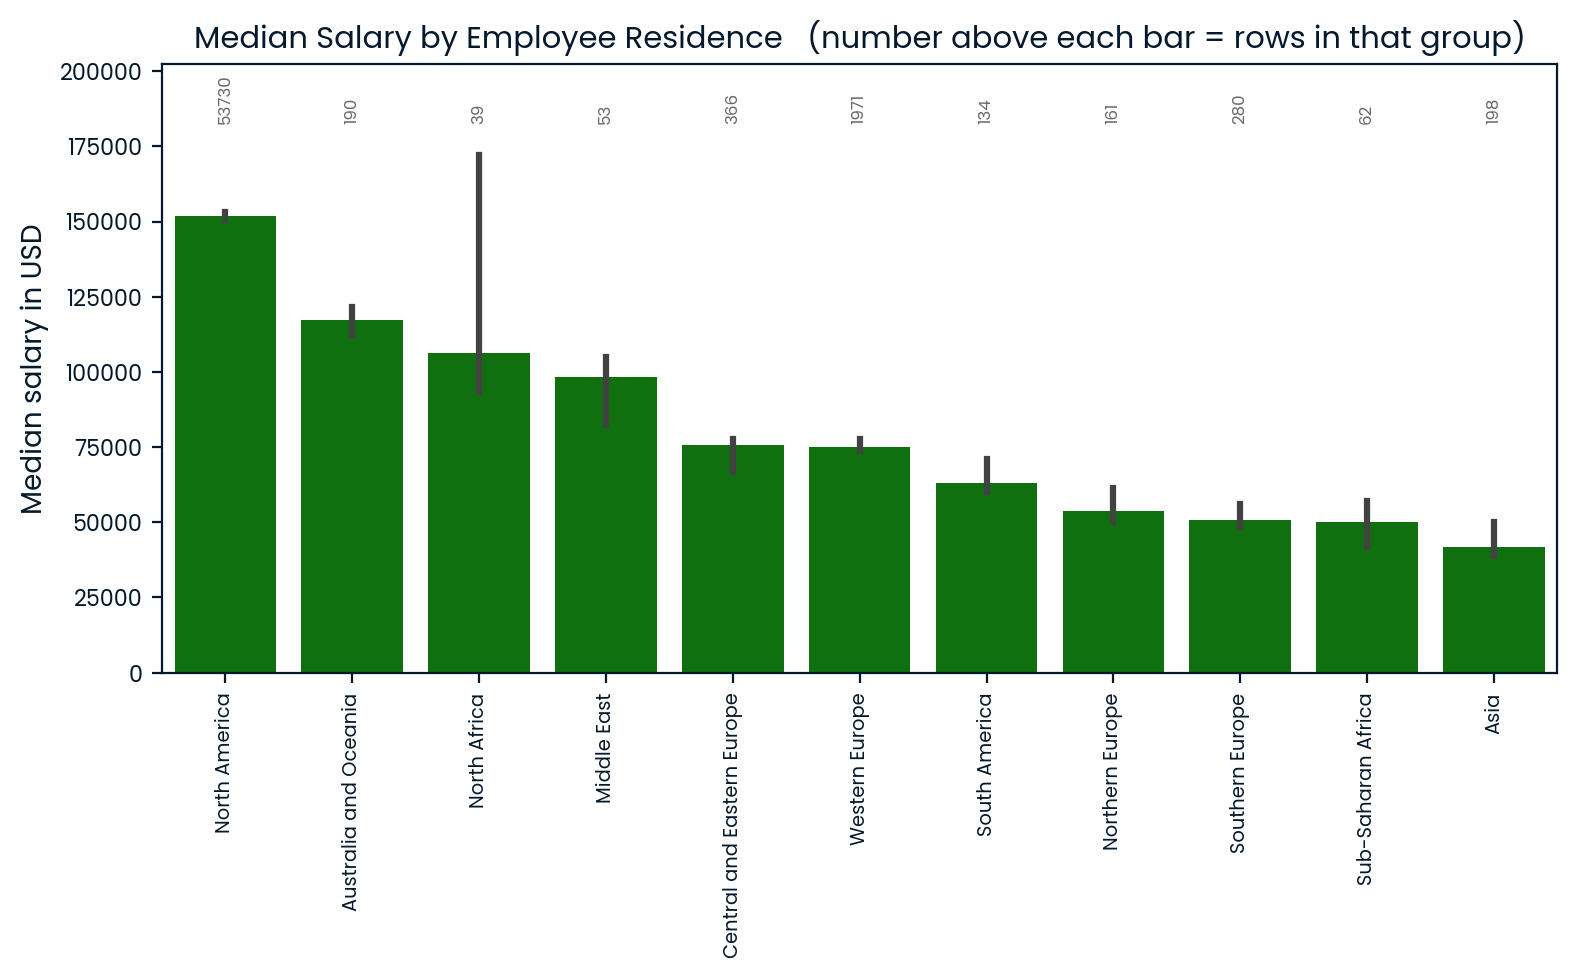

Groups with fewer than 30 rows, too small to rank:
                             n   median
employee_residence_category            
Other                        5  65058.0
Central America & Caribbean  5  58000.0


In [691]:
salary_bar('employee_residence_category', 'Median Salary by Employee Residence')

In [692]:
# Group sizes and confidence intervals behind the bar charts
def group_table(col):
    g = (df.groupby(col, observed=True)['salary_in_usd']
         .agg(n='size', mean='mean', median='median', sd='std'))
    g['se'] = g['sd'] / np.sqrt(g['n'])
    g['ci_low'] = g['mean'] - 1.96 * g['se']
    g['ci_high'] = g['mean'] + 1.96 * g['se']
    g['ci_width'] = g['ci_high'] - g['ci_low']
    return (g.sort_values('mean', ascending=False)
            [['n', 'mean', 'median', 'ci_low', 'ci_high', 'ci_width']].round(0))

for c in ['employee_residence_category', 'company_location_category']:
    print(f"--- {c} ---")
    print(group_table(c).to_string())
    print()

r = group_table('role_category')
print("--- role_category: top 5 by mean ---")
print(r.head(5).to_string())
print("\n--- role_category: bottom 5 by mean ---")
print(r.tail(5).to_string())

--- employee_residence_category ---
                                 n      mean    median    ci_low   ci_high  ci_width
employee_residence_category                                                         
North America                53730  163689.0  151888.0  163095.0  164283.0    1188.0
North Africa                    39  132527.0  106200.0  110833.0  154222.0   43389.0
Australia and Oceania          190  129625.0  117282.0  121337.0  137913.0   16576.0
Middle East                     53   99075.0   98400.0   80067.0  118084.0   38017.0
Western Europe                1971   95581.0   75000.0   92409.0   98753.0    6344.0
Central and Eastern Europe     366   92118.0   75600.0   85926.0   98309.0   12383.0
South America                  134   69616.0   63000.0   63294.0   75937.0   12643.0
Northern Europe                161   65972.0   53666.0   60758.0   71186.0   10428.0
Other                            5   65902.0   65058.0   47329.0   84476.0   37146.0
Southern Europe              

Only one statement here is safe: North America is the highest paid region. Its confidence interval is 163,095 to 164,283 and the next region is thirty thousand below, so there is no doubt about it. This is because 53,730 of the 57,194 rows come from North America.

For the rest the data is too thin to rank. North Africa looks second by mean, but it has 39 rows, its confidence interval runs from 110,833 to 154,222, and by median it is actually fourth, below Australia and Oceania. The second place comes from the mean of 39 rows, which one or two outliers can move.

Central America & Caribbean has 5 rows and a confidence interval from 24,177 to 99,023, which is wider than the difference between most of the regions. I do not include it in the ranking at all, and the same for 'Other', which is not a region.


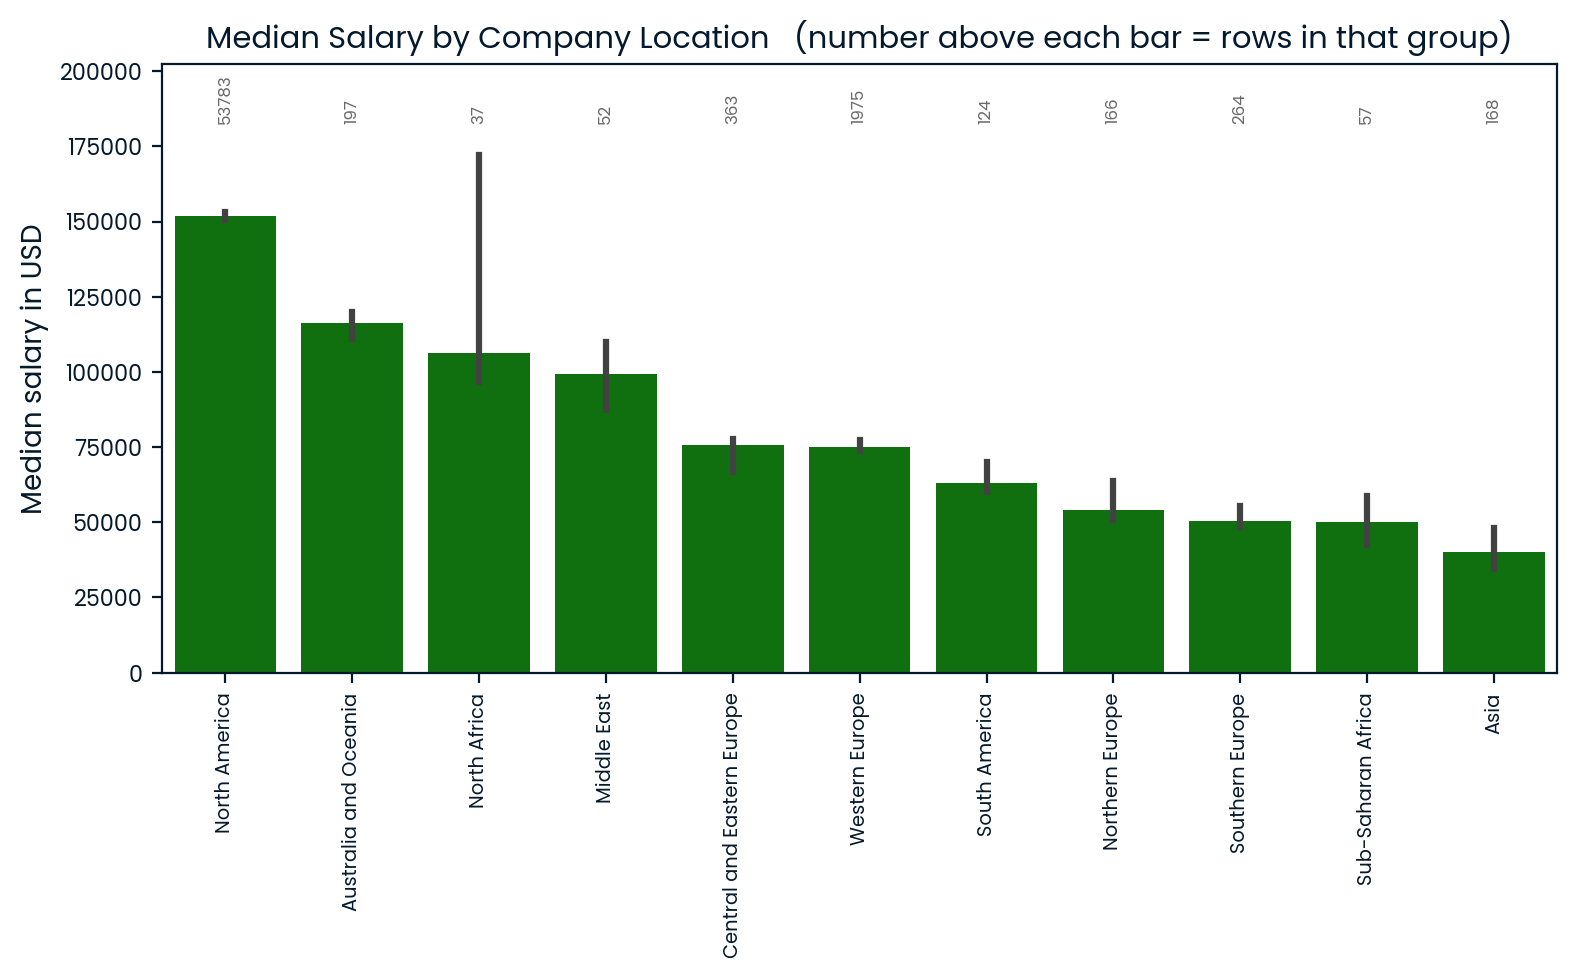

Groups with fewer than 30 rows, too small to rank:
                           n   median
company_location_category            
Other                      8  56684.0


In [693]:
salary_bar('company_location_category', 'Median Salary by Company Location')

The picture repeats: North America is far above everything else (53,783 rows), and the rest of the ranking is not reliable. North Africa has 37 rows here.

My earlier version of this conclusion named Central America and the Caribbean among the lowest paid company locations. That was wrong twice. First, with 5 rows nothing can be said about it. Second, this category does not exist in `company_location_category` at all: earlier in the notebook I replaced every location with fewer than 5 rows by 'Other', and this one went there. The conclusion described a category that is not on the plot.

# Prepare data for modelling

To enable modelling, we choose work_year, experience_level, employment_type, role_category, salary_currency, employee_residence_category, remote_ratio, company_location_category and company_size as features, and salary_in_usd as the target variable. I also have made the following changes:
- Convert the categorical variables into numeric features with one-hot encoding
- Split the data into training, validation and test sets

Develop a predictive model to estimate an employee’s salary (in USD) using experience level, company location, and remote ratio. Which features are the strongest predictors of salary?

## First model:
with features: 
- experience_level,
- company_location_category,
- remote_ratio,

and target: salary_in_usd.

In [694]:
X_first = df[['experience_level', 'company_location_category', 'remote_ratio']]
y_first = df['salary_in_usd']

In [695]:
# Split the data into training, validation, and test sets
X_first_train, X_first_temp, y_first_train, y_first_temp = train_test_split(X_first, y_first, test_size=0.3, random_state=42)
X_first_val, X_first_test, y_first_val, y_first_test = train_test_split(X_first_temp, y_first_temp, test_size=0.5, random_state=42)

In [696]:
# Define column transformer with one-hot encoding(dropping the first category) and scaling 
preprocessor_first = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), 
    ['experience_level', 'company_location_category', 'remote_ratio'])
])

In [697]:
# Fit and transform the training data; only transform the test data
X_first_train_preprocessed = preprocessor_first.fit_transform(X_first_train)
X_first_val_preprocessed = preprocessor_first.transform(X_first_val)
X_first_test_preprocessed = preprocessor_first.transform(X_first_test)

In [698]:
# Convert the result to a DataFrame
X_first_train_preprocessed_df = pd.DataFrame(X_first_train_preprocessed.toarray(), columns=preprocessor_first.get_feature_names_out())
X_first_val_preprocessed_df = pd.DataFrame(X_first_val_preprocessed.toarray(), columns=preprocessor_first.get_feature_names_out())
X_first_test_preprocessed_df = pd.DataFrame(X_first_test_preprocessed.toarray(), columns=preprocessor_first.get_feature_names_out())

In [699]:
# Check the results
print(X_first_train_preprocessed_df.shape, X_first_val_preprocessed_df.shape, X_first_test_preprocessed_df.shape)

(40035, 16) (8579, 16) (8580, 16)


In [700]:
# check the missing values and data types
print("\nMissing values: \n", df.isna().sum())
print(df.dtypes)


Missing values: 
 work_year                      0
experience_level               0
employment_type                0
job_title                      0
salary_currency                0
salary_in_usd                  0
employee_residence             0
remote_ratio                   0
company_location               0
company_size                   0
role_category                  0
employee_residence_category    0
company_location_category      0
dtype: int64
work_year                      category
experience_level               category
employment_type                category
job_title                      category
salary_currency                category
salary_in_usd                   float64
employee_residence             category
remote_ratio                   category
company_location               category
company_size                   category
role_category                  category
employee_residence_category    category
company_location_category      category
dtype: object


For each of the three feature sets I compare five models: Lasso, Bagging with Decision Trees, Random Forest, XGBoost and CatBoost. Lasso is the linear baseline, the other four are tree based.

The hyperparameters were chosen once with GridSearchCV, 5-fold cross validation, scoring on negative MAE. The grids are kept in the cell below in the `GRIDS` dictionary, so it is visible what was searched. I do not re-run the searches here: together they are about 2,670 fits for one feature set and more than eight thousand for all three, which takes hours. Instead the notebook refits the configuration that each search selected, so every number in the charts below is computed when the notebook runs and not written in by hand.

Further down I check whether the searching was worth doing at all.

In [701]:
# The grids that were searched once, 5-fold CV, scoring='neg_mean_absolute_error'.
# Re-running them is ~2,670 fits per feature set, so they are kept here as a record
# and the notebook refits the configuration each search selected.
GRIDS = {
    'Lasso': {'alpha': [3, 4, 5]},
    'Bagging with Decision Trees': {
        'estimator__max_depth': [1, 5, None],
        'estimator__min_samples_split': [2, 10, 15],
        'estimator__min_samples_leaf': [1, 2, 4],
        'estimator__max_features': [None, 'sqrt', 'log2']},
    'Random Forest': {
        'n_estimators': [100, 200, 300], 'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'], 'bootstrap': [True, False]},
    'XGBoost': {
        'n_estimators': [100, 200, 300], 'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.1, 0.2], 'subsample': [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0]},
    'CatBoost': {
        'depth': [4, 6, 8], 'learning_rate': [0.01, 0.05, 0.1],
        'iterations': [100, 200]},
}

# Configurations selected for the three-feature model
models_first = {
    'Lasso': Lasso(alpha=5),
    'Bagging with Decision Trees': BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=None, max_features='sqrt',
            min_samples_leaf=1, min_samples_split=15, random_state=42),
        random_state=42),
    'Random Forest': RandomForestRegressor(bootstrap=True, max_depth=None,
        max_features='sqrt', min_samples_leaf=1, min_samples_split=10,
        n_estimators=300, random_state=42),
    'XGBoost': xgb.XGBRegressor(colsample_bytree=1.0, learning_rate=0.2,
        max_depth=3, n_estimators=100, subsample=1.0,
        objective='reg:squarederror', random_state=42),
    'CatBoost': CatBoostRegressor(depth=4, iterations=200, learning_rate=0.1,
        silent=True, random_seed=42),
}

mae_first = {}
for name, m in models_first.items():
    m.fit(X_first_train_preprocessed_df, y_first_train)
    mae_first[name] = mean_absolute_error(
        y_first_val, m.predict(X_first_val_preprocessed_df))
    print(f"{name:30s} MAE {mae_first[name]:10.2f}")

Lasso                          MAE   50283.47
Bagging with Decision Trees    MAE   50118.08
Random Forest                  MAE   50112.70
XGBoost                        MAE   50139.03
CatBoost                       MAE   50143.20


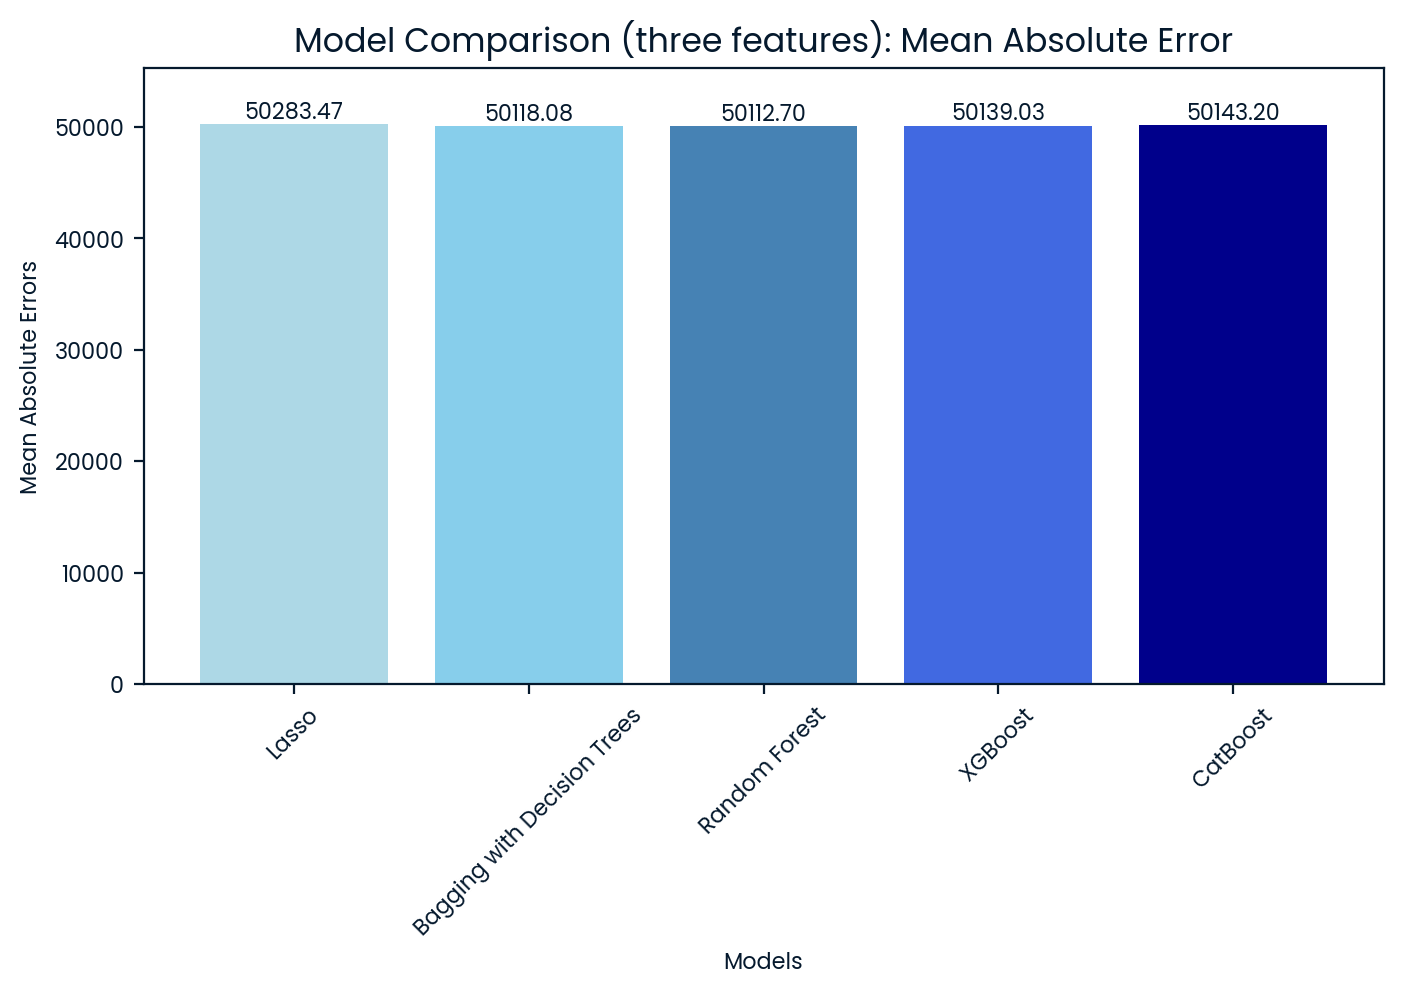

In [702]:
colors = ['#add8e6', '#87ceeb', '#4682b4', '#4169e1', '#00008b']
plt.figure(figsize=(8, 4))
bars = plt.bar(list(mae_first), list(mae_first.values()), color=colors)
plt.xlabel('Models', fontsize=8)
plt.ylabel('Mean Absolute Errors', fontsize=8)
plt.title('Model Comparison (three features): Mean Absolute Error', fontsize=12)
plt.xticks(fontsize=8, rotation=45)
plt.yticks(fontsize=8)
plt.ylim(0, max(mae_first.values()) * 1.1)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
plt.show()

In [703]:
# Initialize the RandomForestRegressor with specified hyperparameters
model_frf = RandomForestRegressor(bootstrap=True, max_depth=None, max_features='sqrt', min_samples_leaf=1, min_samples_split=10, n_estimators=300, random_state=42)

# Fit the model to the preprocessed training data
model_frf.fit(X_first_train_preprocessed_df, y_first_train)

RandomForestRegressor(max_features='sqrt', min_samples_split=10,
                      n_estimators=300, random_state=42)

In [704]:
# Use the trained RandomForestRegressor model to make predictions on the preprocessed test data
y_pred_model_frf = model_frf.predict(X_first_test_preprocessed_df)

# Calculate the Mean Absolute Error (MAE) between the actual and predicted values on the test set
mae_frf_test = mean_absolute_error(y_first_test, y_pred_model_frf)

# Print the MAE to evaluate the model's performance on the test set
print(f"Mean Absolute Error on test set: {mae_frf_test}")

Mean Absolute Error on test set: 50387.30624338776


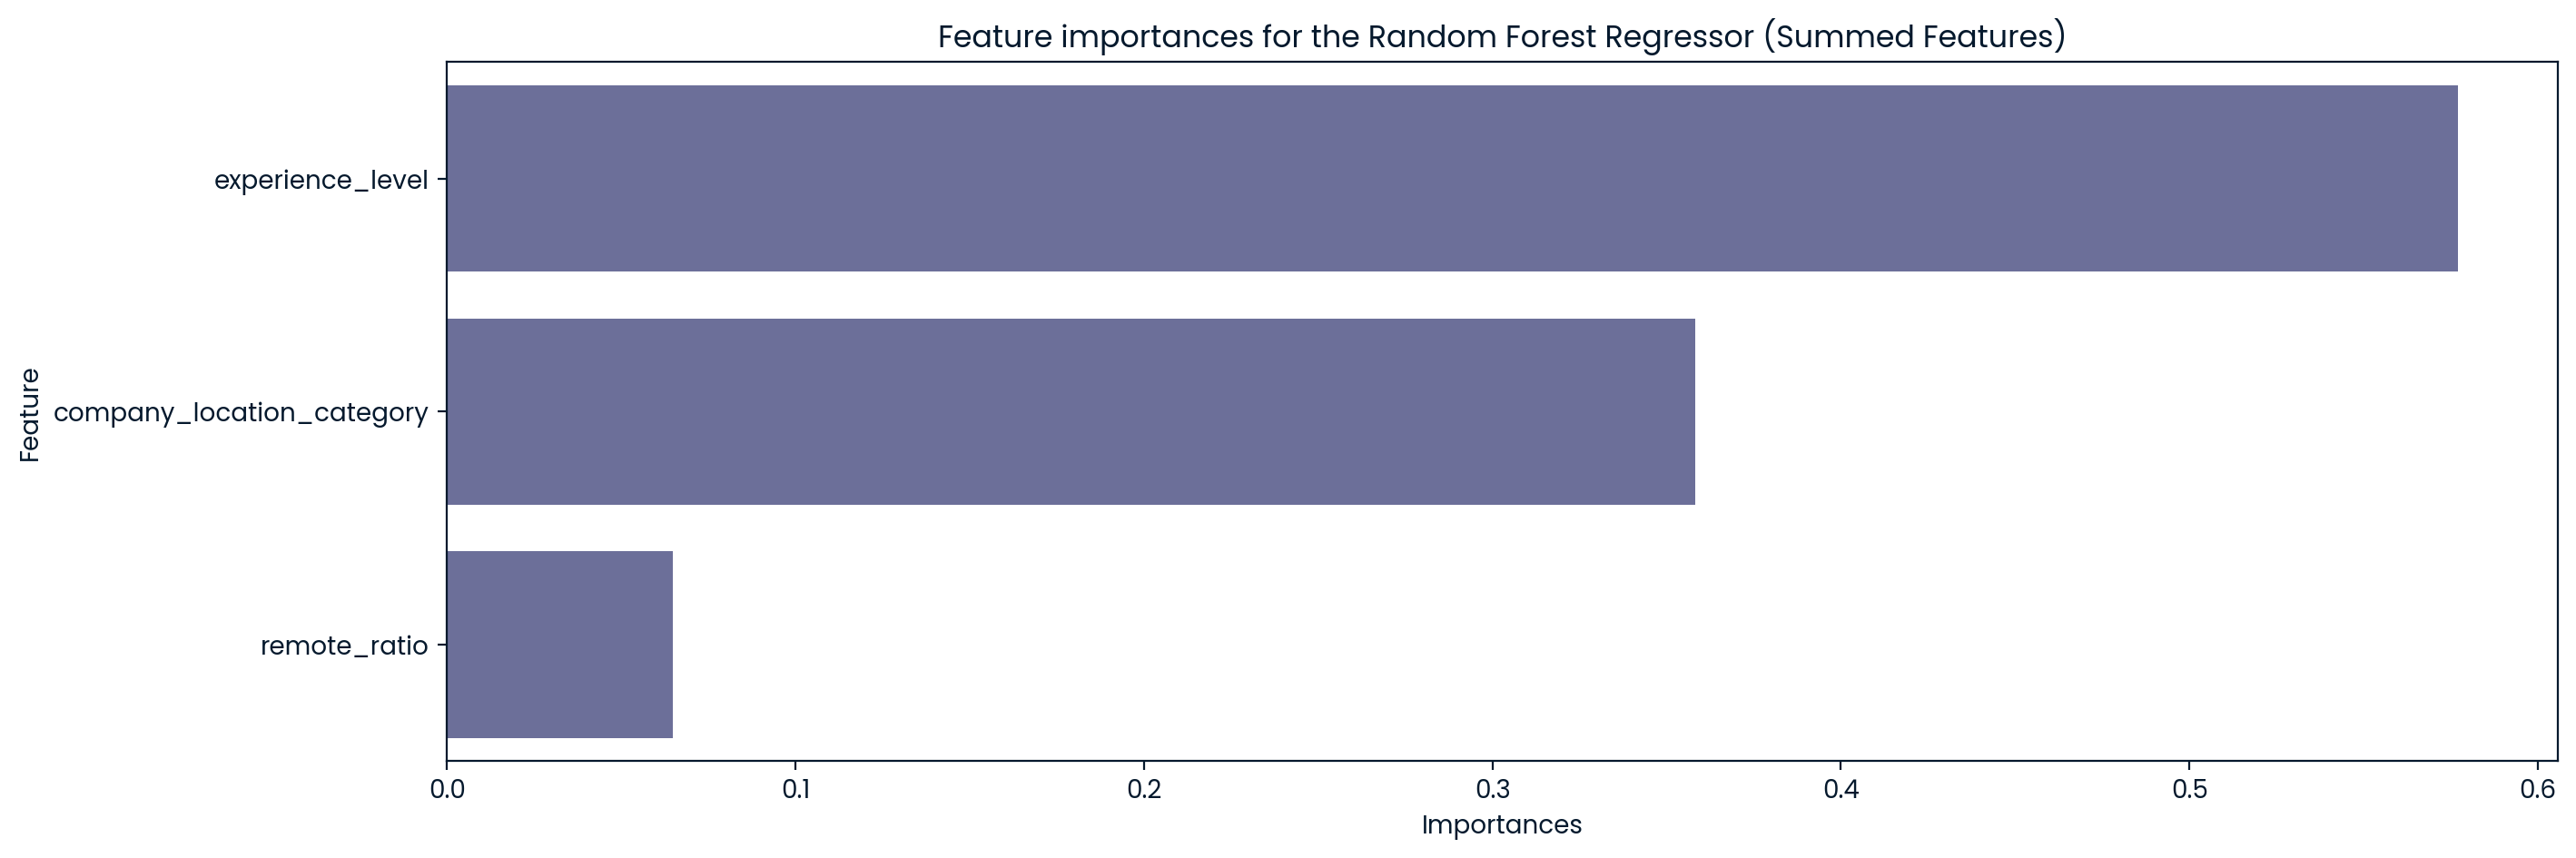

In [705]:
# Get feature importances
feature_importances = model_frf.feature_importances_

# Create a DataFrame for better visualization
features_df = pd.DataFrame({
    'Feature': X_first_test_preprocessed_df.columns,
    'Importance': feature_importances
})

filtered_experience_level = features_df[features_df['Feature'].str.startswith('cat__experience_level')]
filtered_remote_ratio = features_df[features_df['Feature'].str.startswith('cat__remote_ratio')]
filtered_company_location_category = features_df[features_df['Feature'].str.startswith('cat__company_location_category')]


sum_filtered_experience_level = filtered_experience_level['Importance'].sum()
sum_filtered_remote_ratio = filtered_remote_ratio['Importance'].sum()
sum_filtered_company_location_category = filtered_company_location_category['Importance'].sum()

# Create a new DataFrame with the summed importances
summed_importances = pd.DataFrame({
    'Feature': ['experience_level', 'remote_ratio', 'company_location_category'],
    'Importances': [sum_filtered_experience_level, sum_filtered_remote_ratio, sum_filtered_company_location_category]
})

# Replace the original features with their summed importances
importance_FRF = features_df[~features_df['Feature'].str.startswith(('cat__experience_level', 'cat__remote_ratio', 'cat__company_location_category'))]
importance_FRF = pd.concat([importance_FRF, summed_importances], ignore_index=True)
importance_FRF = importance_FRF.sort_values(by='Importances', ascending=False)

plt.figure(figsize=(15,5))
sns.barplot(x='Importances', y='Feature', data=importance_FRF)
plt.title('Feature importances for the Random Forest Regressor (Summed Features)')
plt.show()

Experience level is the most important predictor in the Random Forest Regressor model with three features.

Expand your model by incorporating additional features, such as company size and employment type. Evaluate its performance, what improves, and what doesn’t? 

## Second model:
with features:

- experience_level,
- company_location_category,
- remote_ratio,
- company_size,
- employment_type

and target: salary_in_usd.

In [706]:
X_second = df[['experience_level', 'company_location_category', 'remote_ratio', 'company_size', 'employment_type']]
y_second = df['salary_in_usd']

In [707]:
# Split the data into training, validation, and test sets
X_second_train, X_second_temp, y_second_train, y_second_temp = train_test_split(X_second, y_second, test_size=0.3, random_state=42)
X_second_val, X_second_test, y_second_val, y_second_test = train_test_split(X_second_temp, y_second_temp, test_size=0.5, random_state=42)

In [708]:
# Define column transformer with one-hot encoding(dropping the first category) and scaling 
preprocessor_second = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), 
    ['experience_level', 'company_location_category', 'remote_ratio', 'company_size', 'employment_type'])
])

In [709]:
# Fit and transform the training data; only transform the test data
X_second_train_preprocessed = preprocessor_second.fit_transform(X_second_train)
X_second_val_preprocessed = preprocessor_second.transform(X_second_val)
X_second_test_preprocessed = preprocessor_second.transform(X_second_test)

In [710]:
# Convert the result to a DataFrame
X_second_train_preprocessed_df = pd.DataFrame(X_second_train_preprocessed.toarray(), columns=preprocessor_second.get_feature_names_out())
X_second_val_preprocessed_df = pd.DataFrame(X_second_val_preprocessed.toarray(), columns=preprocessor_second.get_feature_names_out())
X_second_test_preprocessed_df = pd.DataFrame(X_second_test_preprocessed.toarray(), columns=preprocessor_second.get_feature_names_out())

In [711]:
# Check the results
print(X_second_train_preprocessed_df.shape, X_second_val_preprocessed_df.shape, X_second_test_preprocessed_df.shape)

(40035, 21) (8579, 21) (8580, 21)


The same five models and the same grids, now on five features.

In [712]:
# Same grids as above (GRIDS), searched on five features.
# Configurations selected for the five-feature model
models_second = {
    'Lasso': Lasso(alpha=5),
    'Bagging with Decision Trees': BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=None, max_features=None,
            min_samples_leaf=4, min_samples_split=15, random_state=42),
        random_state=42),
    'Random Forest': RandomForestRegressor(bootstrap=True, max_depth=None,
        max_features='sqrt', min_samples_leaf=1, min_samples_split=10,
        n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBRegressor(colsample_bytree=0.8, learning_rate=0.2,
        max_depth=3, n_estimators=100, subsample=0.8,
        objective='reg:squarederror', random_state=42),
    'CatBoost': CatBoostRegressor(depth=4, iterations=200, learning_rate=0.1,
        silent=True, random_seed=42),
}

mae_second = {}
for name, m in models_second.items():
    m.fit(X_second_train_preprocessed_df, y_second_train)
    mae_second[name] = mean_absolute_error(
        y_second_val, m.predict(X_second_val_preprocessed_df))
    print(f"{name:30s} MAE {mae_second[name]:10.2f}")

Lasso                          MAE   50281.22
Bagging with Decision Trees    MAE   50099.12
Random Forest                  MAE   50074.86
XGBoost                        MAE   50109.77
CatBoost                       MAE   50124.50


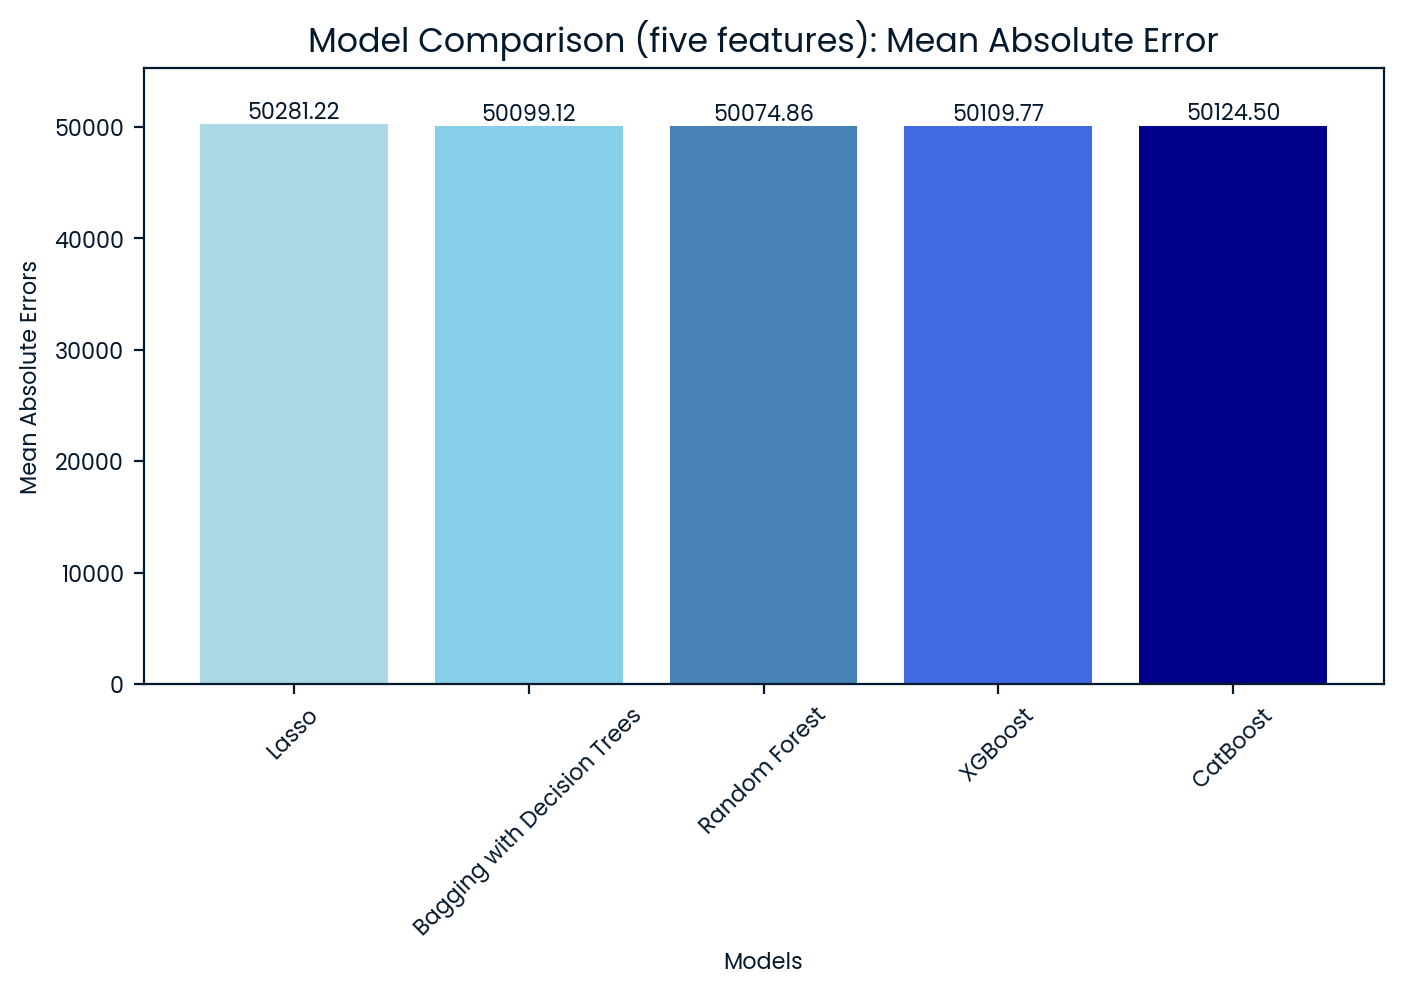

In [713]:
plt.figure(figsize=(8, 4))
bars = plt.bar(list(mae_second), list(mae_second.values()), color=colors)
plt.xlabel('Models', fontsize=8)
plt.ylabel('Mean Absolute Errors', fontsize=8)
plt.title('Model Comparison (five features): Mean Absolute Error', fontsize=12)
plt.xticks(fontsize=8, rotation=45)
plt.yticks(fontsize=8)
plt.ylim(0, max(mae_second.values()) * 1.1)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
plt.show()

In [714]:
# Initialize the RandomForestRegressor with specified hyperparameters
model_frf_second = RandomForestRegressor(bootstrap=True, max_depth=None, max_features='sqrt', min_samples_leaf=1, min_samples_split=10, n_estimators=100, random_state=42)

# Fit the model to the preprocessed training data
model_frf_second.fit(X_second_train_preprocessed_df, y_second_train)

RandomForestRegressor(max_features='sqrt', min_samples_split=10,
                      random_state=42)

In [715]:
# Use the trained RandomForestRegressor model to make predictions on the preprocessed test data
y_pred_model_frf_second = model_frf_second.predict(X_second_test_preprocessed_df)

# Calculate the Mean Absolute Error (MAE) between the actual and predicted values on the test set
mae_frf_test_second = mean_absolute_error(y_second_test, y_pred_model_frf_second)

# Print the MAE to evaluate the model's performance on the test set
print(f"Mean Absolute Error on test set: {mae_frf_test_second}")

Mean Absolute Error on test set: 50310.14258713237


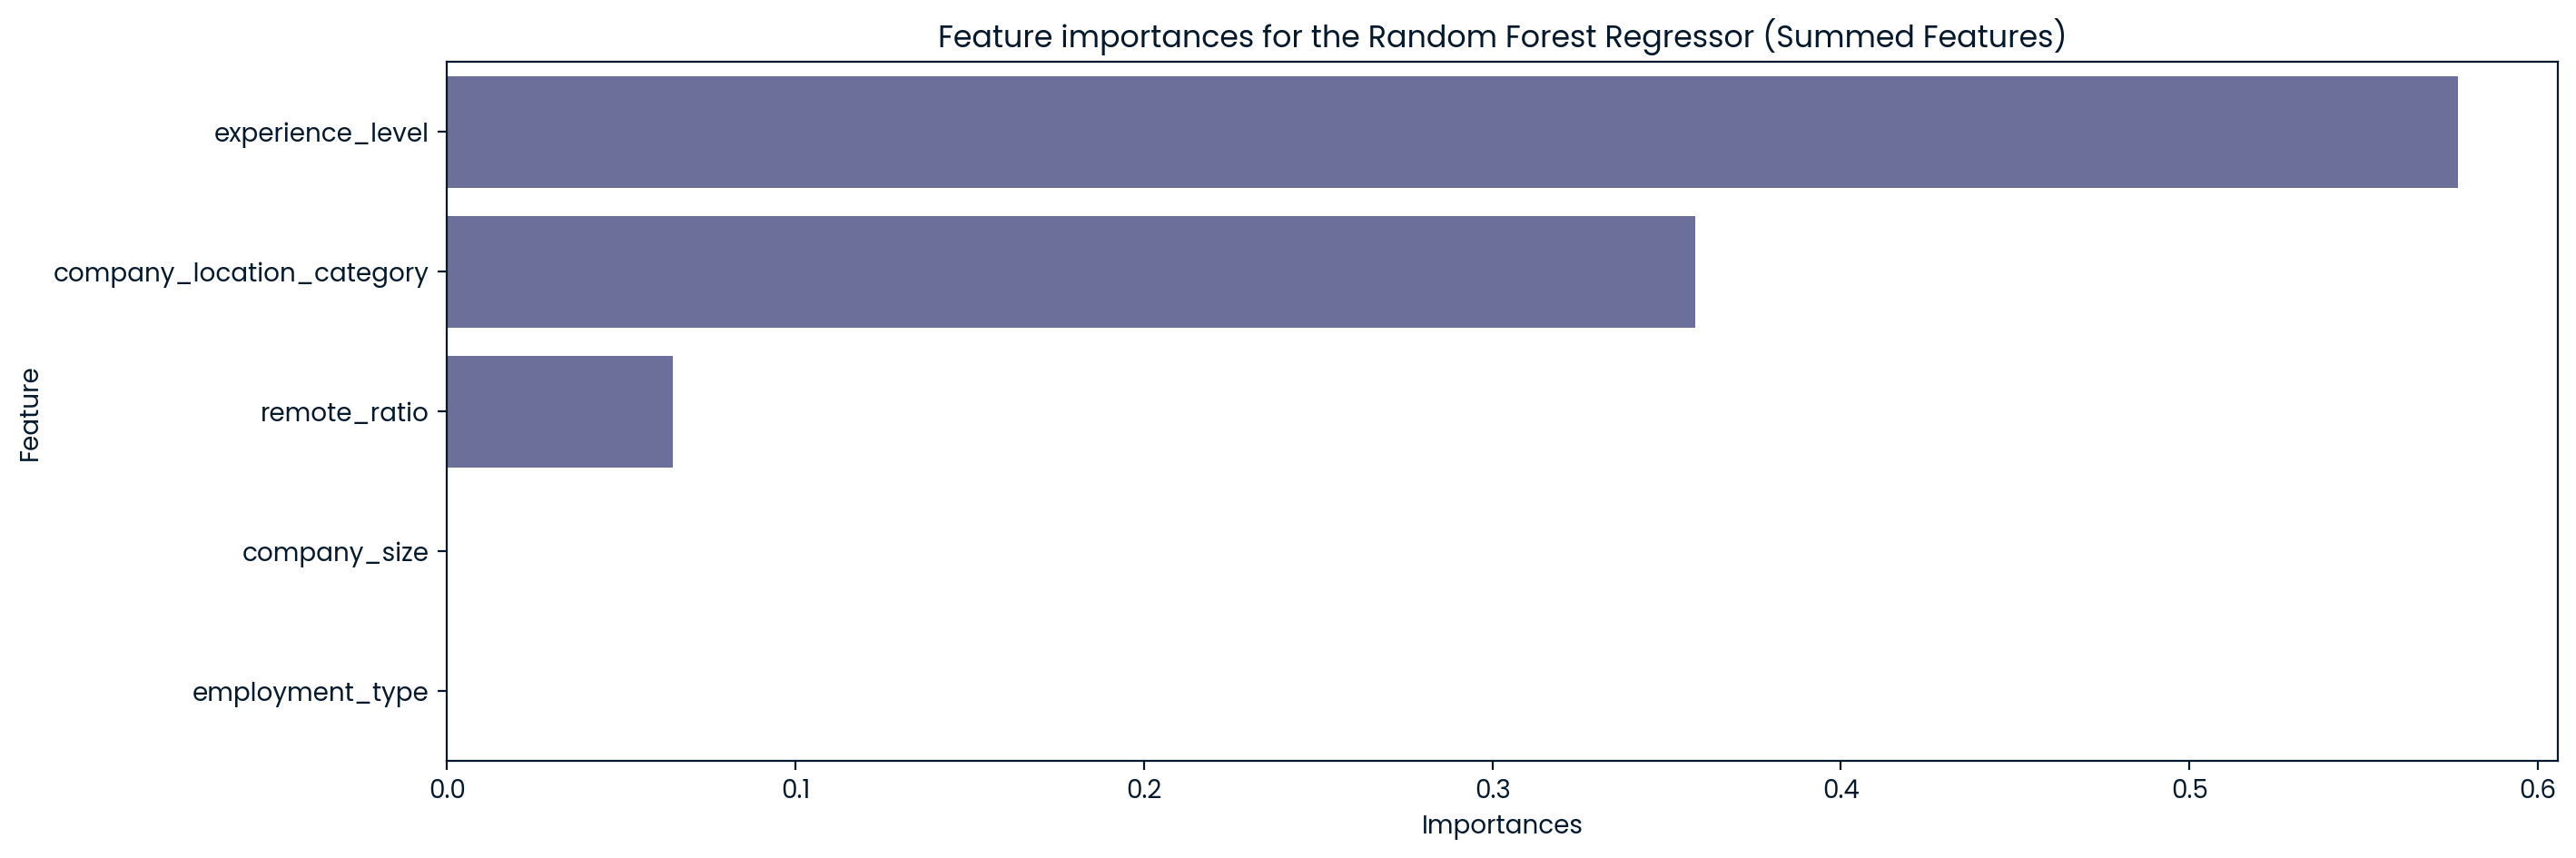

In [716]:
# Get feature importances
feature_importances_second = model_frf_second.feature_importances_

# Create a DataFrame for better visualization
features_df_second = pd.DataFrame({
    'Feature': X_second_test_preprocessed_df.columns,
    'Importance': feature_importances_second
})

filtered_experience_level = features_df[features_df['Feature'].str.startswith('cat__experience_level')]
filtered_remote_ratio = features_df[features_df['Feature'].str.startswith('cat__remote_ratio')]
filtered_company_location_category = features_df[features_df['Feature'].str.startswith('cat__company_location_category')]
filtered_company_size = features_df[features_df['Feature'].str.startswith('cat__company_size')]
filtered_employment_type = features_df[features_df['Feature'].str.startswith('cat__employment_type')]

sum_filtered_experience_level = filtered_experience_level['Importance'].sum()
sum_filtered_remote_ratio = filtered_remote_ratio['Importance'].sum()
sum_filtered_company_location_category = filtered_company_location_category['Importance'].sum()
sum_filtered_company_size = filtered_company_size['Importance'].sum()
sum_filtered_employment_type = filtered_employment_type['Importance'].sum()

# Create a new DataFrame with the summed importances
summed_importances_second = pd.DataFrame({
    'Feature': ['experience_level', 'remote_ratio', 'company_location_category', 'company_size', 'employment_type'],
    'Importances': [sum_filtered_experience_level, sum_filtered_remote_ratio, sum_filtered_company_location_category, sum_filtered_company_size, sum_filtered_employment_type]
})

# Replace the original features with their summed importances
importance_FRF_second = features_df_second[~features_df_second['Feature'].str.startswith(('cat__experience_level', 'cat__remote_ratio', 'cat__company_location_category', 'cat__company_size', 'cat__employment_type'))]
importance_FRF_second = pd.concat([importance_FRF_second, summed_importances_second], ignore_index=True)
importance_FRF_second = importance_FRF_second.sort_values(by='Importances', ascending=False)

plt.figure(figsize=(15,5))
sns.barplot(x='Importances', y='Feature', data=importance_FRF_second)
plt.title('Feature importances for the Random Forest Regressor (Summed Features)')
plt.show()

## Third model:
with features:

- work_year
- experience_level
- employment_type
- salary_currency
- remote_ratio
- company_size
- role_category
- employee_residence_category
- company_location_category

and target: salary_in_usd.

In [717]:
# Select features and target variable for modeling
X = df[['work_year', 'experience_level', 'employment_type', 'salary_currency', 'remote_ratio', 'company_size', 'role_category', 'employee_residence_category', 'company_location_category']]
y = df[['salary_in_usd']]

In [718]:
# Split the data into training, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5,  random_state=42)

In [719]:
# Define column transformer with one-hot encoding(dropping the first category) and scaling 
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), 
    ['work_year', 'experience_level', 'employment_type', 'salary_currency', 'remote_ratio', 'company_size', 'role_category', 'employee_residence_category', 'company_location_category'])
])

In [720]:
# Fit and transform the training data; only transform the test data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_val_preprocessed = preprocessor.transform(X_val)
X_test_preprocessed = preprocessor.transform(X_test)

In [721]:
# Convert the result to a DataFrame
X_train_preprocessed_df = pd.DataFrame(X_train_preprocessed.toarray(), columns=preprocessor.get_feature_names_out())
X_val_preprocessed_df = pd.DataFrame(X_val_preprocessed.toarray(), columns=preprocessor.get_feature_names_out())
X_test_preprocessed_df = pd.DataFrame(X_test_preprocessed.toarray(), columns=preprocessor.get_feature_names_out())

In [722]:
# Check the results
print(X_train_preprocessed_df.head())
print(X_val_preprocessed_df.head())
print(X_test_preprocessed_df.head())
print(X_train_preprocessed_df.shape, X_val_preprocessed_df.shape, X_test_preprocessed_df.shape)

   cat__work_year_2021  ...  cat__company_location_category_Western Europe
0                  0.0  ...                                            0.0
1                  0.0  ...                                            0.0
2                  0.0  ...                                            0.0
3                  0.0  ...                                            0.0
4                  0.0  ...                                            0.0

[5 rows x 95 columns]
   cat__work_year_2021  ...  cat__company_location_category_Western Europe
0                  0.0  ...                                            0.0
1                  0.0  ...                                            0.0
2                  0.0  ...                                            0.0
3                  0.0  ...                                            0.0
4                  0.0  ...                                            0.0

[5 rows x 95 columns]
   cat__work_year_2021  ...  cat__company_location_cat

The same five models and the same grids, now on nine features.

In [723]:
# Same grids as above (GRIDS), searched on nine features.
# Configurations selected for the nine-feature model
models_third = {
    'Lasso': Lasso(alpha=4),
    'Bagging with Decision Trees': BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=None, max_features='sqrt',
            min_samples_leaf=1, min_samples_split=15, random_state=42),
        random_state=42),
    'Random Forest': RandomForestRegressor(bootstrap=False, max_depth=None,
        max_features='sqrt', min_samples_leaf=2, min_samples_split=2,
        n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBRegressor(colsample_bytree=0.8, learning_rate=0.1,
        max_depth=7, n_estimators=200, subsample=1.0,
        objective='reg:squarederror', random_state=42),
    'CatBoost': CatBoostRegressor(depth=8, iterations=200, learning_rate=0.1,
        silent=True, random_seed=42),
}

mae_third = {}
for name, m in models_third.items():
    m.fit(X_train_preprocessed_df, y_train)
    mae_third[name] = mean_absolute_error(
        y_val, m.predict(X_val_preprocessed_df))
    print(f"{name:30s} MAE {mae_third[name]:10.2f}")

Lasso                          MAE   46341.44
Bagging with Decision Trees    MAE   45771.49
Random Forest                  MAE   45704.72
XGBoost                        MAE   45569.99
CatBoost                       MAE   45634.99


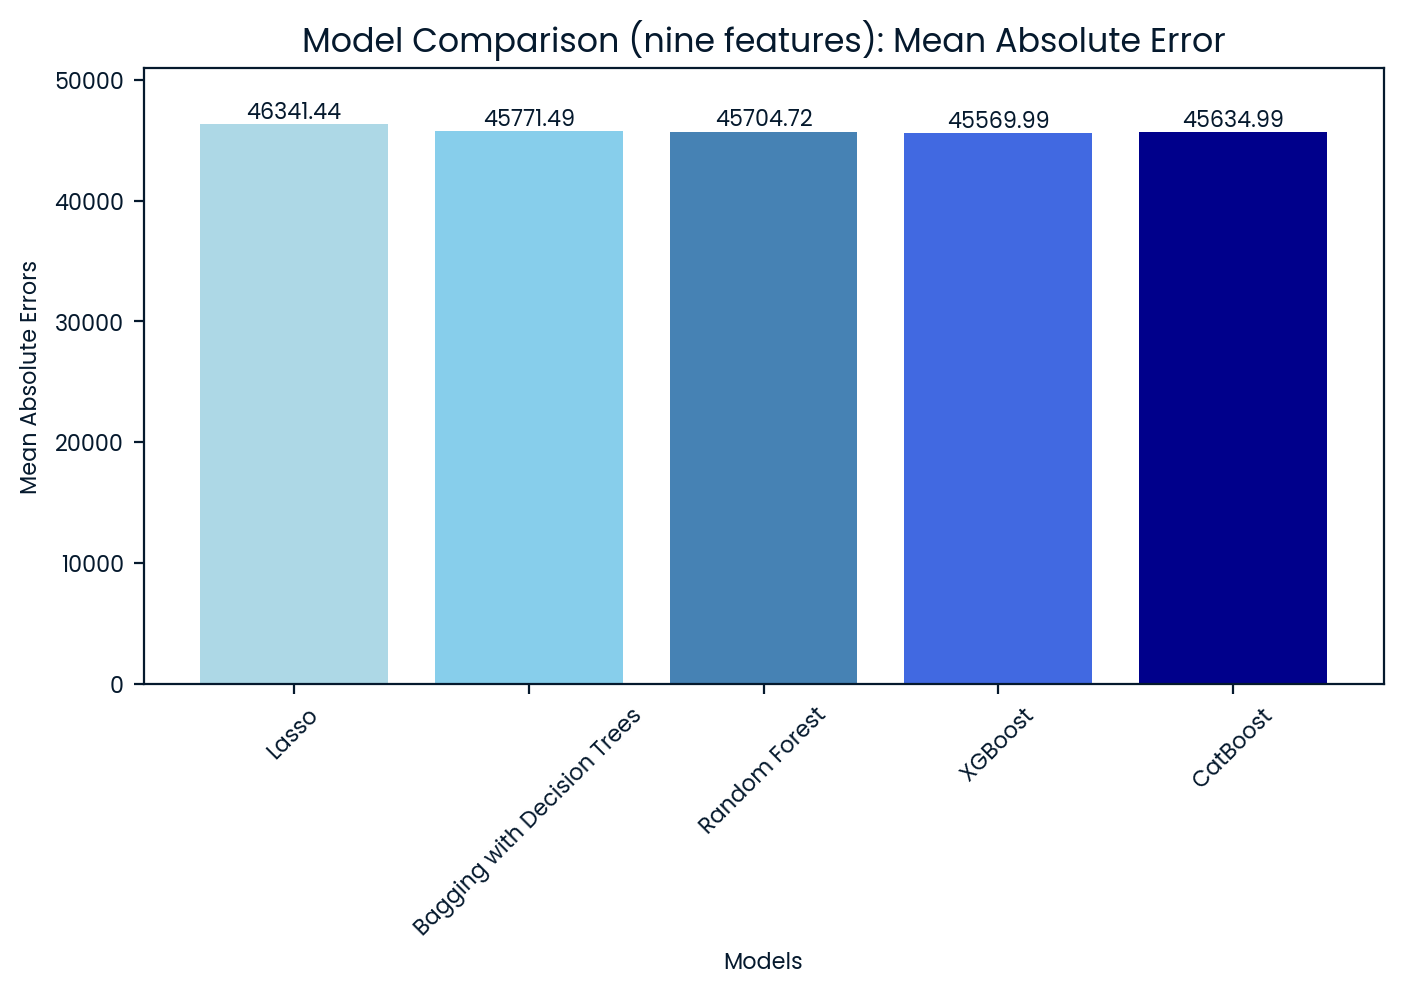

In [724]:
plt.figure(figsize=(8, 4))
bars = plt.bar(list(mae_third), list(mae_third.values()), color=colors)
plt.xlabel('Models', fontsize=8)
plt.ylabel('Mean Absolute Errors', fontsize=8)
plt.title('Model Comparison (nine features): Mean Absolute Error', fontsize=12)
plt.xticks(fontsize=8, rotation=45)
plt.yticks(fontsize=8)
plt.ylim(0, max(mae_third.values()) * 1.1)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
plt.show()

The grid for XGBoost has 108 combinations, and with 5 folds that is 540 fits. Was that work necessary? Below I take ten random combinations out of the same grid with 3 folds, which is 30 fits, and compare the result.

In [725]:
# Does the tuning matter? Ten random draws instead of the full 108-point grid.
search = RandomizedSearchCV(
    xgb.XGBRegressor(objective='reg:squarederror', random_state=42),
    param_distributions=GRIDS['XGBoost'], n_iter=10, cv=3,
    scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
search.fit(X_train_preprocessed_df, y_train)

mae_rs = mean_absolute_error(y_val, search.best_estimator_.predict(X_val_preprocessed_df))

print("Randomized search, 10 of 108 candidates, 3-fold CV")
print("  params :", search.best_params_)
print(f"  val MAE: {mae_rs:,.1f}")
print(f"\nFull grid search, 108 candidates, 5-fold CV (run once, recorded above)")
print("  params : colsample_bytree=0.8, learning_rate=0.1, max_depth=7, "
      "n_estimators=200, subsample=1.0")
print(f"  val MAE: {mae_third['XGBoost']:,.1f}")

Randomized search, 10 of 108 candidates, 3-fold CV
  params : {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
  val MAE: 45,607.7

Full grid search, 108 candidates, 5-fold CV (run once, recorded above)
  params : colsample_bytree=0.8, learning_rate=0.1, max_depth=7, n_estimators=200, subsample=1.0
  val MAE: 45,570.0


All five models give similar MAE values. We use the MAE metric because our target variable `salary_in_usd` is right-skewed. The smallest is XGBoost with 45,569.99, and the four tree models lie in a range of about 200 USD, from 45,569.99 to 45,771.49. Only Lasso is clearly behind, by about 770, which says there is some non-linearity in the data but not much of it.

The randomized search is the interesting part. Ten random combinations out of 108, with 3 folds instead of 5, gave 45,607.7 against 45,570.0 from the full grid. That is a difference of 38 USD, or 0.08%, and three of the five parameters came out the same. Eighteen times less computation produced practically the same model. The tuning is not where the result comes from.

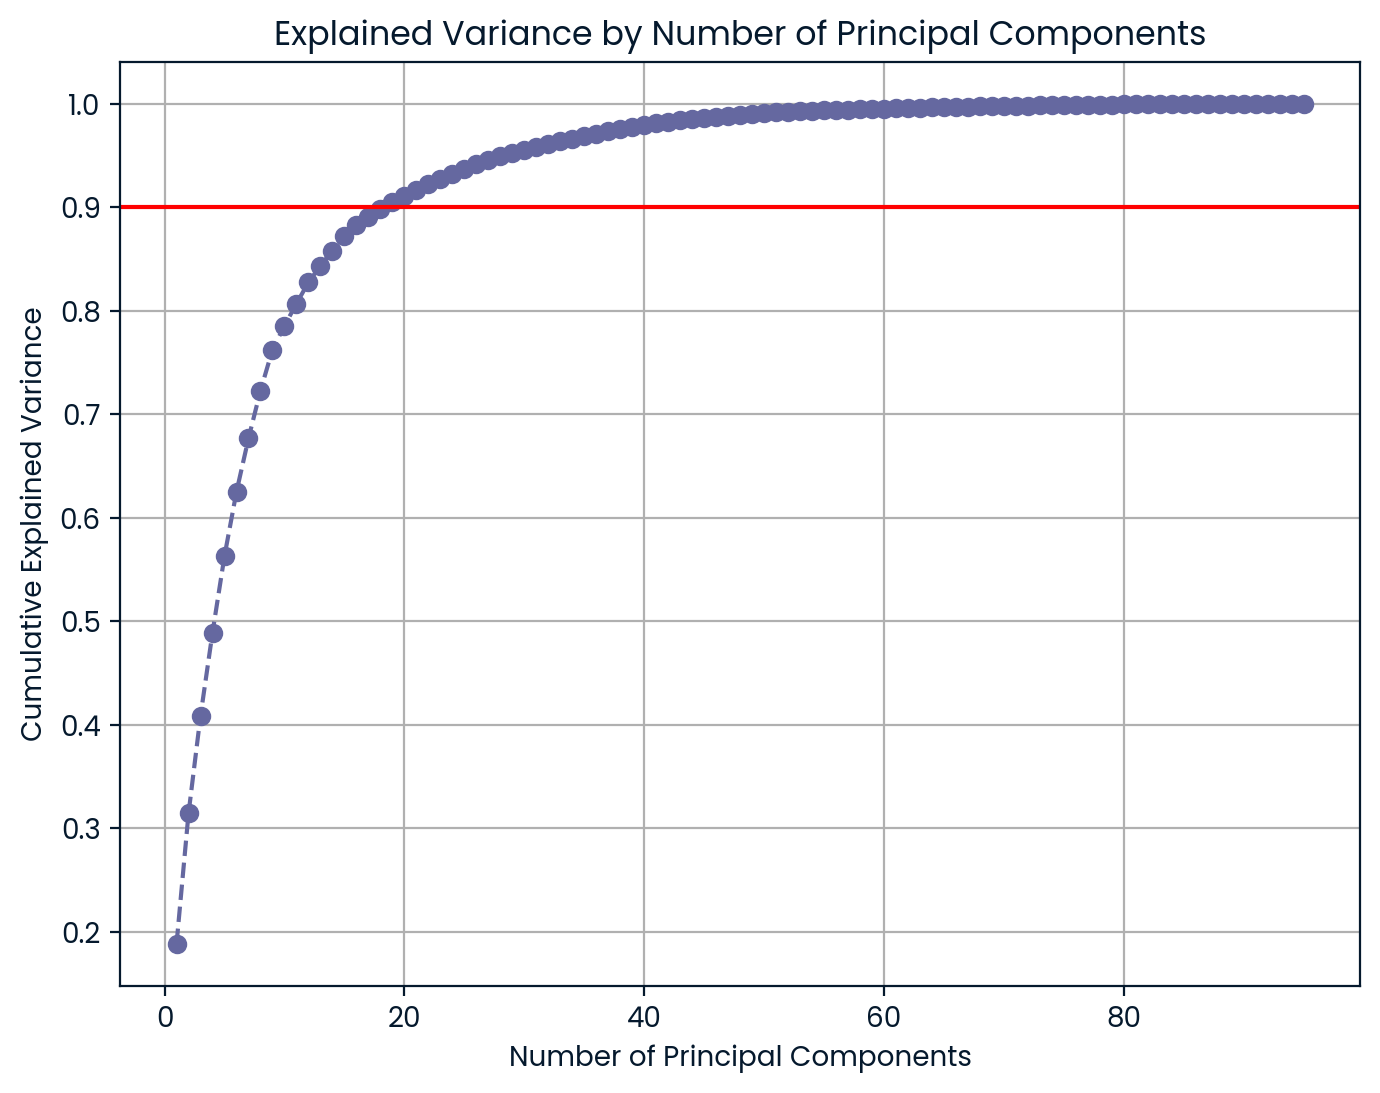

Number of components to retain at least 90% variance: 19


In [726]:
# Applying PCA
pca = PCA()
pca.fit(X_train_preprocessed_df)

# Plotting Cumulative Explained Variance
explained_variance_ratio = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 6))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker='o', linestyle='--')
plt.title('Explained Variance by Number of Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid()

plt.axhline(y=0.90, color='r', linestyle='-')
plt.show()

# Determine number of components for 90% variance explained
n_components_90 = np.argmax(explained_variance_ratio >= 0.90) + 1
print(f'Number of components to retain at least 90% variance: {n_components_90}')

In [727]:
# Applying PCA
pca = PCA(n_components=19)
X_train_pca = pca.fit_transform(X_train_preprocessed_df)
X_val_pca = pca.transform(X_val_preprocessed_df)  

# Training a model
model = xgb.XGBRegressor(colsample_bytree=0.8, learning_rate=0.1, max_depth=7, n_estimators=200, subsample=1.0, random_state=42)
model.fit(X_train_pca, y_train)

# Predicting and Evaluating
y_pred = model.predict(X_val_pca)  

# Calculating MAE
mae = mean_absolute_error(y_val, y_pred)
print(f"Mean Absolute Error on validation set: {mae}")

Mean Absolute Error on validation set: 45630.034785158525


PCA did not improve the MAE, and looking at it now I do not think it could have.

PCA is built for continuous variables. All our features are categorical and one-hot encoded, so every column is 0 or 1. The variance of such a column is p(1-p), which is at most 0.25 and is largest when the category splits the data in half. So PCA ranks our columns by how balanced they are, not by how much they say about salary. A category holding 0.1% of the rows has a variance near zero and is almost ignored — and later in this notebook I show that the small role categories are exactly the ones carrying extra signal.

The '90% of variance' rule I used to pick 19 components has the same problem. The total variance of a set of dummies is just the sum of p(1-p), and it has nothing to do with how much of the salary is explained.

There is one more reason, which has nothing to do with the encoding. A tree splits on one feature at a time, and PCA replaces the features with dense linear combinations of all 164 columns. That removes exactly the structure a tree works with. For categorical data the proper counterpart of PCA is multiple correspondence analysis, but before gradient boosting that is not needed either.

I kept this part in the notebook because the result is not 'it did not work'. It is 'it could not have worked, and here is why'.

For the rest of the analysis I use the XGBoost Regressor, which had the smallest MAE.

In [728]:
# Splitting the test dataset into two parts for evaluation

# First part of the test dataset (first 20 rows)
salary_test_1 = X_test_preprocessed_df.iloc[:20, :]
y_test_1 = y_test.iloc[:20, :]

# Second part of the test dataset (from row 20 onwards)
salary_test_2 = X_test_preprocessed_df.iloc[20:, :]
y_test_2 = y_test.iloc[20:, :]

In [729]:
# Training a model using XGBoost Regressor
# Setting hyperparameters: colsample_bytree=0.8, learning_rate=0.1, max_depth=7, n_estimators=200, subsample=1.0
model_xgb = xgb.XGBRegressor(colsample_bytree=0.8, learning_rate=0.1, max_depth=7, n_estimators=200, subsample=1.0, random_state=42)

# Fitting the model on the preprocessed training data
model_xgb.fit(X_train_preprocessed_df, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=7, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=200, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [730]:
# Predicting the target variable for the second part of the test dataset using the best XGBoost model
y_pred_xg_t = model_xgb.predict(salary_test_2)

# Calculating the Mean Absolute Error (MAE) for the predictions on the second part of the test dataset
mae_xgb_test = mean_absolute_error(y_test_2, y_pred_xg_t)

# Printing the MAE to evaluate the model's performance on the test set
print(f"Mean Absolute Error on test set: {mae_xgb_test}")

Mean Absolute Error on test set: 45597.32195280556


## Prediction intervals

A single predicted number is not very useful on its own. If the model says 150,000, the real salary of that person will be something else, and the question is how far off it can reasonably be.

In the earlier version of this notebook I answered that with `prediction ± MAE`, where the MAE was written in as the constant 45,597. That is not a weak interval, it is the wrong quantity. MAE is the average size of the error, and asking how often the error is smaller than the average error does not give 90%. Below I check what it actually gave.

To build a real interval I take the residuals of the model on the validation set, which the model has not seen, and use their 5th and 95th percentiles. That gives a 90% interval. The coverage is then measured on the test set, so the interval is not checked on the same rows it was built from.


In [731]:
# Prediction intervals from the empirical residual distribution.
# The quantiles come from the validation set, which the model has not seen,
# so the interval is not calibrated on the same rows it is later checked on.
resid_val = np.asarray(y_val).ravel() - model_xgb.predict(X_val_preprocessed_df)
q_lo, q_hi = np.percentile(resid_val, [5, 95])

print(f"Validation residual quantiles:  5% {q_lo:>10,.0f}   95% {q_hi:>10,.0f}")
print(f"The interval used before was symmetric: +/- 45,597")

def predict_with_interval(row):
    """Point prediction plus a 90% interval taken from the validation residuals."""
    p = model_xgb.predict(np.asarray(row).reshape(1, -1))[0]
    return p + q_lo, p, p + q_hi

Validation residual quantiles:  5%    -79,411   95%    104,274
The interval used before was symmetric: +/- 45,597


In [732]:
# How often does the interval actually contain the true salary?
pred_2 = model_xgb.predict(salary_test_2)
actual_2 = np.asarray(y_test_2).ravel()
low_2, high_2 = pred_2 + q_lo, pred_2 + q_hi
covered = (actual_2 >= low_2) & (actual_2 <= high_2)

print(f"Quantile interval   nominal 90%   actual {covered.mean()*100:5.1f}%"
      f"   mean width {np.mean(high_2 - low_2):>10,.0f}   n = {len(actual_2)}")

old = 45597.32
cov_old = (np.abs(actual_2 - pred_2) <= old).mean()
print(f"Old +/- MAE interval              actual {cov_old*100:5.1f}%"
      f"   mean width {2*old:>10,.0f}")

Quantile interval   nominal 90%   actual  89.4%   mean width    183,685   n = 8560
Old +/- MAE interval              actual  58.8%   mean width     91,195


The old interval contained the true salary in 58.8% of cases, while presenting itself as a prediction interval. The quantile interval gives 89.4% against the nominal 90%, measured on 8,560 rows.

The honest version is twice as wide: 183,685 against 91,195. With a median salary of 150,000 that means the 90% interval is wider than the salary itself. This is not a flaw of the method, it is what the data looks like. Two people with the same experience level, role and country really are paid very differently.

The interval is also not symmetric: 79,411 below the prediction and 104,274 above it. The upper tail is a third longer, so the model misses high salaries by more than it misses low ones.

In [733]:
# Does the spread of the residuals grow with the predicted salary?
band = pd.qcut(pd.Series(model_xgb.predict(X_val_preprocessed_df)), 4,
               labels=['Q1 lowest', 'Q2', 'Q3', 'Q4 highest'])
spread = (pd.DataFrame({'band': band, 'resid': resid_val})
          .groupby('band', observed=True)['resid']
          .agg(n='size', q05=lambda s: np.percentile(s, 5),
               q95=lambda s: np.percentile(s, 95)))
spread['width'] = spread['q95'] - spread['q05']
print(spread.round(0).to_string())

               n      q05       q95     width
band                                         
Q1 lowest   2149 -55881.0   70542.0  126422.0
Q2          2146 -76212.0   99737.0  175949.0
Q3          2178 -82112.0  107862.0  189974.0
Q4 highest  2106 -97122.0  134561.0  231683.0


One width for everybody assumes the model is equally wrong everywhere. That is easy to check, and it is not true: the spread of the residuals almost doubles from the lowest quarter of the predictions to the highest. It also explains why the lower bound went below zero for the cheapest predictions. A width of 183,685 is far too much down there.

In [734]:
# Intervals conditional on the predicted level, instead of one width for everyone
pred_val = model_xgb.predict(X_val_preprocessed_df)
_, bins = pd.qcut(pred_val, 4, retbins=True)
bins[0], bins[-1] = -np.inf, np.inf
lab = ['Q1 lowest', 'Q2', 'Q3', 'Q4 highest']

band_val = pd.Series(pd.cut(pred_val, bins=bins, labels=lab))
q = (pd.DataFrame({'b': band_val, 'r': resid_val})
     .groupby('b', observed=True)['r']
     .agg(lo=lambda s: np.percentile(s, 5), hi=lambda s: np.percentile(s, 95)))

band_2 = pd.Series(pd.cut(pred_2, bins=bins, labels=lab))
lo_b = pred_2 + band_2.map(q['lo']).astype(float).values
hi_b = pred_2 + band_2.map(q['hi']).astype(float).values
cov_b = (actual_2 >= lo_b) & (actual_2 <= hi_b)

summary = (pd.DataFrame({'band': band_2.values, 'const_in': covered, 'band_in': cov_b,
                         'const_w': high_2 - low_2, 'band_w': hi_b - lo_b})
           .groupby('band', observed=True)
           .agg(n=('const_in', 'size'),
                const_cov=('const_in', lambda s: round(s.mean() * 100, 1)),
                band_cov=('band_in', lambda s: round(s.mean() * 100, 1)),
                const_width=('const_w', lambda s: round(s.mean())),
                band_width=('band_w', lambda s: round(s.mean()))))
print(summary.to_string())
print(f"\noverall    constant {covered.mean()*100:5.1f}%    banded {cov_b.mean()*100:5.1f}%")

               n  const_cov  band_cov  const_width  band_width
band                                                          
Q1 lowest   2135       97.1      88.7       183685      126422
Q2          2157       91.7      89.2       183685      175949
Q3          2166       86.8      88.4       183685      189974
Q4 highest  2102       82.1      91.0       183685      231683

overall    constant  89.4%    banded  89.3%


In [735]:
# How many bands is too many?
for k in [1, 2, 4, 8, 16, 32, 64]:
    if k == 1:
        bv = pd.Series(np.zeros(len(pred_val)))
        b2 = pd.Series(np.zeros(len(pred_2)))
    else:
        _, bb = pd.qcut(pred_val, k, retbins=True, duplicates='drop')
        bb[0], bb[-1] = -np.inf, np.inf
        bv = pd.Series(pd.cut(pred_val, bins=bb, labels=False))
        b2 = pd.Series(pd.cut(pred_2, bins=bb, labels=False))

    qq = (pd.DataFrame({'b': bv, 'r': resid_val}).groupby('b', observed=True)['r']
          .agg(lo=lambda s: np.percentile(s, 5), hi=lambda s: np.percentile(s, 95)))
    lo = pred_2 + b2.map(qq['lo']).astype(float).values
    hi = pred_2 + b2.map(qq['hi']).astype(float).values
    cov = (actual_2 >= lo) & (actual_2 <= hi)
    per = pd.Series(cov).groupby(b2.values).mean() * 100

    print(f"{qq.shape[0]:3d} bands   {len(pred_val)//qq.shape[0]:5d} rows/band   "
          f"overall {cov.mean()*100:5.1f}%   "
          f"by band {per.min():5.1f}–{per.max():5.1f}   "
          f"width {np.mean(hi - lo):8.0f}")

  1 bands    8579 rows/band   overall  89.4%   by band  89.4– 89.4   width   183685
  2 bands    4289 rows/band   overall  89.6%   by band  89.1– 90.0   width   183546
  4 bands    2144 rows/band   overall  89.3%   by band  88.4– 91.0   width   180831
  8 bands    1072 rows/band   overall  89.0%   by band  86.6– 91.4   width   178296
 16 bands     536 rows/band   overall  88.8%   by band  86.1– 91.7   width   176846
 30 bands     285 rows/band   overall  88.9%   by band  82.8–100.0   width   177652
 50 bands     171 rows/band   overall  88.1%   by band  66.7–100.0   width   174394


In [736]:
# Always judge coverage on the same four groups, whatever k was used to calibrate
_, qb = pd.qcut(pred_val, 4, retbins=True)
qb[0], qb[-1] = -np.inf, np.inf
grp = pd.Series(pd.cut(pred_2, bins=qb, labels=['Q1', 'Q2', 'Q3', 'Q4']))

rows = []
for k in [1, 2, 4, 8, 16, 32, 50]:
    if k == 1:
        bv = pd.Series(np.zeros(len(pred_val)))
        b2 = pd.Series(np.zeros(len(pred_2)))
    else:
        _, bb = pd.qcut(pred_val, k, retbins=True, duplicates='drop')
        bb[0], bb[-1] = -np.inf, np.inf
        bv = pd.Series(pd.cut(pred_val, bins=bb, labels=False))
        b2 = pd.Series(pd.cut(pred_2, bins=bb, labels=False))

    qq = (pd.DataFrame({'b': bv, 'r': resid_val}).groupby('b', observed=True)['r']
          .agg(lo=lambda s: np.percentile(s, 5), hi=lambda s: np.percentile(s, 95)))
    lo = pred_2 + b2.map(qq['lo']).astype(float).values
    hi = pred_2 + b2.map(qq['hi']).astype(float).values
    cov = (actual_2 >= lo) & (actual_2 <= hi)
    per = pd.Series(cov).groupby(grp.values, observed=True).mean() * 100

    rows.append({'bands': qq.shape[0], 'overall': round(cov.mean() * 100, 1),
                 'Q1': round(per['Q1'], 1), 'Q2': round(per['Q2'], 1),
                 'Q3': round(per['Q3'], 1), 'Q4': round(per['Q4'], 1),
                 'width': round(np.mean(hi - lo))})

print(pd.DataFrame(rows).to_string(index=False))

 bands  overall   Q1   Q2   Q3   Q4  width
     1     89.4 97.1 91.7 86.8 82.1 183685
     2     89.6 94.5 83.9 92.5 87.4 183546
     4     89.3 88.7 89.2 88.4 91.0 180831
     8     89.0 87.6 88.8 88.5 91.0 178296
    16     88.8 88.1 88.7 88.2 90.1 176846
    30     88.9 87.8 88.9 88.3 90.5 177652
    42     88.4 87.1 88.8 88.3 89.6 176253


Now the interval is calibrated separately inside each quarter of the predictions.

Look at the overall coverage first: 89.4% for the single interval and 89.3% for the banded one. Almost identical. By group they are not identical at all. The single interval gives 97.1% in the lowest quarter and 82.1% in the highest, a spread of 15 points, while the banded one stays between 88.4 and 91.0. The average hid the whole problem.

The second table answers how many bands are enough. One is clearly too few, and two is worse than one in the second quarter. From four bands on, the spread stops improving: it moves between 2.0 and 3.4 with no direction, which is noise. Meanwhile the overall coverage slowly drifts down, from 89.3% at four bands to 88.4% at 42, because with fewer rows in each band the percentiles start fitting the calibration set instead of describing it. The width gains only 2.5% in return. So four bands, and this is measured rather than taken from a rule of thumb.

What I did here is called split conformal prediction, and the banded version is mondrian conformal prediction. The method needs no assumption about the shape of the errors, only that the calibration rows and the test rows come from the same kind of data.

One honest note: in the first three groups the banded coverage is 88.4 to 88.7 rather than 90. The percentiles are estimated on the validation set and applied to the test set, so a small systematic shortfall is expected.

In [737]:
# The same twenty rows as before, now with the interval and whether it holds
pred_1 = model_xgb.predict(salary_test_1)
actual_1 = np.asarray(y_test_1).ravel()

predictions_df = pd.DataFrame({
    'Low': np.maximum(pred_1 + q_lo, 0).round(0),
    'Predicted': pred_1.round(0),
    'High': (pred_1 + q_hi).round(0),
    'Actual': actual_1,
})
predictions_df['Inside'] = ((predictions_df['Actual'] >= predictions_df['Low']) &
                            (predictions_df['Actual'] <= predictions_df['High']))
predictions_df

,Low,Predicted,High,Actual,Inside
0,127709.0,207120.0,311394.0,315000.0,False
1,52453.0,131864.0,236137.0,96000.0,True
2,57248.0,136659.0,240933.0,172000.0,True
3,69748.0,149159.0,253432.0,225000.0,True
4,0.0,66612.0,170885.0,69230.0,True
5,87153.0,166564.0,270838.0,176000.0,True
6,70278.0,149689.0,253962.0,250000.0,True
7,118142.0,197554.0,301827.0,274000.0,True
8,85477.0,164888.0,269162.0,151500.0,True
9,134910.0,214322.0,318595.0,150000.0,True


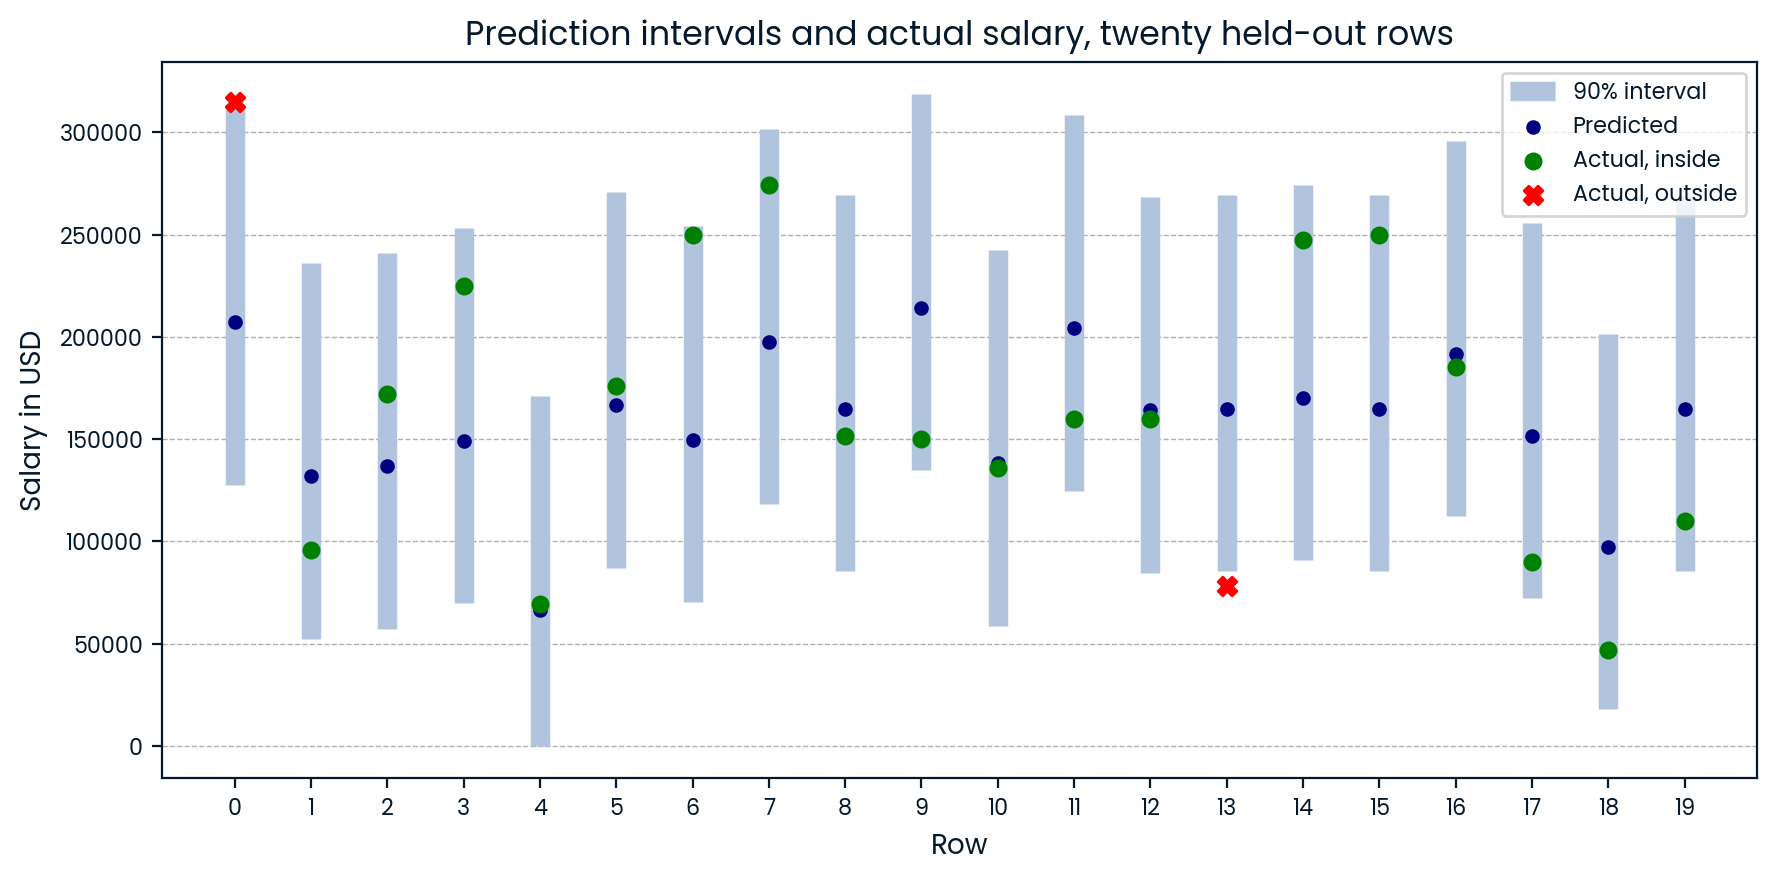

In [738]:
# Interval and actual salary for the twenty held-out rows
idx = predictions_df.index
inside = predictions_df['Inside']

plt.figure(figsize=(9, 4.5))
plt.vlines(idx, predictions_df['Low'], predictions_df['High'],
           color='lightsteelblue', linewidth=7, label='90% interval')
plt.scatter(idx, predictions_df['Predicted'], color='navy', s=18,
            label='Predicted', zorder=3)
plt.scatter(idx[inside], predictions_df.loc[inside, 'Actual'],
            color='green', s=30, label='Actual, inside', zorder=4)
plt.scatter(idx[~inside], predictions_df.loc[~inside, 'Actual'],
            color='red', s=45, marker='X', label='Actual, outside', zorder=5)

plt.xticks(ticks=idx, fontsize=8)
plt.yticks(fontsize=8)
plt.grid(True, axis='y', linestyle='--', linewidth=0.5)
plt.legend(fontsize=8)
plt.title('Prediction intervals and actual salary, twenty held-out rows', fontsize=12)
plt.xlabel('Row')
plt.ylabel('Salary in USD')
plt.tight_layout()
plt.show()

The plot shows the twenty held-out rows. The band is the interval, the dark point is the prediction, and the actual salary is green when it falls inside and a red cross when it does not. Two of the twenty are outside, which is about what a 90% interval should do. Both misses are close to the boundary rather than far outside it. With twenty rows that is an observation, not evidence.

The lower bound is cut at zero. An additive interval around a low prediction can otherwise go negative, and a negative salary is not a possible value.

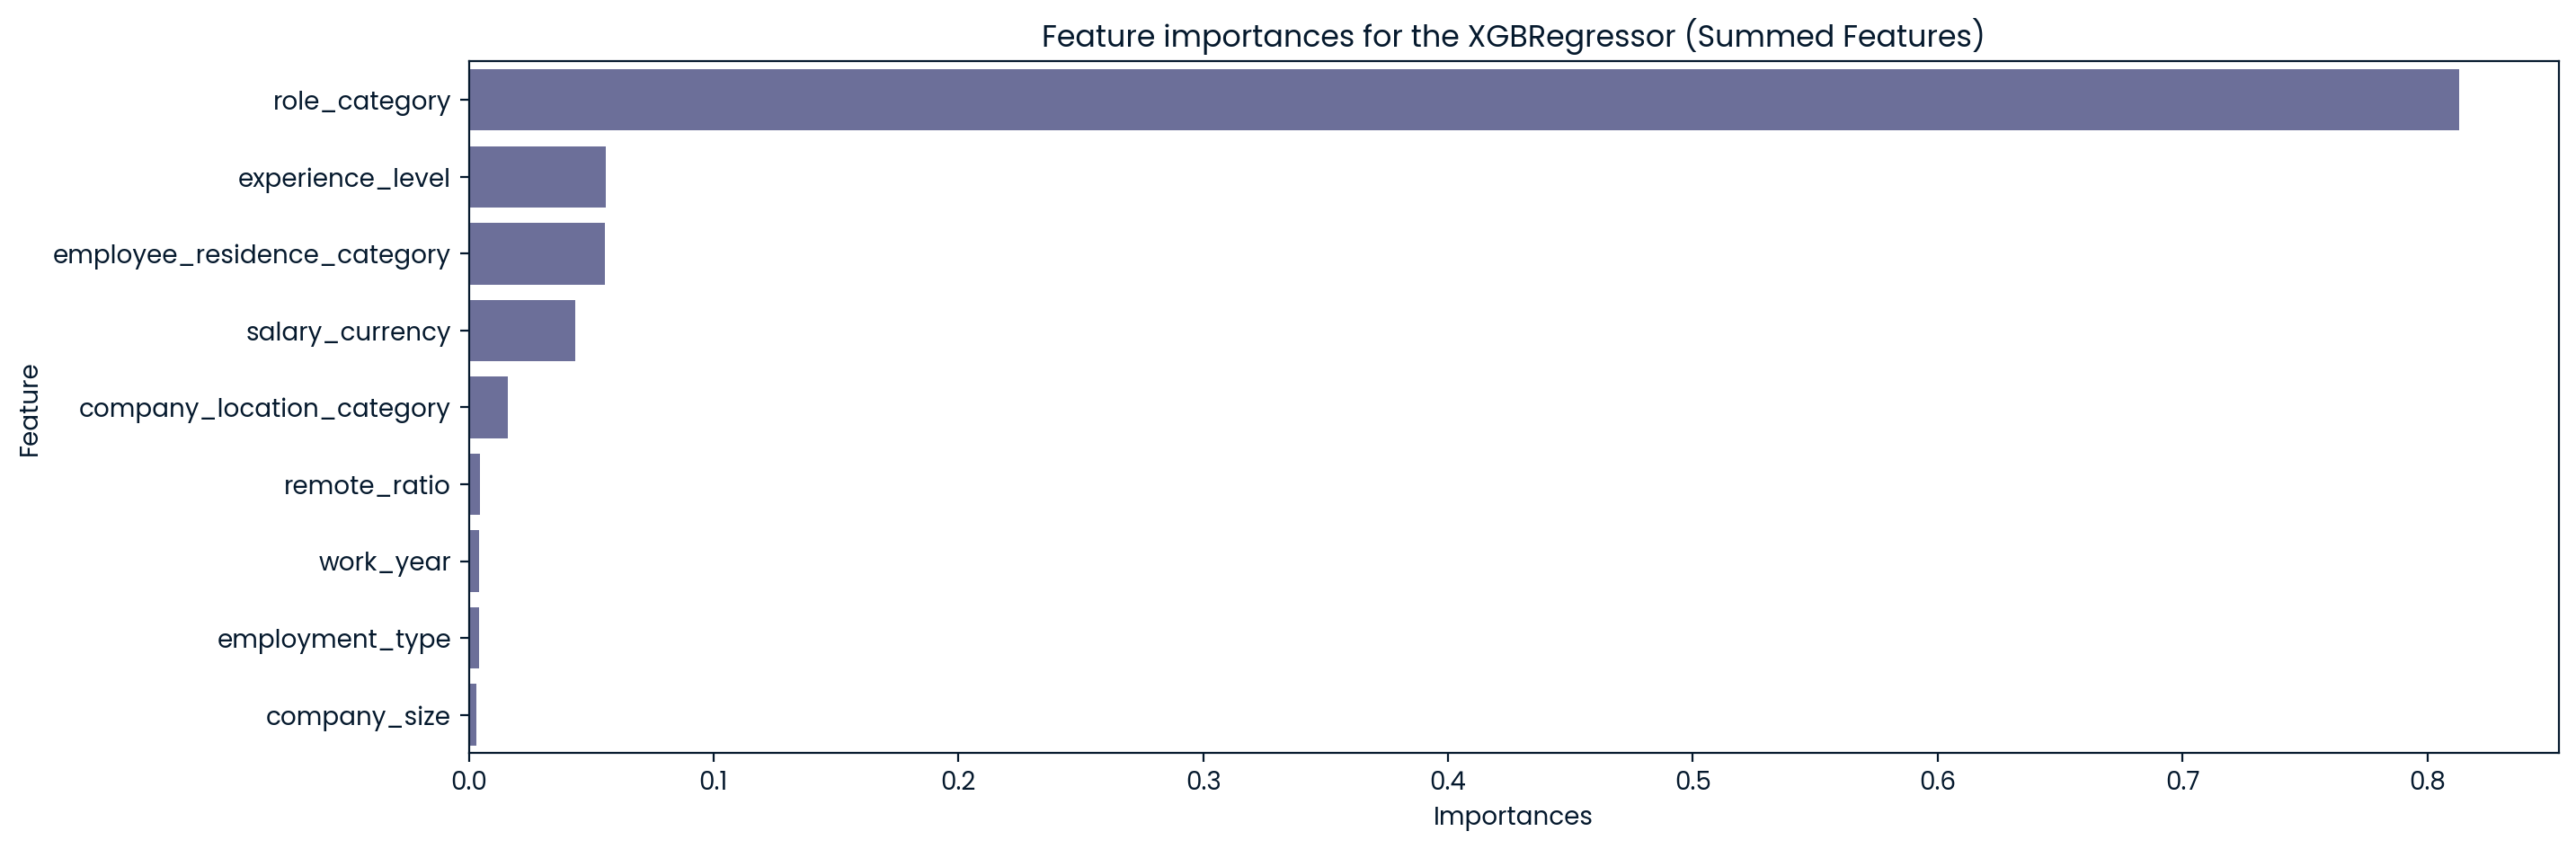

In [739]:
# Get feature importances
feature_importances = model_xgb.feature_importances_

# Create a DataFrame for better visualization
features_df = pd.DataFrame({
    'Feature': model_xgb.get_booster().feature_names,
    'Importance': feature_importances
})

filtered_work_year = features_df[features_df['Feature'].str.startswith('cat__work_year')]
filtered_experience_level = features_df[features_df['Feature'].str.startswith('cat__experience_level')]
filtered_employment_type = features_df[features_df['Feature'].str.startswith('cat__employment_type')]
filtered_salary_currency = features_df[features_df['Feature'].str.startswith('cat__salary_currency')]
filtered_remote_ratio = features_df[features_df['Feature'].str.startswith('cat__remote_ratio')]
filtered_company_size = features_df[features_df['Feature'].str.startswith('cat__company_size')]
filtered_role = features_df[features_df['Feature'].str.startswith('cat__role_category')]
filtered_employee_residence_category = features_df[features_df['Feature'].str.startswith('cat__employee_residence_category')]
filtered_company_location_category = features_df[features_df['Feature'].str.startswith('cat__company_location_category')]

sum_filtered_work_year = filtered_work_year['Importance'].sum()
sum_filtered_experience_level = filtered_experience_level['Importance'].sum()
sum_filtered_employment_type = filtered_employment_type['Importance'].sum()
sum_filtered_salary_currency = filtered_salary_currency['Importance'].sum()
sum_filtered_remote_ratio = filtered_remote_ratio['Importance'].sum()
sum_filtered_company_size = filtered_company_size['Importance'].sum()
sum_filtered_role = filtered_role['Importance'].sum()
sum_filtered_employee_residence_category = filtered_employee_residence_category['Importance'].sum()
sum_filtered_company_location_category = filtered_company_location_category['Importance'].sum()

# Create a new DataFrame with the summed importances
summed_importances = pd.DataFrame({
    'Feature': ['work_year', 'experience_level', 'employment_type', 'salary_currency', 'remote_ratio', 'company_size', 'role_category', 'employee_residence_category', 'company_location_category'],
    'Importances': [sum_filtered_work_year, sum_filtered_experience_level, sum_filtered_employment_type, sum_filtered_salary_currency, sum_filtered_remote_ratio, sum_filtered_company_size, sum_filtered_role, sum_filtered_employee_residence_category, sum_filtered_company_location_category]
})

# Replace the original features with their summed importances
importance_XGB = features_df[~features_df['Feature'].str.startswith(('cat__work_year', 'cat__experience_level', 'cat__employment_type', 'cat__salary_currency', 'cat__remote_ratio', 'cat__company_size', 'cat__role_category', 'cat__employee_residence_category', 'cat__company_location_category'))]
importance_XGB = pd.concat([importance_XGB, summed_importances], ignore_index=True)
importance_XGB = importance_XGB.sort_values(by='Importances', ascending=False)

plt.figure(figsize=(15,5))
sns.barplot(x='Importances', y='Feature', data=importance_XGB)
plt.title('Feature importances for the XGBRegressor (Summed Features)')
plt.show()

The importances are summed over the dummy columns of each original variable, which is the right way to compare them, but the result still has to be read with care. `role_category` has 47 categories and therefore 46 dummy columns, while `experience_level` has 4. A variable spread over more columns collects importance from more places, so this comparison is biased towards variables with many categories.

With that in mind: `role_category` comes first, then `experience_level` and `employee_residence_category` at a similar level. The direction is believable, because later in the notebook I show that merging role categories always makes the model worse, so the role does carry real information. But I would not read the exact gap between the three as meaningful.

In [740]:
# Model names
models_first = ['Lasso', 'Bagging with Decision Trees', 'Random Forest', 'XGBoost', 'CatBoost']

# Mean Absolute Errors
mae_values_first = [50283.47, 50118.08, 50112.70, 50139.02, 50143.20]
mae_values_second = [50281.22, 50099.12, 50074.86, 50109.77, 50124.50]
mae_values_third = [46341.44, 45771.49, 45704.72, 45569.99, 45634.99]

# Create a DataFrame
mae_df = pd.DataFrame({
    'Model': models_first,
    'MAE (3 features)': mae_values_first,
    'MAE (5 features)': mae_values_second,
    'MAE (9 features)': mae_values_third
})

mae_df

,Model,MAE (3 features),MAE (5 features),MAE (9 features)
0,Lasso,50283.47,50281.22,46341.44
1,Bagging with Decision Trees,50118.08,50099.12,45771.49
2,Random Forest,50112.70,50074.86,45704.72
3,XGBoost,50139.02,50109.77,45569.99
4,CatBoost,50143.20,50124.50,45634.99


# Going back over the choices

Everything above follows the brief. Below I go back and check the decisions I made along the way: how the countries and job titles were grouped, whether all nine features are needed, what the model is actually worth next to something much simpler, and whether it works on a year it has not seen.

## Feature engineering: were the groupings right?

Two columns had too many categories to use directly, `job_title` and `company_location`, and I grouped both by hand. The obvious question is whether a different grouping would do better.

Every test below compares encodings on the same validation rows, so the differences can be paired. The standard error of a paired difference is much smaller than the standard error of either MAE on its own, and that is what makes differences of a hundred dollars readable at all.

In [741]:
def domain_of(title):
    t = title.lower()
    if re.search(r'machine learning|deep learning|\bml\b|\bai\b|\bnlp\b|computer vision', t):
        return 'ML / AI'
    if re.search(r'data engineer|\betl\b|data infrastructure|big data|data ops|dataops', t):
        return 'Data Engineering'
    if re.search(r'data scientist|data science', t):
        return 'Data Science'
    if re.search(r'analyst|analytics|business intelligence|\bbi\b', t):
        return 'Analytics'
    if re.search(r'research|scientist', t):
        return 'Research'
    if re.search(r'engineer|developer|architect|programmer', t):
        return 'Software / Engineering'
    if re.search(r'manager|director|head|lead|chief', t):
        return 'Management'
    return 'Other'

def level_of(title):
    t = title.lower()
    if re.search(r'\bhead\b|director|chief|\bvp\b|president|principal', t):
        return 'leadership'
    if re.search(r'\blead\b|manager|\bstaff\b', t):
        return 'lead'
    if re.search(r'senior|\bsr\b', t):
        return 'senior'
    if re.search(r'junior|\bjr\b|associate|intern|entry', t):
        return 'junior'
    return 'base'

df['domain'] = df['job_title'].apply(domain_of).astype('category')
df['title_level'] = df['job_title'].apply(level_of).astype('category')

print(df['domain'].value_counts(), "\n")
print(df['title_level'].value_counts(), "\n")
print(pd.crosstab(df['domain'], df['title_level']))
print("\nmedian salary by domain x level:")
print(df.pivot_table(index='domain', columns='title_level',
                     values='salary_in_usd', aggfunc='median').round(0))


domain
Software / Engineering    12132
Analytics                 10785
Data Science               9747
Data Engineering           8119
ML / AI                    6906
Research                   4435
Management                 3243
Other                      1827
Name: count, dtype: int64 

title_level
base          52485
lead           3780
junior          674
leadership      255
Name: count, dtype: int64 

title_level              base  junior  lead  leadership
domain                                                 
Analytics               10491       7   281           6
Data Engineering         8110       0     6           3
Data Science             9720       0    17          10
ML / AI                  6802       0    60          44
Management                  0       0  3112         131
Other                    1139     644     8          36
Research                 4412      23     0           0
Software / Engineering  11811       0   296          25

median salary by domain x le

In [742]:
# --- derived features (safe to re-run) -----------------------
loc_counts = df['company_location'].value_counts()
df['loc_top'] = df['company_location'].apply(
    lambda c: c if loc_counts[c] >= 500 else 'Other').astype('category')
df['is_us'] = np.where(df['company_location'] == 'US', 'US', 'non-US')

title_counts = df['job_title'].value_counts()
df['title_top'] = df['job_title'].apply(
    lambda t: t if title_counts[t] >= 300 else 'Other').astype('category')

df['is_lead'] = np.where(df['title_level'].isin(['lead', 'leadership']), 'lead', 'ic')

# --- evaluate one encoding, keep the per-row errors ----------
def eval_encoding(cols, name):
    X_ = df[cols]
    y_ = df['salary_in_usd']
    Xtr, Xtmp, ytr, ytmp = train_test_split(X_, y_, test_size=0.3, random_state=42)
    Xv, _, yv, _ = train_test_split(Xtmp, ytmp, test_size=0.5, random_state=42)

    pipe = Pipeline([
        ('prep', ColumnTransformer([('cat',
            OneHotEncoder(drop='first', handle_unknown='ignore'), cols)])),
        ('m', xgb.XGBRegressor(colsample_bytree=0.8, learning_rate=0.1, max_depth=7,
                               n_estimators=200, subsample=1.0, random_state=42))
    ])
    pipe.fit(Xtr, ytr)
    n_cols = pipe.named_steps['prep'].transform(Xtr).shape[1]

    abs_err = np.abs(yv.values - pipe.predict(Xv))
    return ({'encoding': name,
             'columns': n_cols,
             'val MAE': round(abs_err.mean(), 1),
             'SE': round(abs_err.std(ddof=1) / np.sqrt(len(abs_err)), 1)},
            abs_err)

# --- the variants --------------------------------------------
base = ['work_year', 'experience_level', 'employment_type', 'remote_ratio', 'company_size']

variants = {
    'current: region + role_category':   base + ['company_location_category', 'role_category'],
    'country by volume + role_category': base + ['loc_top', 'role_category'],
    'country by volume + domain':        base + ['loc_top', 'domain'],
    'country by volume + domain + lead': base + ['loc_top', 'domain', 'is_lead'],
    'country by volume + top titles':    base + ['loc_top', 'title_top'],
    'US/non-US + domain':                base + ['is_us', 'domain'],
}

rows, errors = [], {}
for name, cols in variants.items():
    r, e = eval_encoding(cols, name)
    rows.append(r)
    errors[name] = e

results = pd.DataFrame(rows).sort_values('val MAE').reset_index(drop=True)
print(results.to_string(index=False))

# --- paired comparison against the best ----------------------
best_name = results.loc[0, 'encoding']
print(f"\npaired difference against '{best_name}' "
      f"(positive = worse, same {len(errors[best_name])} rows):\n")

pair_rows = []
for name in results['encoding'][1:]:
    d = errors[name] - errors[best_name]
    se_d = d.std(ddof=1) / np.sqrt(len(d))
    pair_rows.append({'encoding': name,
                      'MAE difference': round(d.mean(), 1),
                      'paired SE': round(se_d, 1),
                      'sigmas': round(d.mean() / se_d, 1)})

print(pd.DataFrame(pair_rows).to_string(index=False))

                         encoding  columns  val MAE    SE
  current: region + role_category       71  45838.5 461.6
country by volume + role_category       63  45905.7 461.4
   country by volume + top titles       37  46575.7 464.3
country by volume + domain + lead       25  46794.2 464.9
       country by volume + domain       24  47101.5 468.3
               US/non-US + domain       22  47588.2 472.1

paired difference against 'current: region + role_category' (positive = worse, same 8579 rows):

                         encoding  MAE difference  paired SE  sigmas
country by volume + role_category            67.2       63.4     1.1
   country by volume + top titles           737.2      166.6     4.4
country by volume + domain + lead           955.7      155.6     6.1
       country by volume + domain          1263.0      166.1     7.6
               US/non-US + domain          1749.6      174.1    10.1


The first test replaces the hand-made role categories with something coarser. `domain_of` sorts job titles into eight broad fields and `level_of` into seniority levels, which is the kind of grouping that looks tidy on paper.

It is clearly worse. Eight domains instead of 47 role categories costs 1,263 USD. Adding a seniority level on top brings that back only to 956, still far behind. Keeping the most frequent job titles and putting the rest into 'Other' costs 737.

For countries, grouping by volume — US, CA, GB and everything else as 'Other' — costs 67 with 63 columns instead of 71. That is inside the noise, so either version is defensible.

In [743]:
high_income = ['US','CA','GB','DE','AU','CH','NL','IE','SE','NO','DK','FI',
               'SG','JP','FR','BE','AT','NZ','IL','LU','IS','HK']

df['loc_tier'] = np.select(
    [df['company_location'] == 'US',
     df['company_location'].isin(high_income)],
    ['US', 'high income'], default='other')

df['income_tier'] = np.where(
    df['company_location'].isin(high_income), 'high income', 'other')

print(df['loc_tier'].value_counts(), "\n")

variants_loc = {
    'current: region + role_category': base + ['company_location_category', 'role_category'],
    'US / high income / other':        base + ['loc_tier', 'role_category'],
    'high income / other':             base + ['income_tier', 'role_category'],
}

rows2, errors2 = [], {}
for name, cols in variants_loc.items():
    r, e = eval_encoding(cols, name)
    rows2.append(r); errors2[name] = e

res2 = pd.DataFrame(rows2)
print(res2.to_string(index=False))

ref = 'current: region + role_category'
print(f"\npaired difference against '{ref}':\n")
for name in variants_loc:
    if name == ref:
        continue
    d = errors2[name] - errors2[ref]
    se_d = d.std(ddof=1) / np.sqrt(len(d))
    print(f"  {name:28s} {d.mean():+8.1f}  SE {se_d:6.1f}  "
          f"({d.mean()/se_d:+.1f} sigma)")

loc_tier
US             51909
high income     4333
other            952
Name: count, dtype: int64 

                       encoding  columns  val MAE    SE
current: region + role_category       71  45838.5 461.6
       US / high income / other       62  46105.1 462.5
            high income / other       61  46799.6 464.3

paired difference against 'current: region + role_category':

  US / high income / other       +266.6  SE   80.2  (+3.3 sigma)
  high income / other            +961.1  SE  107.5  (+8.9 sigma)


Grouping countries by income level instead looks sensible and is not: 266 worse at 3.3 sigma. The reason is that it puts Canada and Germany in the same bucket, and they are not paid the same. Both volume and geography beat it.

In [744]:
_, Xv_tmp, _, yv_tmp = train_test_split(
    df[['company_location']], df['salary_in_usd'], test_size=0.3, random_state=42)
Xv_loc, _, yv_loc, _ = train_test_split(Xv_tmp, yv_tmp, test_size=0.5, random_state=42)

err_best = errors[ref] if ref in errors else errors2[ref]
is_us_v = (Xv_loc['company_location'] == 'US').values

print(f"\nwhere the error lives:")
print(f"  US rows      n={is_us_v.sum():5d}  MAE {err_best[is_us_v].mean():9.1f}")
print(f"  non-US rows  n={(~is_us_v).sum():5d}  MAE {err_best[~is_us_v].mean():9.1f}")
print(f"  non-US share of total error: "
      f"{err_best[~is_us_v].sum() / err_best.sum() * 100:.1f}%")


where the error lives:
  US rows      n= 7821  MAE   46551.8
  non-US rows  n=  758  MAE   38479.4
  non-US share of total error: 7.4%


It is also worth asking where the error actually sits. The US rows have the higher MAE, 46,552 against 38,479 for the non-US rows, but there are ten times more of them, so the non-US part contributes only 7.4% of the total error. Any improvement aimed at the non-US data can move the headline number by almost nothing.

In [745]:
mismatch = (df['employee_residence'].astype(str)
            != df['company_location'].astype(str))

print(f"residence != company location: {mismatch.sum()} rows "
      f"({mismatch.mean()*100:.2f}%)\n")

print("salary by whether the employee works for a foreign company:")
print(df.groupby(mismatch)['salary_in_usd']
        .agg(n='count', median='median', mean='mean').round(0), "\n")

print("most common mismatched pairs:")
pairs = (df[mismatch]
         .groupby([df['employee_residence'], df['company_location']], observed=True)
         .size().sort_values(ascending=False).head(10))
print(pairs, "\n")

print("cross-border work among the fully remote:")
print(pd.crosstab(df['remote_ratio'], mismatch,
                  rownames=['remote_ratio'], colnames=['abroad']))

residence != company location: 138 rows (0.24%)

salary by whether the employee works for a foreign company:
           n    median      mean
False  57056  149300.0  159426.0
True     138   60000.0   75565.0 

most common mismatched pairs:
employee_residence  company_location
IN                  US                  8
AR                  US                  3
ES                  US                  3
IN                  AS                  3
DE                  US                  3
CA                  US                  3
IT                  DE                  2
IN                  AU                  2
PT                  US                  2
FR                  US                  2
dtype: int64 

cross-border work among the fully remote:
abroad        False  True 
remote_ratio              
0             44347      8
50              247     24
100           12462    106


In [746]:
check = {
    'with both location columns': base + ['company_location_category',
                                          'employee_residence_category',
                                          'role_category'],
    'company_location only':      base + ['company_location_category',
                                          'role_category'],
}

rows3, errors3 = [], {}
for name, cols in check.items():
    r, e = eval_encoding(cols, name)
    rows3.append(r); errors3[name] = e

print(pd.DataFrame(rows3).to_string(index=False))

d = errors3['company_location only'] - errors3['with both location columns']
se_d = d.std(ddof=1) / np.sqrt(len(d))
print(f"\ndropping employee_residence_category: {d.mean():+.1f}  "
      f"SE {se_d:.1f}  ({d.mean()/se_d:+.1f} sigma)")

                  encoding  columns  val MAE    SE
with both location columns       83  45829.2 461.7
     company_location only       71  45838.5 461.6

dropping employee_residence_category: +9.3  SE 29.5  (+0.3 sigma)


'employee_residence' and 'company_location' look like two different things, but in this dataset they are almost the same column: they differ in 138 rows out of 57,194, which is 0.24%. Those 138 people do have a very different median salary, 60,000 against 149,300, so the information is real — it just covers too few rows to matter.

Dropping 'employee_residence_category' costs 9.3 USD at 0.3 sigma, which is nothing. One of the two columns is enough.

In [747]:
lean = ['work_year', 'experience_level', 'employment_type', 'remote_ratio',
        'company_size', 'loc_top', 'role_category']

full = ['work_year', 'experience_level', 'employment_type', 'salary_currency',
        'remote_ratio', 'company_size', 'role_category',
        'employee_residence_category', 'company_location_category']

sets = {'full (your 9 features)': full, 'lean (7 features)': lean}

rows4, errors4 = [], {}
for name, cols in sets.items():
    r, e = eval_encoding(cols, name)
    rows4.append(r); errors4[name] = e

print(pd.DataFrame(rows4).to_string(index=False))

d = errors4['lean (7 features)'] - errors4['full (your 9 features)']
se_d = d.std(ddof=1) / np.sqrt(len(d))
print(f"\nlean vs full: {d.mean():+.1f}  SE {se_d:.1f}  ({d.mean()/se_d:+.1f} sigma)")


              encoding  columns  val MAE    SE
full (your 9 features)       95  45570.0 461.7
     lean (7 features)       63  45905.7 461.4

lean vs full: +335.7  SE 79.3  (+4.2 sigma)


The opposite test: a leaner set of seven features, 63 columns, against the full nine with 95. Here the difference is real, 336 at 4.2 sigma. So the features can be trimmed in some places but not everywhere, and the trimming has to be checked one piece at a time rather than all at once.

In [748]:
usd = df['salary_currency'] == 'USD'
us  = df['company_location'] == 'US'

print(pd.crosstab(usd, us, rownames=['paid in USD'], colnames=['company in US']), "\n")

combo = np.select(
    [usd & us, usd & ~us, ~usd & us, ~usd & ~us],
    ['USD, US company', 'USD, foreign company',
     'other currency, US company', 'other currency, foreign company'])

print("salary by currency and location:")
print(df.groupby(combo)['salary_in_usd']
        .agg(n='count', median='median', mean='mean').round(0), "\n")

print("countries that pay in USD (non-US companies):")
print(df[usd & ~us]['company_location'].value_counts().head(15), "\n")

print("US companies that pay in another currency:")
print(df[~usd & us]['salary_currency'].value_counts().head(10))

company in US  False  True 
paid in USD                
False           2638     89
True            2647  51820 

salary by currency and location:
                                     n    median      mean
USD, US company                  51820  153188.0  164685.0
USD, foreign company              2647  121200.0  134442.0
other currency, US company          89   68428.0   77587.0
other currency, foreign company   2638   66356.0   79557.0 

countries that pay in USD (non-US companies):
company_location
CA    1679
GB     200
AU     152
DE      70
IN      46
MX      40
BR      38
AR      35
EG      35
FR      32
CO      24
NZ      17
PH      17
IE      16
PL      15
Name: count, dtype: int64 

US companies that pay in another currency:
salary_currency
GBP      70
EUR      12
CAD       4
INR       2
Other     1
AUD       0
BRL       0
CHF       0
JPY       0
PHP       0
Name: count, dtype: int64


In [749]:
df['paid_in_usd'] = np.where(df['salary_currency'] == 'USD', 'USD', 'local')

curr_sets = {
    'full currency (13 categories)': full,
    'binary USD / local':            [c if c != 'salary_currency' else 'paid_in_usd'
                                      for c in full],
    'no currency at all':            [c for c in full if c != 'salary_currency'],
}

rows5, errors5 = [], {}
for name, cols in curr_sets.items():
    r, e = eval_encoding(cols, name)
    rows5.append(r); errors5[name] = e

print(pd.DataFrame(rows5).to_string(index=False))

ref5 = 'full currency (13 categories)'
print(f"\npaired against '{ref5}':")
for name in curr_sets:
    if name == ref5:
        continue
    d = errors5[name] - errors5[ref5]
    se_d = d.std(ddof=1) / np.sqrt(len(d))
    print(f"  {name:30s} {d.mean():+8.1f}  SE {se_d:6.1f}  ({d.mean()/se_d:+.1f} sigma)")

                     encoding  columns  val MAE    SE
full currency (13 categories)       95  45570.0 461.7
           binary USD / local       84  45583.0 461.5
           no currency at all       83  45829.2 461.6

paired against 'full currency (13 categories)':
  binary USD / local                +13.0  SE   21.6  (+0.6 sigma)
  no currency at all               +259.2  SE   58.5  (+4.4 sigma)


Currency is the last one. The crosstab shows that currency and location are nearly the same thing — 51,820 rows are US companies paying in USD — but not quite: 2,647 foreign companies also pay in USD, with a median of 121,200, well above foreign companies that pay in local currency. So currency does carry real information about which pay scale a person is on.

Collapsing 13 currency categories into a binary USD / local costs 13 USD at 0.6 sigma and removes 11 columns, so it is free. Dropping currency altogether costs 259 at 4.4 sigma, which is not.

In [750]:
role_stats = (df.groupby('role_category', observed=True)['salary_in_usd']
                .agg(n='count', median='median', q25=lambda s: s.quantile(.25),
                     q75=lambda s: s.quantile(.75))
                .sort_values('n', ascending=False))
print(role_stats.round(0).to_string())

                                                        n    median       q25       q75
role_category                                                                          
General Data Scientists and Applied Roles           11239  156000.0  115499.0  200000.0
Data Engineering and Related Fields                  8191  140000.0  106250.0  184920.0
General Data Analysis and Reporting                  7267  100000.0   75000.0  136150.0
General Software and Backend Engineering             6294  180000.0  141368.0  230000.0
Machine Learning and AI Engineering                  5722  185000.0  141990.0  237500.0
Specialized Engineering Roles                        4736  160000.0  120000.0  211300.0
Research-Oriented Roles                              2331  177000.0  140000.0  235400.0
General Managers                                     1556  155000.0  115000.0  205125.0
Data and Cloud Architects                            1078  154050.0  117000.0  193000.0
Business Intelligence and Analyt

In [751]:
def role_binned(min_n):
    counts = df['role_category'].value_counts()
    keep = set(counts[counts >= min_n].index)
    s = df['role_category'].astype(str)
    return s.where(s.isin(keep), 'Other small roles').astype('category')

base8 = ['work_year', 'experience_level', 'employment_type', 'remote_ratio',
         'company_size', 'loc_top', 'paid_in_usd']

sweep, errors7 = {}, {}
rows7 = []
for min_n in [0, 50, 100, 300, 600, 1000, 2000]:
    col = f'role_min{min_n}'
    df[col] = role_binned(min_n)
    k = df[col].nunique()
    name = f'min_n={min_n:<5d} ({k} categories)'
    r, e = eval_encoding(base8 + [col], name)
    rows7.append(r); errors7[name] = e

print(pd.DataFrame(rows7).to_string(index=False))

ref7 = list(errors7)[0]
print(f"\npaired against '{ref7.strip()}':")
for name in list(errors7)[1:]:
    d = errors7[name] - errors7[ref7]
    se_d = d.std(ddof=1) / np.sqrt(len(d))
    print(f"  {name:28s} {d.mean():+8.1f}  SE {se_d:6.1f}  ({d.mean()/se_d:+.1f} sigma)")

                   encoding  columns  val MAE    SE
min_n=0     (47 categories)       64  45636.6 460.8
min_n=50    (34 categories)       51  45734.6 461.7
min_n=100   (30 categories)       47  45746.8 461.3
min_n=300   (23 categories)       40  46204.3 466.4
min_n=600   (15 categories)       32  46597.1 469.5
min_n=1000  (10 categories)       27  46759.9 472.3
 min_n=2000  (8 categories)       25  46814.8 473.4

paired against 'min_n=0     (47 categories)':
  min_n=50    (34 categories)     +98.1  SE   39.3  (+2.5 sigma)
  min_n=100   (30 categories)    +110.2  SE   53.6  (+2.1 sigma)
  min_n=300   (23 categories)    +567.8  SE   98.5  (+5.8 sigma)
  min_n=600   (15 categories)    +960.5  SE  117.9  (+8.1 sigma)
  min_n=1000  (10 categories)   +1123.3  SE  133.0  (+8.4 sigma)
  min_n=2000  (8 categories)    +1178.3  SE  138.9  (+8.5 sigma)


Finally the opposite question about roles: can the 47 categories be merged? No. Every threshold makes it worse, and merging only the categories below 50 rows already costs 98 at 2.5 sigma. The small categories have extreme medians — 'Other' sits at 67,000 and 'Data Operations and Management' at 80,000 against an overall 149,000 — so even a handful of correctly placed rows helps.

The only merges that make sense are the ones where the same thing is written twice in a different word order, like 'Machine Learning and AI Specialists' and 'AI and Machine Learning Specialists'. Architects must not be merged: Data and Cloud, General and Specialized have genuinely different medians.

Five experiments with the features, and each one says the original choice was right. That is the result of this section.

## Does the model work forward in time?

Everything so far used a random split, which mixes the years: the model trains on 2024 rows and predicts other 2024 rows. That is not how a salary model would be used. In practice you know the past and predict the future, so the honest test is to train on 2020 to 2023 and predict 2024.

'work_year' is also one of the features, so I start with what it is worth.

In [752]:
df['work_year'].unique()

[2024, 2022, 2023, 2020, 2021]
Categories (5, int64): [2020, 2021, 2022, 2023, 2024]

In [753]:
PARAMS = dict(colsample_bytree=0.8, learning_rate=0.1, max_depth=7,
              n_estimators=200, subsample=1.0, random_state=42)

feats = ['work_year', 'experience_level', 'employment_type', 'remote_ratio',
         'company_size', 'loc_top', 'role_category', 'paid_in_usd']
df['work_year_num'] = df['work_year'].astype(int)

print(df.groupby('work_year', observed=True)['salary_in_usd']
        .agg(n='size', median='median').to_string(), '\n')

def build(mode):
    cats = [c for c in feats if c != 'work_year']
    if mode == 'num':
        return ColumnTransformer([
            ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cats),
            ('num', 'passthrough', ['work_year_num'])])
    if mode == 'drop':
        return ColumnTransformer([
            ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cats)])
    return ColumnTransformer([
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), feats)])

X_ = df[feats + ['work_year_num']]
y_ = df['salary_in_usd']
Xtr, Xtmp, ytr, ytmp = train_test_split(X_, y_, test_size=0.3, random_state=42)
Xv, _, yv, _ = train_test_split(Xtmp, ytmp, test_size=0.5, random_state=42)

res = {}
for label, mode in [('year as 5 categories', 'cat'), ('year as a number', 'num'),
                    ('no year', 'drop')]:
    p = Pipeline([('prep', build(mode)), ('m', xgb.XGBRegressor(**PARAMS))])
    p.fit(Xtr, ytr)
    res[label] = np.abs(yv.values - p.predict(Xv))
    print(f"{label:20s} MAE {res[label].mean():9.1f}")

for label in ['year as a number', 'no year']:
    d = res[label] - res['year as 5 categories']
    se = d.std(ddof=1) / np.sqrt(len(d))
    print(f"{label:20s} {d.mean():+8.1f}  SE {se:5.1f}  ({abs(d.mean())/se:.1f} sigma)")

# temporal split: train on 2020-2023, predict 2024
tr = df['work_year_num'] <= 2023
te = df['work_year_num'] == 2024
p = Pipeline([('prep', build('cat')), ('m', xgb.XGBRegressor(**PARAMS))])
p.fit(X_[tr], y_[tr])
e_time = np.abs(y_[te].values - p.predict(X_[te]))

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    X_, y_, train_size=int(tr.sum()), test_size=int(te.sum()), random_state=0)
p2 = Pipeline([('prep', build('cat')), ('m', xgb.XGBRegressor(**PARAMS))])
p2.fit(Xr_tr, yr_tr)
e_rand = np.abs(yr_te.values - p2.predict(Xr_te))

print(f"\ntemporal split (train {tr.sum()}, test {te.sum()})"
      f"  MAE {e_time.mean():9.1f}  SE {e_time.std(ddof=1)/np.sqrt(len(e_time)):.1f}")
print(f"random split of the same size          "
      f"  MAE {e_rand.mean():9.1f}  SE {e_rand.std(ddof=1)/np.sqrt(len(e_rand)):.1f}")

               n    median
work_year                 
2020          75   79833.0
2021         218   83872.0
2022        1659  131300.0
2023        8522  145000.0
2024       46720  150000.0 

year as 5 categories MAE   45661.1
year as a number     MAE   45653.2
no year              MAE   45791.4
year as a number         -7.9  SE  21.1  (0.4 sigma)
no year                +130.3  SE  44.7  (2.9 sigma)

temporal split (train 10474, test 46720)  MAE   49862.8  SE 220.1
random split of the same size            MAE   45736.0  SE 191.2


First the distribution. 2024 holds 46,720 of the 57,194 rows, which is 82%, while 2020 and 2021 together hold 293 rows, half a percent. Any statement about a trend since 2020 rests on 75 observations.

The feature itself is worth almost nothing. Year as a number or as five categories makes no difference at all, 0.4 sigma, and removing it completely costs 130 USD, which is 0.3% of the error. The year is already contained in the other features.

The split is a different story. Training on 2020 to 2023 and predicting 2024 gives 49,863 against 45,736 for a random split of the same size. The gap is 4,127, about 14 standard errors. The number this notebook reports everywhere else is obtained under conditions that do not hold in practice.

In [754]:
p_t = Pipeline([('prep', build('cat')), ('m', xgb.XGBRegressor(**PARAMS))])
p_t.fit(X_[tr], y_[tr])
pred24 = p_t.predict(X_[te]); true24 = y_[te].values
resid = true24 - pred24

print(f"mean signed residual {resid.mean():+9.1f}")
print(f"median prediction {np.median(pred24):9.1f}   median actual {np.median(true24):9.1f}")

shift = np.median(resid)
e_fix = np.abs(true24 - (pred24 + shift))
print(f"\nno correction     MAE {np.abs(resid).mean():9.1f}")
print(f"shifted by {shift:+8.0f}  MAE {e_fix.mean():9.1f}")
print(f"random split      MAE   45736.0")

mean signed residual   +8329.2
median prediction  158907.2   median actual  150000.0

no correction     MAE   49862.8
shifted by     +680  MAE   49859.0
random split      MAE   45736.0


The obvious explanation would be inflation: older data, lower salaries, the model underpredicts, and a constant correction fixes it. It does not. Shifting every prediction by the median residual turns 49,862.8 into 49,859.0, which is nothing.

The residuals also contradict each other in an interesting way. The mean residual is +8,329, so on average the model underpredicts, but the median prediction is 158,907 against a true median of 150,000, so in the middle it overpredicts. That happens when the residuals have a long right tail: a minority of very high real salaries that the model badly underestimates pulls the mean up, while the bulk is slightly overestimated.

So what changed between 2023 and 2024 is not the level but the relationship between the features and the pay.

In [755]:
print("residual quantiles 5/25/50/75/95:",
      np.round(np.percentile(resid, [5, 25, 50, 75, 95]), 0))

def key(mask):
    return (df.loc[mask, 'experience_level'].astype(str) + '|' +
            df.loc[mask, 'role_category'].astype(str) + '|' +
            df.loc[mask, 'loc_top'].astype(str))

seen = key(te).isin(set(key(tr))).values
print(f"\nprofile seen before 2024  n={seen.sum():6d}  "
      f"MAE {np.abs(resid[seen]).mean():9.1f}")
print(f"profile new               n={(~seen).sum():6d}  "
      f"MAE {np.abs(resid[~seen]).mean():9.1f}")

piv = (df[df['work_year_num'] >= 2023]
       .pivot_table(index='experience_level', columns='work_year_num',
                    values='salary_in_usd', aggfunc=['median', 'size']))
print('\n', piv.to_string())

residual quantiles 5/25/50/75/95: [-81036. -34478.    680.  44013. 123366.]

profile seen before 2024  n= 41564  MAE   49274.2
profile new               n=  5156  MAE   54608.1

                     median            size       
work_year_num         2023      2024  2023   2024
experience_level                                 
EN                 80000.0   94000.0   465   4584
EX                185000.0  200000.0   243    897
MI                115000.0  136000.0  1717  14706
SE                157550.0  166000.0  6097  26533


Two more checks. Rows whose combination of experience level, role and country already appeared before 2024 have MAE 49,274; rows with a new combination have 54,608. The new ones are worse, but there are only 5,156 of them against 41,564, so novelty explains a small part of the gap and not the main part.

The table at the bottom is where it becomes clear. Between 2023 and 2024 the median salary rose inside every experience level: EN by 17.5%, MI by 18.3%, SE by 5.4%, EX by 8.1%.

In [756]:
sh = (df[df['work_year_num'] >= 2023]
      .groupby(['work_year_num', 'experience_level'], observed=True).size()
      .unstack(0))
print((sh / sh.sum() * 100).round(1).to_string())

work_year_num     2023  2024
experience_level            
EN                 5.5   9.8
EX                 2.9   1.9
MI                20.1  31.5
SE                71.5  56.8


And yet the overall median went from 145,000 to 150,000, which is only +3.4%.

Both things are true at once because the composition of the sample changed. The share of SE fell from 71.5% to 56.8%, MI rose from 20.1% to 31.5%, EN from 5.5% to 9.8%. More junior people entered the data and pulled the overall median down, while everybody was being paid more.

This is Simpson's paradox. It also means the sentence near the top of this notebook, that the median salary increased each year, is true but says almost nothing about pay.

In [757]:
def wmedian(v, w):
    o = np.argsort(v); v, w = np.asarray(v)[o], np.asarray(w)[o]
    return v[np.searchsorted(np.cumsum(w) / w.sum(), 0.5)]

d23 = df[df['work_year_num'] == 2023]
d24 = df[df['work_year_num'] == 2024]
p23 = d23['experience_level'].value_counts(normalize=True)
p24 = d24['experience_level'].value_counts(normalize=True)
w = d24['experience_level'].map(p23 / p24).values

m23 = d23['salary_in_usd'].median()
m24 = d24['salary_in_usd'].median()
m24s = wmedian(d24['salary_in_usd'].values, w)
print(f"median 2023                {m23:9.0f}")
print(f"median 2024 as is          {m24:9.0f}   {(m24/m23-1)*100:+5.1f}%")
print(f"median 2024 in 2023 mix    {m24s:9.0f}   {(m24s/m23-1)*100:+5.1f}%")

# and check whether the country mix shifted as well
cl = (df[df['work_year_num'] >= 2023]
      .groupby(['work_year_num', 'loc_top'], observed=True).size().unstack(0))
print('\n', (cl / cl.sum() * 100).round(1).to_string())

median 2023                   145000
median 2024 as is             150000    +3.4%
median 2024 in 2023 mix       159000    +9.7%

 work_year_num  2023  2024
loc_top                  
CA              2.3   3.4
GB              4.5   2.4
Other           4.0   2.5
US             89.2  91.7


In [758]:
k23 = d23['experience_level'].astype(str) + '|' + d23['loc_top'].astype(str)
k24 = d24['experience_level'].astype(str) + '|' + d24['loc_top'].astype(str)
q23, q24 = k23.value_counts(normalize=True), k24.value_counts(normalize=True)

wj = (k24.map(q23) / k24.map(q24)).fillna(0).values
m24j = wmedian(d24['salary_in_usd'].values, wj)

print(f"median 2023                              {m23:9.0f}")
print(f"2024 as is                               {m24:9.0f}   {(m24/m23-1)*100:+5.1f}%")
print(f"2024 in the 2023 mix, by level           {m24s:9.0f}   {(m24s/m23-1)*100:+5.1f}%")
print(f"2024 in the 2023 mix, by level + country {m24j:9.0f}   {(m24j/m23-1)*100:+5.1f}%")
print(f"\n2023 cells present in 2024: "
      f"{q23.index.isin(q24.index).mean()*100:.0f}%  "
      f"2024 rows with non-zero weight: {(wj>0).mean()*100:.0f}%")

median 2023                                 145000
2024 as is                                  150000    +3.4%
2024 in the 2023 mix, by level              159000    +9.7%
2024 in the 2023 mix, by level + country    156300    +7.8%

2023 cells present in 2024: 100%  2024 rows with non-zero weight: 100%


To get the real figure the 2024 data has to be reweighted to the 2023 composition. This is direct standardization, the same idea as a fixed-basket price index or an age-standardized mortality rate: hold the mix constant and let only the thing you are measuring change.

Standardized by experience level the growth is +9.7%. Adding country brings it to +7.8%, because the two compositions pull in opposite directions — the share of senior people fell, which hid the growth, while the share of US rows rose from 89.2% to 91.7%, which inflated it. Both cells report 100% coverage, so nothing was dropped in the reweighting.

The honest figure is about +7.8% rather than +3.4%.

Two things have to be said next to it. First, these are different survey responses each year and not the same people, so the correct wording is not 'salaries grew' but 'in this data the same position is reported higher in 2024 than in 2023'. Second, all amounts are nominal. No inflation adjustment was made, so the real growth is smaller than 7.8% by whatever inflation was over the period.

The country shares are worth noticing for another reason. The dataset is 89 to 92 percent US and became more so over time. This is not 'data salaries worldwide'. It is data salaries in the United States with a ten percent tail.

## What is the model actually worth?

A MAE of 45,661 means nothing on its own. The question is what to compare it with. The usual comparison is other models, and above I compared five of them, but they all agree with each other, so that tells me little. A better comparison is something much simpler than a model.

Below I build four baselines. The simplest one predicts the same number for everybody. The others are pivot tables: group the training rows by experience level, then by experience level and role, then by experience level, role and country, take the median of each group, and look the new row up in the table. No fitting, no hyperparameters, four lines of pandas.

The validation rows are the same ones the models were evaluated on, so the numbers can be compared directly.

In [759]:
Xb = df[['experience_level', 'loc_top', 'role_category']]
yb = df['salary_in_usd']
Xb_tr, Xb_tmp, yb_tr, yb_tmp = train_test_split(Xb, yb, test_size=0.3, random_state=42)
Xb_v, _, yb_v, _ = train_test_split(Xb_tmp, yb_tmp, test_size=0.5, random_state=42)
fallback = yb_tr.median()

def report(name, pred):
    pred = pd.to_numeric(pd.Series(np.asarray(pred, dtype=object)),
                         errors='coerce').fillna(fallback).values
    err = np.abs(yb_v.values - pred)
    print(f"{name:38s} MAE {err.mean():9.1f}   {err.mean()/yb_v.mean()*100:5.1f}% of the mean")

report("constant: median of training set", np.full(len(yb_v), fallback))

m1 = yb_tr.groupby(Xb_tr['experience_level'], observed=True).median()
report("median by experience level", Xb_v['experience_level'].map(m1).values)

k_tr = Xb_tr['experience_level'].astype(str) + '|' + Xb_tr['role_category'].astype(str)
k_v  = Xb_v['experience_level'].astype(str)  + '|' + Xb_v['role_category'].astype(str)
report("median by level x role", k_v.map(yb_tr.groupby(k_tr).median()).values)

k3_tr = k_tr + '|' + Xb_tr['loc_top'].astype(str)
k3_v  = k_v  + '|' + Xb_v['loc_top'].astype(str)
report("median by level x role x country", k3_v.map(yb_tr.groupby(k3_tr).median()).values)

mae_model_8 = res['year as 5 categories'].mean()
print(f"{'XGBoost, 8 features':38s} MAE {mae_model_8:9.1f}   "
      f"{mae_model_8/yb_v.mean()*100:5.1f}% of the mean")

constant: median of training set       MAE   54906.2    34.4% of the mean
median by experience level             MAE   51604.2    32.3% of the mean
median by level x role                 MAE   47245.6    29.6% of the mean
median by level x role x country       MAE   45553.6    28.6% of the mean
XGBoost, 8 features                    MAE   45661.1    28.6% of the mean


The constant baseline, predicting the training median for everybody, gives 54,906. The model gives 45,661, so everything the modelling adds is worth about 17% over a single number.

Then the pivot tables. Experience level alone: 51,604. Experience level and role: 47,246. Experience level, role and country: 45,554, which is lower than the model.

A table of medians over three columns comes out ahead of a tuned gradient boosting model on eight.

In [760]:
assert (yv.index == yb_v.index).all(), "validation rows do not match"

pm = Pipeline([('prep', build('cat')), ('m', xgb.XGBRegressor(**PARAMS))])
pm.fit(Xtr, ytr)
e_model = np.abs(yv.values - pm.predict(Xv))

def errs(pred):
    s = pd.to_numeric(pd.Series(np.asarray(pred, dtype=object)), errors='coerce')
    return np.abs(yb_v.values - s.fillna(fallback).values), s.isna().mean()

e_tab, miss3 = errs(k3_v.map(yb_tr.groupby(k3_tr).median()).values)
d = e_tab - e_model
print(f"table minus model {d.mean():+8.1f}  SE {d.std(ddof=1)/np.sqrt(len(d)):.1f}"
      f"  ({abs(d.mean())/(d.std(ddof=1)/np.sqrt(len(d))):.1f} sigma)")
print(f"rows with no matching cell in the table: {miss3*100:.1f}%")

k4_tr = k3_tr + '|' + df.loc[Xb_tr.index, 'paid_in_usd'].astype(str)
k4_v  = k3_v  + '|' + df.loc[Xb_v.index,  'paid_in_usd'].astype(str)
e_tab4, miss4 = errs(k4_v.map(yb_tr.groupby(k4_tr).median()).values)
print(f"\ntable on four features MAE {e_tab4.mean():9.1f}"
      f"   no cell {miss4*100:.1f}%")

table minus model   -107.4  SE 153.9  (0.7 sigma)
rows with no matching cell in the table: 0.1%

table on four features MAE   45399.9   no cell 0.2%


The paired comparison gives a difference of −107 with a standard error of 154, which is 0.7 sigma. So the correct statement is not that the table wins, but that the two are indistinguishable.

The comparison is also not generous to the table. The model has eight features against three, and its hyperparameters were chosen by a grid search on this same data, while the table has no parameters at all. With all of that in its favour the model still does not come out ahead.

Only 0.1% of the validation rows have no matching cell in the table and fall back to the overall median, so the table is not quietly failing on part of the data. Adding a fourth column, whether the salary is paid in USD, brings it to 45,400.

In [761]:
rows = []
for seed in [0, 1, 7, 42, 2024]:
    Xa, Xt, ya, yt = train_test_split(X_, y_, test_size=0.3, random_state=seed)
    Xv2, _, yv2, _ = train_test_split(Xt, yt, test_size=0.5, random_state=seed)

    p = Pipeline([('prep', build('cat')), ('m', xgb.XGBRegressor(**PARAMS))])
    p.fit(Xa, ya)
    em = np.abs(yv2.values - p.predict(Xv2))

    def k(idx):
        return (df.loc[idx, 'experience_level'].astype(str) + '|' +
                df.loc[idx, 'role_category'].astype(str) + '|' +
                df.loc[idx, 'loc_top'].astype(str) + '|' +
                df.loc[idx, 'paid_in_usd'].astype(str))
    pr = pd.to_numeric(k(Xv2.index).map(ya.groupby(k(Xa.index)).median()),
                       errors='coerce').fillna(ya.median())
    et = np.abs(yv2.values - pr.values)

    d = et - em
    rows.append({'seed': seed, 'model': round(em.mean(), 1),
                 'table': round(et.mean(), 1), 'diff': round(d.mean(), 1),
                 'sigma': round(abs(d.mean()) / (d.std(ddof=1)/np.sqrt(len(d))), 1)})

r = pd.DataFrame(rows)
print(r.to_string(index=False))
print(f"\nmean difference across seeds {r['diff'].mean():+.1f}, "
      f"spread {r['diff'].std(ddof=1):.1f}")

 seed   model   table   diff  sigma
    0 45132.3 44806.4 -325.9    2.1
    1 44974.1 44947.9  -26.2    0.2
    7 45492.1 45250.6 -241.5    1.5
   42 45661.1 45399.9 -261.2    1.8
 2024 45484.0 45199.2 -284.8    1.9

mean difference across seeds -227.9, spread 117.1


One split is not enough for a claim of this size, so I repeat it on five random splits. The table wins on all five, by between 26 and 326, with a mean of 228 and a spread of 117 across the splits.

The sign is stable, so the difference is probably real, but it is 0.5% and I would not make more of it than that. A formal test on these five numbers would overstate the confidence, because the five training sets overlap heavily and are not independent samples.

The first column is more interesting. The model's own MAE moves from 44,974 to 45,661 depending only on which rows happened to land in the validation set, a range of nearly 700. The difference between gradient boosting and a pivot table is 228. The choice of random seed moves the result three times more than the choice of method.

In [762]:
orig9 = ['work_year', 'experience_level', 'employment_type', 'remote_ratio',
         'company_size', 'company_location', 'employee_residence_category',
         'role_category', 'salary_currency']
final8 = feats

out = []
for seed in [0, 7, 42]:
    for name, cols in [('original 9', orig9), ('final 8', final8)]:
        Xa, Xt, ya, yt = train_test_split(df[cols], y_, test_size=0.3, random_state=seed)
        Xv2, _, yv2, _ = train_test_split(Xt, yt, test_size=0.5, random_state=seed)
        pp = Pipeline([('prep', ColumnTransformer([('cat',
                OneHotEncoder(drop='first', handle_unknown='ignore'), cols)])),
                       ('m', xgb.XGBRegressor(**PARAMS))])
        pp.fit(Xa, ya)
        out.append({'seed': seed, 'set': name,
                    'columns': pp.named_steps['prep'].transform(Xa).shape[1],
                    'MAE': round(np.abs(yv2.values - pp.predict(Xv2)).mean(), 1)})
print(pd.DataFrame(out).pivot(index='seed', columns='set',
                              values=['columns', 'MAE']).to_string())

     columns                 MAE           
set  final 8 original 9  final 8 original 9
seed                                       
0       64.0      161.0  45132.3    45013.4
7       64.0      161.0  45492.1    45435.2
42      64.0      164.0  45661.1    45548.6


The last check is the feature set itself. The nine original features give 161 one-hot columns, the eight I settled on give 64. The original is slightly better on all three splits, by 96 on average.

So reducing the feature set is not free, and I should not claim that it is. It costs about 96 USD, or 0.2%. I keep the smaller set anyway: the cost is three times smaller than the variation of the metric between splits, the model has two and a half times fewer columns, and in any case the whole model is matched by a pivot table, so the argument about which features it uses is secondary.

# What this project came to

I set out to predict data salaries, and I did build a model: XGBoost on nine features, MAE 45,570 on validation and 45,597 on the test set. The mean salary in the data is 159,224, so the error is 29% of it. But the more useful result came from checking that model rather than from building it.

**The model is matched by a pivot table.** A table of median salaries grouped by experience level, role and country reaches 45,554 on the same validation rows. The paired difference is 0.7 sigma on one split, and across five splits the table is ahead by 228 on average, which is 0.5%. Everything the gradient boosting adds over `groupby().median()` sits inside the noise of the measurement. All the features are categorical, the useful interactions are low order, and there are enough rows to estimate each cell directly, so there is very little left for the algorithm to find.

**Nothing I chose matters as much as the random seed.**

| what changes | effect on MAE |
|---|---|
| the random split (seed) | about 690 |
| Lasso instead of a tree model | about 770 |
| between the four tree models | about 200 |
| the model instead of a pivot table | about 228 |
| nine features instead of eight | about 96 |
| the full grid instead of ten random draws | about 38 |

The full grid search for XGBoost is 540 fits. Ten random draws with three folds is 30 fits and lands 38 USD away. Reading the table from the bottom up, the steps that take the most work matter the least.

**The salary growth in this data is not what the raw numbers say.** Between 2023 and 2024 the median salary rose inside every experience level, by 5% to 18%, while the overall median rose by only 3.4%. The sample became more junior, and that hid the growth. Standardizing 2024 to the 2023 composition gives about +7.8%. This is Simpson's paradox, and without the standardization the obvious reading of the yearly boxplots is wrong.

**The prediction interval was wrong, and now it is measured.** The old `prediction ± MAE` contained the true salary 58.8% of the time. An interval built from the residual quantiles contains it 89.4% of the time against a nominal 90%, and it is twice as wide. Calibrating it separately inside each quarter of the predictions keeps the coverage near 90% in every group, instead of swinging between 97% and 82%.

## What this model cannot do

The data is 89 to 92 percent United States, and that share grew over time. This is not a worldwide salary model.

82% of the rows are from 2024, and 2020 and 2021 together hold 293 rows. Any statement about a trend since 2020 rests on 75 observations.

The model does not transfer forward in time. Trained on 2020 to 2023 and asked about 2024 it gives 49,863 instead of 45,736, and a constant correction does not repair it. What changed between the years is the relationship between the features and the pay, not only the level.

All amounts are nominal. No inflation adjustment was made, so the year on year growth above is overstated by whatever inflation was over the period.

The rows are survey responses, not the same people followed over time. The honest wording is always 'what is reported in this data', never 'what people are paid'.

## If I continued

I would stop improving the model. With this set of features it already performs at the level a lookup table reaches, so the way forward is more information per row — the job description, the industry, the company — and not a better algorithm on the same nine columns.